# Principal Component Analysis and Linear Discriminant Analysis for Dimensionality Reduction

Practical 5 made a linear model simpler: fewer predictors (subset selection) or smaller coefficients (ridge and the
lasso). This practical makes the **data** simpler instead.

Look at the datasets we have used so far. A wine is described by 13 chemical measurements, a tumour by 30
measurements of its cells, a handwritten digit by 64 pixels. Many of these columns carry **overlapping
information**: in Practical 5, total cholesterol and LDL cholesterol had a correlation of 0.9, so knowing one told you
most of the other. When columns overlap like this, the rows do not really fill all $p$ dimensions. They lie close to a
flat surface of much lower dimension, the way a sheet of paper lying in a room is a two-dimensional object in a
three-dimensional space.

**Dimensionality reduction** finds such a surface and describes every row by its position on it: a few new numbers
instead of $p$ old ones. Each new number is a **weighted mixture of the old columns**. This practical builds the two
classical ways of choosing the weights:

- **Principal Component Analysis (PCA)** looks only at the features $X$. It chooses the new axes so that the data
  are as **spread out** as possible along them. It never looks at the labels.
- **Linear Discriminant Analysis (LDA)** also uses the labels $y$. It chooses the new axes so that the **classes are
  as far apart as possible** compared with the spread inside each class.

A simple picture to keep in mind: you want to photograph a three-dimensional object with a flat camera. PCA turns
the object until the photograph looks as **big** as possible. LDA turns it until the **groups** in it look as
**separate** as possible. Usually those are two different photographs, and this practical shows you both.

The practical has nine parts:

0. **Three standard datasets**: Wine (the main one), Breast Cancer (two classes) and Digits (images).
1. **Lock away the test set**, standardise, and look at which columns are correlated.
2. **PCA by eigen-decomposition of the covariance matrix**, from scratch, checked against `PCA`.
3. **PCA by the singular value decomposition (SVD)**: the same answer by a second, more accurate road.
4. **The scree curve**: how much variance each component explains, and how many components to keep.
5. **Projection and reconstruction**: keep $k$ components, rebuild the data from them, and measure what is lost.
   On the Digits data you will *see* the loss.
6. **Fisher's LDA for two classes**: the criterion, the formula, and a picture of why PCA can pick the wrong direction.
7. **LDA for more than two classes**, checked against `LinearDiscriminantAnalysis` and SciPy.
8. **PCA and LDA compared** on the same data: the two projections side by side, and the accuracy of a classifier after
   each reduction, with everything refitted inside the cross-validation folds of Practical 4.

**What is new in the toolbox.** As in Practicals 4 and 5, every method is written **from scratch** in NumPy and then
checked against a library: `PCA` from `sklearn.decomposition`, `LinearDiscriminantAnalysis` from
`sklearn.discriminant_analysis`, and `scipy.linalg.eigh`. The classifier of Part 8 (k-nearest neighbours) and the
splitting tools come from scikit-learn, because they were already built and checked in Practicals 3 and 4.

**Vocabulary used throughout**

| term | meaning in this notebook |
|-|-|
| **dimension** | one column of $X$; a dataset with $p$ columns lives in a $p$-dimensional space |
| **dimensionality reduction** | replacing the $p$ columns by $k < p$ new columns, each a weighted mixture of the old ones |
| **direction** | a vector $w$ of length 1; projecting a row $x$ onto it gives the single number $w^{\top}x$ |
| **projection** | the new coordinates of a row on the chosen directions |
| **covariance matrix** | the $p \times p$ table of covariances between every pair of columns |
| **eigenvector, eigenvalue** | a direction $v$ that a matrix only stretches, $Cv = \lambda v$; $\lambda$ is the stretch factor |
| **principal direction** | an eigenvector of the covariance matrix: a direction along which the data spread a lot |
| **principal component (score)** | the coordinate of a row along a principal direction |
| **explained variance** | the variance of the data along one principal direction (its eigenvalue) |
| **scree plot** | the eigenvalues plotted from the largest to the smallest |
| **reconstruction** | mapping the $k$ scores of a row back to the original $p$ columns |
| **within-class scatter** | how spread out each class is around its own mean |
| **between-class scatter** | how spread out the class means are around the overall mean |
| **discriminant direction** | a direction found by LDA, along which the classes are well separated |
| **supervised / unsupervised** | uses the labels (LDA) / does not use the labels (PCA) |

**Notation**

| symbol | meaning |
|-|-|
| $n$, $p$ | number of rows and number of columns of the data matrix |
| $Z$ | the standardised data matrix (every column has mean 0 and standard deviation 1) |
| $C = \frac{1}{n-1} Z^{\top}Z$ | the covariance matrix of $Z$ ($p \times p$) |
| $v_j$, $\lambda_j$ | the $j$-th principal direction and its eigenvalue, $\lambda_1 \ge \lambda_2 \ge \dots \ge \lambda_p$ |
| $V_k$ | the $p \times k$ matrix whose columns are the first $k$ principal directions |
| $T_k = Z V_k$ | the scores: every row described by $k$ numbers |
| $C$ (in Parts 6 to 8) | also used for the number of classes, as in "$C - 1$ directions"; the meaning is always clear from the text |
| $\mu_c$, $n_c$, $\mu$ | the mean and size of class $c$, and the overall mean |
| $S_W$, $S_B$ | the within-class and between-class scatter matrices ($p \times p$) |

In [35]:
import numpy as np                                   # arrays and all the numerical work
import pandas as pd                                  # tables, so results print with readable labels
import matplotlib.pyplot as plt                      # every plot in this notebook
import scipy.linalg                                  # one check in Part 7 (the generalised eigenproblem)

from sklearn.datasets import load_wine, load_breast_cancer, load_digits   # three standard public datasets
from sklearn.model_selection import train_test_split, StratifiedKFold    # hold-out split and stratified K-fold
from sklearn.preprocessing import StandardScaler     # mean 0, std 1 (used inside the library pipelines)
from sklearn.pipeline import make_pipeline           # chain "standardise, reduce, classify" into one model
from sklearn.neighbors import KNeighborsClassifier   # the classifier of Part 8 (Practical 4)

# Library versions of everything we build from scratch. They are used ONLY to check our own code.
from sklearn.decomposition import PCA                # library PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis  # library LDA
from sklearn.model_selection import cross_val_score  # library CV loop

%matplotlib inline

rng = np.random.default_rng(42)                      # one seeded generator for the random numbers of Part 6
np.set_printoptions(precision=4, suppress=True)      # 4 decimals, no scientific notation
pd.set_option("display.precision", 4)                # the same for DataFrames
pd.set_option("display.width", 150)                  # wide tables print on one line
plt.rcParams["figure.figsize"] = (6, 4)              # default plot size in inches
plt.rcParams["figure.dpi"] = 300                     # default resolution

**Line by line**

- The first three imports are the same as in every practical so far.
- `import scipy.linalg` : SciPy is the scientific library that NumPy's linear algebra is built on. We need it once,
  in Part 7, to check our LDA against its solver for the *generalised* eigenvalue problem.
- `load_wine`, `load_breast_cancer`, `load_digits` : three classic datasets shipped inside scikit-learn, so they load
  without an internet connection.
- `train_test_split` and `StratifiedKFold` : the stratified hold-out split and stratified K-fold of Practical 4. In
  Practical 4 our own functions gave exactly the same rows, so here we simply use the library versions.
- `StandardScaler`, `make_pipeline`, `KNeighborsClassifier` : the scaler, the pipeline maker and the k-NN classifier
  of Practical 4. They are used in Part 8.
- The block under the comment brings in the library versions of what we build ourselves. Read the comment: they are
  used only to **check** our functions.
- `rng = np.random.default_rng(42)` : the seeded generator of the earlier practicals. It is used in Part 6 to simulate
  data. Run the notebook from top to bottom (*Kernel, Restart & Run All*) to get exactly the numbers quoted in the
  text.

# Part 0: Three standard datasets

## 0a. The main dataset: Wine

The Wine data come from the UCI Machine Learning Repository. Each row is one wine, grown in the same region of Italy
but made from one of **three cultivars** (grape varieties): that is the class we will try to recognise. For every wine
a chemical analysis measured 13 quantities: the alcohol content, malic acid, ash and its alkalinity, magnesium, two
kinds of phenols, flavanoids, proanthocyanins, colour intensity, hue, the ratio OD280/OD315 (a measure of protein
content) and the amino acid proline.

In the language of Practical 1: a feature matrix $X$ of order $178 \times 13$, a label vector $y$ of length 178, and a
three-class classification problem.

In [36]:
wine = load_wine()                                   # a "Bunch": a dictionary-like object holding the dataset
X_wine = wine.data                                   # (178, 13) feature matrix, one wine per row
y_wine = wine.target                                 # (178,) class labels 0, 1, 2: the three cultivars
class_names_wine = np.array(["cultivar 1", "cultivar 2", "cultivar 3"])   # readable names for the classes
short_names = np.array(["alcohol", "malic acid", "ash", "alcalinity", "magnesium", "total phenols",  # short names
                        "flavanoids", "nonflav. phenols", "proanthocyanins", "colour intensity",
                        "hue", "OD280/OD315", "proline"])                   # shorter column names for plots

print("feature matrix X :", X_wine.shape)
print("label vector y   :", y_wine.shape)
print("wines per class  :", {str(c): int(m) for c, m in zip(class_names_wine, np.bincount(y_wine))})

summary_wine = pd.DataFrame({"mean": X_wine.mean(axis=0), "std": X_wine.std(axis=0),  # statistics per column
                             "min": X_wine.min(axis=0), "max": X_wine.max(axis=0)},
                            index=short_names)       # one row per column of X
summary_wine.T                                       # transposed: the 13 columns run across the page

feature matrix X : (178, 13)
label vector y   : (178,)
wines per class  : {'cultivar 1': 59, 'cultivar 2': 71, 'cultivar 3': 48}


,alcohol,malic acid,ash,alcalinity,magnesium,total phenols,flavanoids,nonflav. phenols,proanthocyanins,colour intensity,hue,OD280/OD315,proline
mean,13.0006,2.3363,2.3665,19.4949,99.7416,2.2951,2.0293,0.3619,1.5909,5.0581,0.9574,2.6117,746.8933
std,0.8095,1.1140,0.2736,3.3302,14.2423,0.6241,0.9960,0.1241,0.5707,2.3118,0.2279,0.7080,314.0217
min,11.0300,0.7400,1.3600,10.6000,70.0000,0.9800,0.3400,0.1300,0.4100,1.2800,0.4800,1.2700,278.0000
max,14.8300,5.8000,3.2300,30.0000,162.0000,3.8800,5.0800,0.6600,3.5800,13.0000,1.7100,4.0000,1680.0000


**Line by line**

- `load_wine()` returns a **Bunch**, as in Practicals 4 and 5: `.data` is the feature matrix and `.target` the labels.
- `class_names_wine` and `short_names` : readable names for the classes and the 13 columns. The original names, such as
  `od280/od315_of_diluted_wines`, are too long for the plots.
- `{str(c): int(m) for c, m in zip(...)}` : a dictionary comprehension that pairs each class name with its count.
  `str` and `int` turn NumPy's own types into plain Python ones, so the dictionary prints cleanly.
- `pd.DataFrame({...}, index=short_names)` : one row per column of $X$, with its mean, standard deviation, smallest
  and largest value. `.T` turns the table on its side.

**Reading the output.** 178 wines: 59, 71 and 48 of the three cultivars. Now look at the **std** row. The columns are
measured in completely different units: proline has a standard deviation of about **314**, magnesium about 14, while
hue has about **0.23** and nonflavanoid phenols about 0.12. Proline's standard deviation is more than 1300 times that
of hue, so its **variance** is almost two million times larger. PCA looks for the directions of largest variance, so on
these raw numbers it would simply rediscover "proline" and ignore everything else. That is the reason for the
standardisation in Part 1 (and you will see it happen in Exercise 1).

Breast Cancer: (569, 30)   class counts {'malignant': 212, 'benign': 357}
Digits       : (1797, 64)   pixel values from 0.0 to 16.0


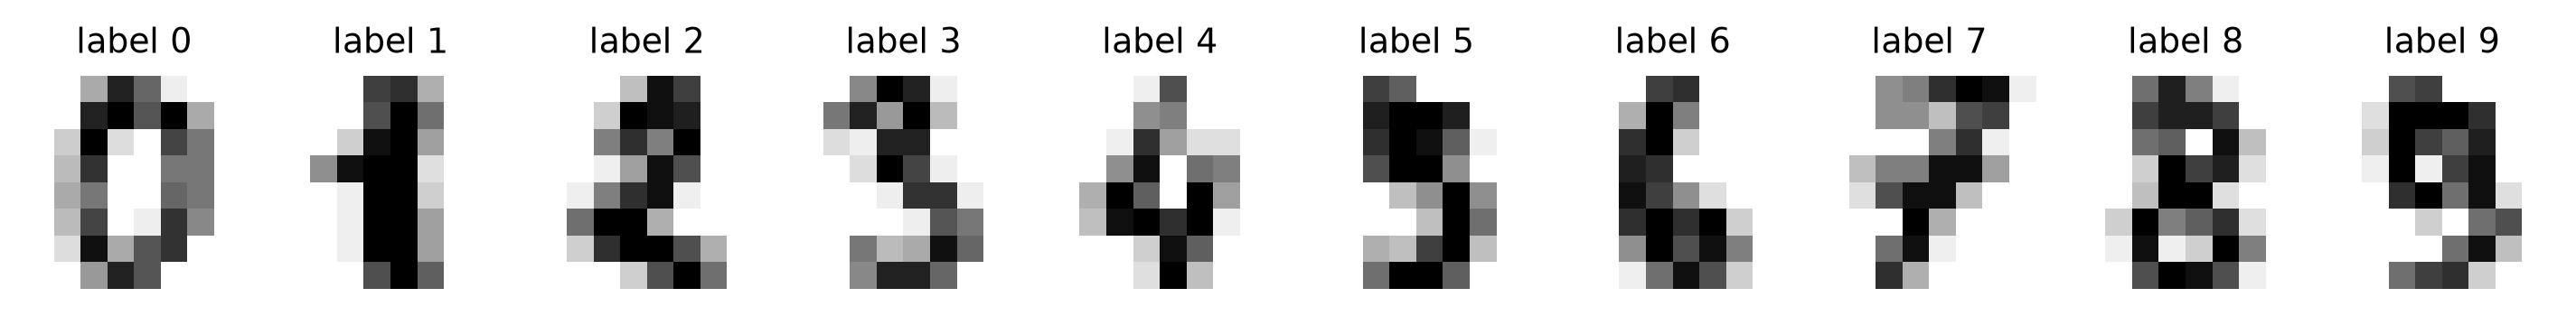

In [37]:
cancer = load_breast_cancer()                        # the tumour data of Practical 4
X_bc, y_bc = cancer.data, cancer.target              # (569, 30) features; labels 0 = malignant, 1 = benign
class_names_bc = cancer.target_names                 # array(['malignant', 'benign'])

digits = load_digits()                               # 8 x 8 images of handwritten digits
X_dig, y_dig = digits.data, digits.target            # (1797, 64): each row is one image, flattened

print("Breast Cancer:", X_bc.shape, "  class counts", {str(c): int(m) for c, m in zip(class_names_bc, np.bincount(y_bc))})
print("Digits       :", X_dig.shape, "  pixel values from", X_dig.min(), "to", X_dig.max())

fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))   # ten small panels in one row
for ax, image, label in zip(axes, X_dig[:10], y_dig[:10]):  # one panel per image
    ax.imshow(image.reshape(8, 8), cmap="gray_r")    # the 64 numbers folded back into an 8 x 8 picture
    ax.set_title(f"label {label}", fontsize=9)       # the true label above the picture
    ax.axis("off")                                   # no axes around a picture
plt.show()                                           # draw the figure

## 0b. The two other datasets: Breast Cancer and Digits

**Line by line**

- `load_breast_cancer()` : the tumour data of Practical 4: 30 measurements of the cell nuclei of each tumour, and a
  label, **0 = malignant, 1 = benign**. With two classes it is the natural place for the two-class version of LDA
  (Part 6).
- `load_digits()` : 1797 small grey pictures of handwritten digits. Each picture has $8 \times 8 = 64$ pixels, and
  each pixel is a number from 0 (white) to 16 (black). The 64 numbers of a picture are stored as one row of $X$.
- `image.reshape(8, 8)` : folds the 64 numbers of a row back into an $8 \times 8$ grid, so `imshow` can draw it.
  `cmap="gray_r"` is the reversed grey colour map: large values are dark, as ink on paper.
- `ax.axis("off")` : a picture needs no axes or tick marks.

**Reading the output.** 569 tumours (212 malignant, 357 benign) and 1797 digit images, shown here are the first ten
with their labels. The Digits data are useful because **every row is a picture**: in Part 5, when PCA rebuilds a row
from a few numbers, we can look at the result and see with our own eyes what was kept and what was lost.

# Part 1: Lock away the test set, standardise, and look at the correlations

## 1a. The test set comes first

The golden rule of Practicals 4 and 5 still holds: **before any plotting, modelling or choosing, cut off the test set
and lock it away.** PCA and LDA are *learned from data*, just like the coefficients of a regression: the mean, the
directions and the eigenvalues are all estimated from rows. So they must be estimated from the development rows only
and then simply **applied** to the test rows.

All three datasets are classification problems, so we use a **stratified** split (Practical 4, 1c): every class keeps
the same proportion in the development and the test set. We use the same seed as before.

In [38]:
SEED_TEST = 2026                                     # fixed once, never changed afterwards

# Wine: stratified 80 / 20 split
Xw_dev, Xw_test, yw_dev, yw_test = train_test_split(X_wine, y_wine, test_size=0.2,  # 80 / 20
                                                    stratify=y_wine, random_state=SEED_TEST)
# Breast Cancer and Digits: the same recipe
Xbc_dev, Xbc_test, ybc_dev, ybc_test = train_test_split(X_bc, y_bc, test_size=0.2,  # 80 / 20
                                                        stratify=y_bc, random_state=SEED_TEST)
Xd_dev, Xd_test, yd_dev, yd_test = train_test_split(X_dig, y_dig, test_size=0.2,  # 80 / 20
                                                    stratify=y_dig, random_state=SEED_TEST)

pd.DataFrame({"development rows": [len(yw_dev), len(ybc_dev), len(yd_dev)],  # one row per dataset
              "test rows (locked)": [len(yw_test), len(ybc_test), len(yd_test)],
              "class counts, development": [np.bincount(yw_dev), np.bincount(ybc_dev), np.bincount(yd_dev)],
              "class counts, test": [np.bincount(yw_test), np.bincount(ybc_test), np.bincount(yd_test)]},
             index=["Wine", "Breast Cancer", "Digits"])

,development rows,test rows (locked),"class counts, development","class counts, test"
Wine,142,36,"[47, 57, 38]","[12, 14, 10]"
Breast Cancer,455,114,"[170, 285]","[42, 72]"
Digits,1437,360,"[142, 145, 142, 146, 145, 146, 145, 143, 139, ...","[36, 37, 35, 37, 36, 36, 36, 36, 35, 36]"


**Line by line**

- `train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED_TEST)` : the stratified hold-out split of
  Practical 4. It returns four arrays in the order development-X, test-X, development-y, test-y.
- The same recipe is applied to the three datasets, so all three have their own locked test set.
- The table only records sizes and class counts. Looking at the **labels** of the test set in such a summary is
  harmless, because we choose nothing based on it.

**Reading the output.** Wine: 142 development and 36 test wines, with the classes split 47, 57, 38 and 12, 14, 10,
very close to the full proportions. Breast Cancer: 455 and 114. Digits: 1437 and 360, with about 36 test images of
every digit.

**From here on, every choice is made with the development rows.** The test rows appear only where we want to *see*
how a fitted method behaves on new data, never to choose anything: in Part 5 (how well a PCA fitted on the
development rows rebuilds new rows), in the plots of Part 8 (where new wines land), and in the single final evaluation
at the end of Part 8.

In [39]:
def standardise(X_fit, X_apply):
    '''Rescale the columns of X_apply using the mean and standard deviation of the columns of X_fit.'''
    mean = X_fit.mean(axis=0)                        # one mean per column, from X_fit only
    sd = X_fit.std(axis=0)                           # one standard deviation per column, from X_fit only
    return (X_apply - mean) / sd                     # broadcasting: every row rescaled column by column


Zw_dev = standardise(Xw_dev, Xw_dev)                 # Wine development rows, scaled with their own statistics
Zw_test = standardise(Xw_dev, Xw_test)               # Wine test rows, scaled with the DEVELOPMENT statistics
Zbc_dev = standardise(Xbc_dev, Xbc_dev)              # the same for Breast Cancer
Zbc_test = standardise(Xbc_dev, Xbc_test)            # test rows, development statistics

# the library check
scaler = StandardScaler().fit(Xw_dev)                # learns the development means and stds
print("same as StandardScaler (development):", np.allclose(Zw_dev, scaler.transform(Xw_dev)))
print("same as StandardScaler (test)       :", np.allclose(Zw_test, scaler.transform(Xw_test)))
print("development column means  :", Zw_dev.mean(axis=0).round(3) + 0.0)
print("development column stds   :", Zw_dev.std(axis=0).round(3))

same as StandardScaler (development): True
same as StandardScaler (test)       : True
development column means  : [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
development column stds   : [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 1b. Standardising

PCA is about **variance**, and variance depends on units: as 0a showed, on the raw Wine numbers proline would swamp
everything. So, as in Practical 5, every column is first put on the same scale,

$$z_{ij} = \frac{x_{ij} - \text{mean}_j}{\text{sd}_j},$$

with the mean and standard deviation computed from the **development rows only** and then reused for the test rows.
After this, every column has mean 0 and standard deviation 1, and PCA treats every chemical measurement as equally
important to begin with.

**Line by line**

- `standardise(X_fit, X_apply)` : the function of Practical 5, unchanged: the statistics come from `X_fit` and are
  applied to `X_apply`.
- `Zw_dev`, `Zw_test` : the Wine development and test rows, both scaled with the **development** statistics. The same
  is done for Breast Cancer. (The Digits data are **not** standardised: all 64 pixels are measured in the same units,
  and three pixels are 0 in every image, so their standard deviation is 0 and dividing by it is impossible. Part 5
  comes back to this.)
- `StandardScaler().fit(Xw_dev)` learns the same two vectors, and `.transform(...)` applies them.
- `.round(3) + 0.0` : turns "negative zeros" such as $-0.0$ into ordinary zeros, purely for a clean printout
  (Practical 5).

**Reading the output.** Both checks print `True`, and every development column now has mean 0 and standard deviation
1.

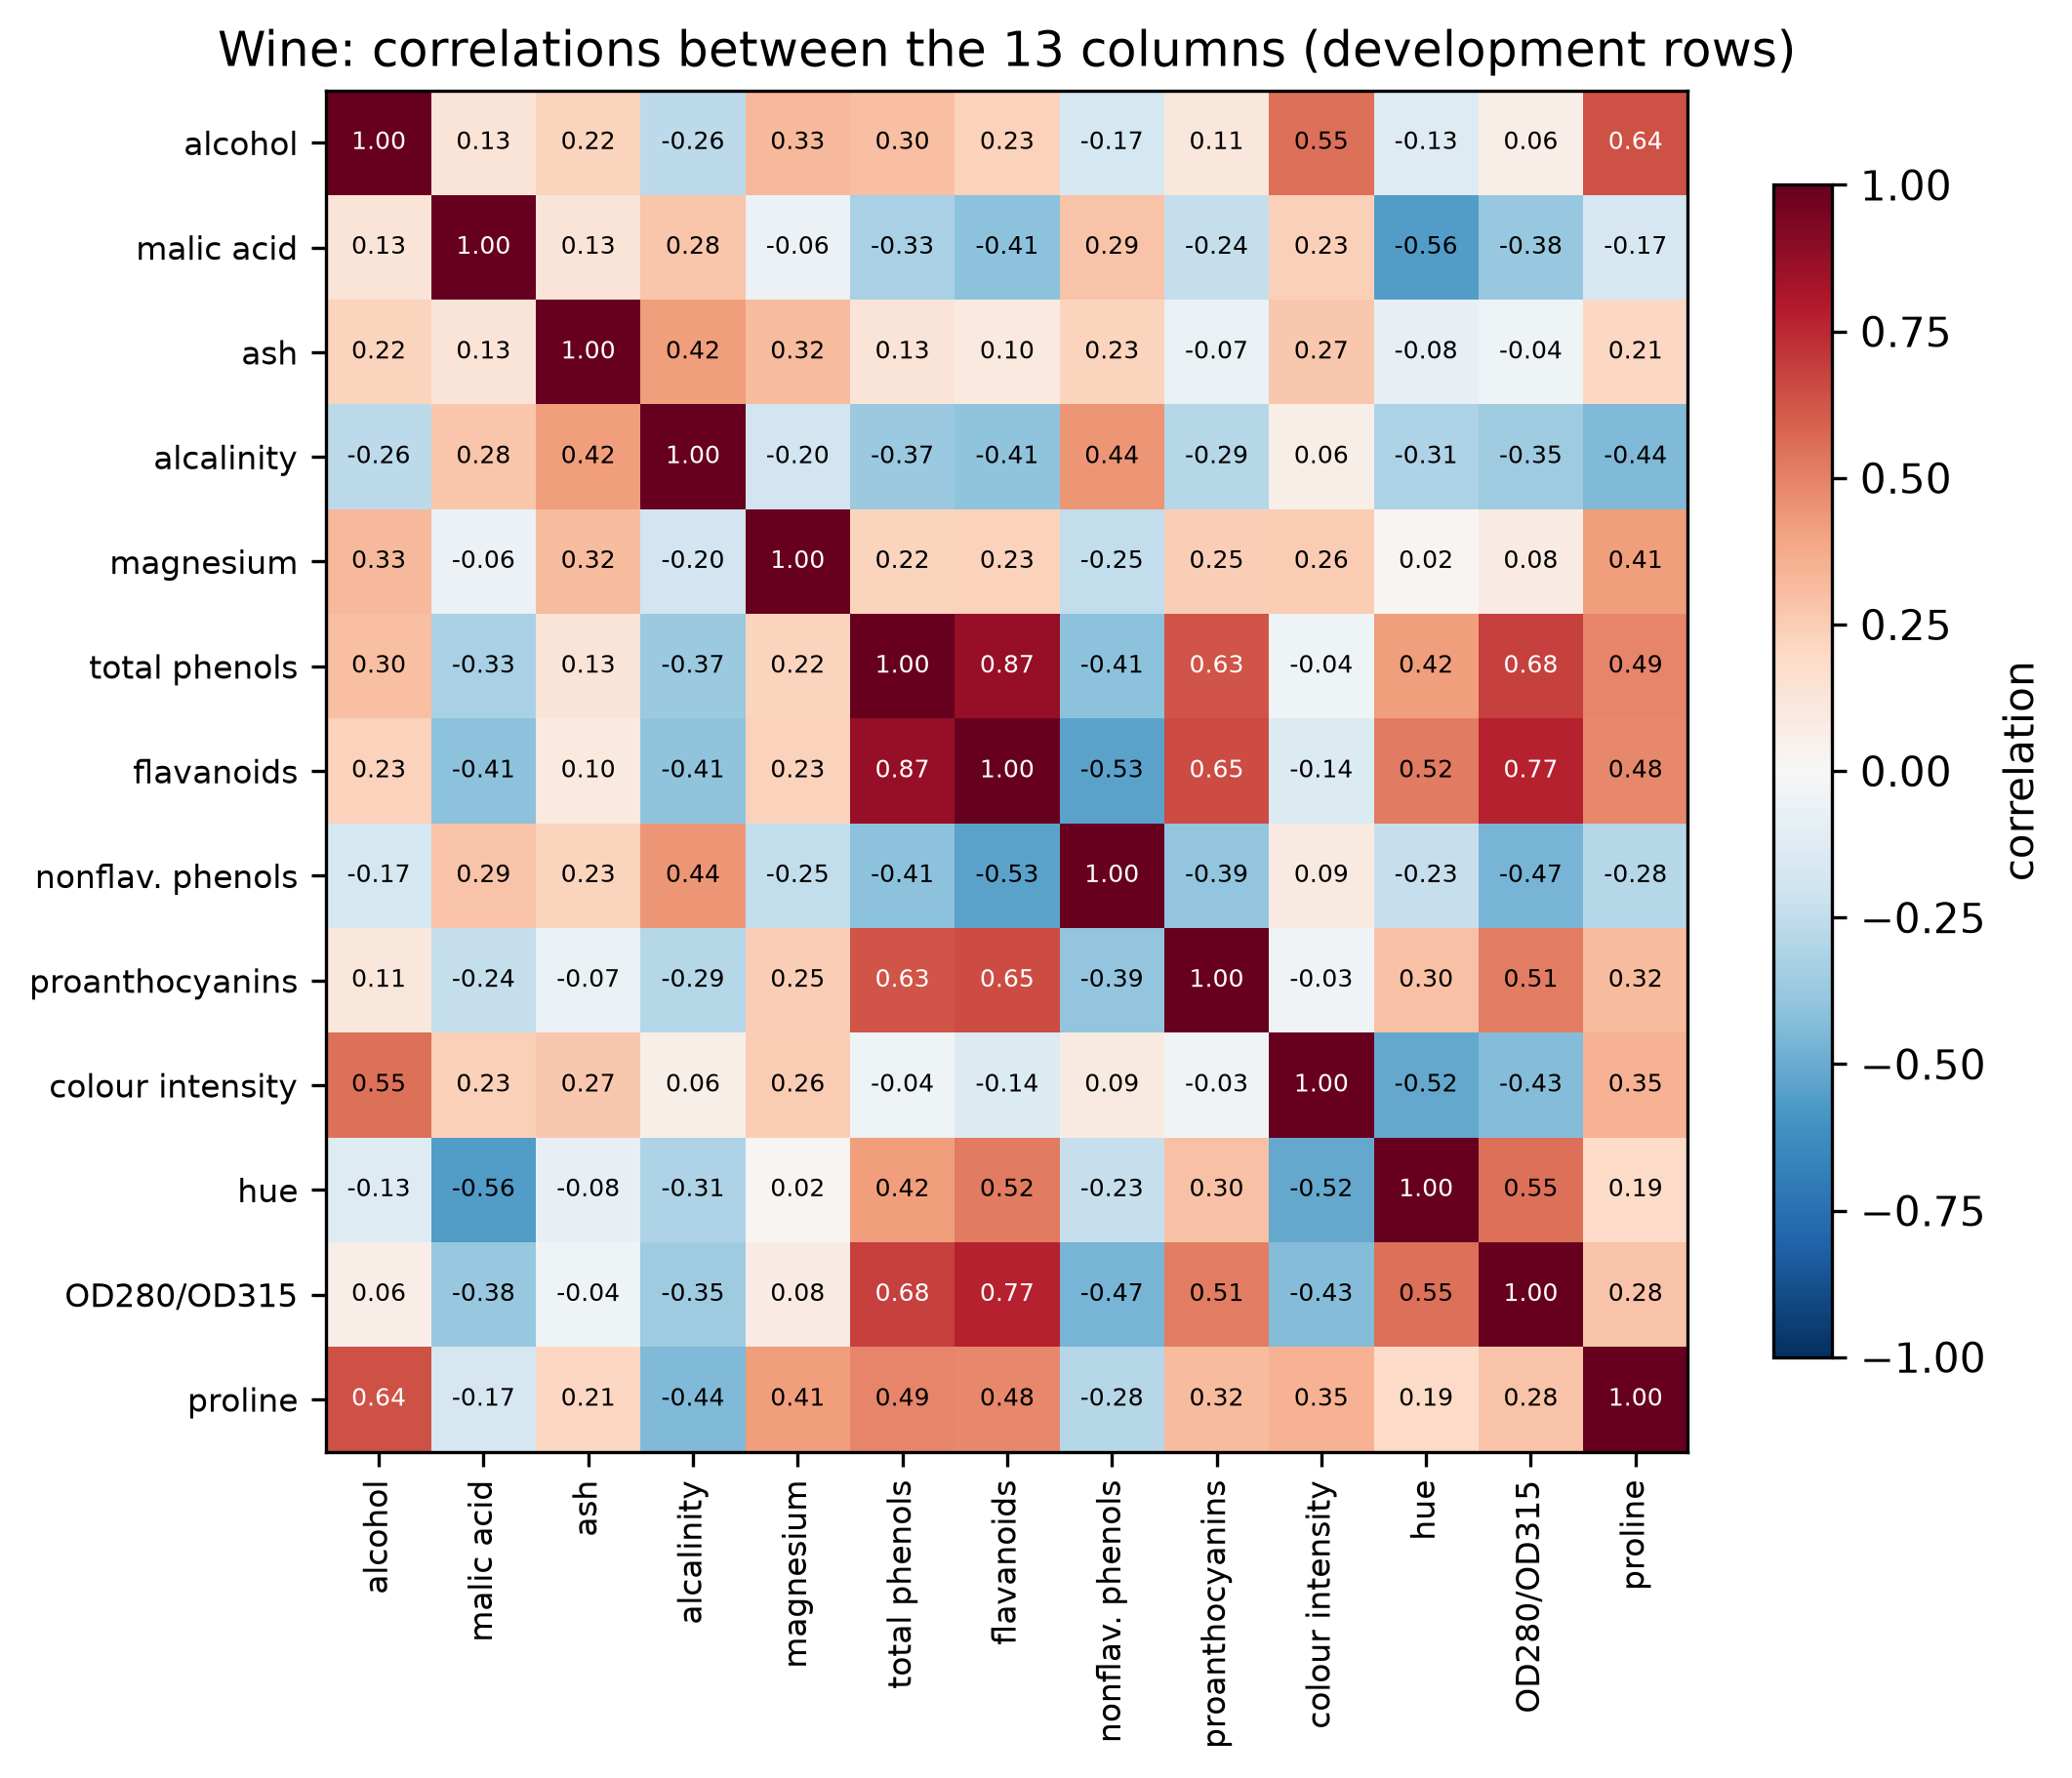

78 pairs of columns; the six most strongly correlated:


,column 1,column 2,correlation,strength
50,total phenols,flavanoids,0.8677,0.8677
61,flavanoids,OD280/OD315,0.7679,0.7679
55,total phenols,OD280/OD315,0.6811,0.6811
58,flavanoids,proanthocyanins,0.6550,0.6550
11,alcohol,proline,0.6373,0.6373
52,total phenols,proanthocyanins,0.6252,0.6252


In [40]:
corr = np.corrcoef(Zw_dev, rowvar=False)             # (13, 13) correlation matrix of the development columns
p = Zw_dev.shape[1]                                  # number of columns: 13

fig, ax = plt.subplots(figsize=(7.5, 6.5))           # one square panel
image = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)        # red = positive, blue = negative
for i in range(p):                                   # every row of the matrix
    for j in range(p):                               # every column of the matrix
        ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=6,  # write the value
                color="white" if abs(corr[i, j]) > 0.6 else "black")   # white text on dark squares
ax.set_xticks(range(p))                              # one tick per column
ax.set_xticklabels(short_names, rotation=90, fontsize=8)  # names, written vertically
ax.set_yticks(range(p))                              # one tick per row
ax.set_yticklabels(short_names, fontsize=8)          # names on the left
fig.colorbar(image, ax=ax, label="correlation", shrink=0.8)  # the colour scale
ax.set_title("Wine: correlations between the 13 columns (development rows)")  # title
plt.show()                                           # draw the figure

pairs = pd.DataFrame([(short_names[i], short_names[j], corr[i, j]) for i in range(p) for j in range(i + 1, p)],
                     columns=["column 1", "column 2", "correlation"])
pairs["strength"] = pairs["correlation"].abs()       # a strong negative correlation counts as much as a positive one
print(f"{len(pairs)} pairs of columns; the six most strongly correlated:")
pairs.sort_values("strength", ascending=False).head(6)  # the six strongest pairs

## 1c. Which columns are correlated?

**Line by line**

- `np.corrcoef(Zw_dev, rowvar=False)` : the $13 \times 13$ correlation matrix of the development columns
  (Practical 5, 1c). `rowvar=False` says that the variables are the columns.
- `p = Zw_dev.shape[1]` : the number of columns, 13. We use `p` many times below.
- The heat map is drawn exactly as in Practical 5: red for positive, blue for negative correlations, with the value
  written in every square.
- The list comprehension visits every pair of columns once ($13 \times 12 / 2 = 78$ pairs) and the table shows the six
  strongest.

**Reading the plot and the table.**

- The strongest pair is **total phenols and flavanoids, 0.87**. Flavanoids are themselves a kind of phenol, so the two
  measurements largely count the same molecules.
- Flavanoids, total phenols, OD280/OD315 and proanthocyanins form a **group** that rises and falls together
  (correlations from 0.63 to 0.87). In the heat map it is the dark red block in the middle.
- Alcohol goes with proline (0.64) and with colour intensity (0.55).
- So the 13 columns contain much less than 13 columns' worth of information. A wine that is high in flavanoids is
  almost certainly high in total phenols too, and a single number could describe both. That is exactly what PCA
  will do.

# Part 2: PCA by eigen-decomposition of the covariance matrix

## 2a. The idea, first with only two columns

Take the centred data and choose a **direction**: a vector $w$ of length 1. Projecting a row $x_i$ onto $w$ gives
one number, $w^{\top}x_i$: the shadow of the point on the line through the origin in the direction $w$. Different
directions give shadows that are more or less spread out. PCA asks: **in which direction are the shadows most
spread out?**

The variance of the shadows has a short formula. With $C$ the covariance matrix of the data,

$$\text{Var}(w^{\top}x) = w^{\top} C\, w .$$

We want the $w$ of length 1 that makes $w^{\top}Cw$ as large as possible. Setting the derivative of
$w^{\top}Cw - \lambda(w^{\top}w - 1)$ to zero (a Lagrange multiplier $\lambda$ takes care of "length 1") gives

$$C\,w = \lambda\, w .$$

So the best direction must be an **eigenvector** of $C$, and for an eigenvector the variance is
$w^{\top}Cw = \lambda\, w^{\top}w = \lambda$: its **eigenvalue**. The direction of largest spread is therefore the
eigenvector with the **largest eigenvalue**. That is the first principal direction. The second principal direction is
the direction of largest spread among those **perpendicular** to the first, which turns out to be the eigenvector with
the second largest eigenvalue, and so on.

Before doing this with all 13 columns, let us check it with the two most correlated ones, total phenols and
flavanoids, where we can draw everything. We simply try every direction in the plane, compute the variance of the
shadows, and compare the winner with the eigenvector.

largest variance 1.8810 at 45.0 degrees;  largest eigenvalue 1.8810, eigenvector at 45.0 degrees
smallest variance 0.1332;  smallest eigenvalue 0.1332


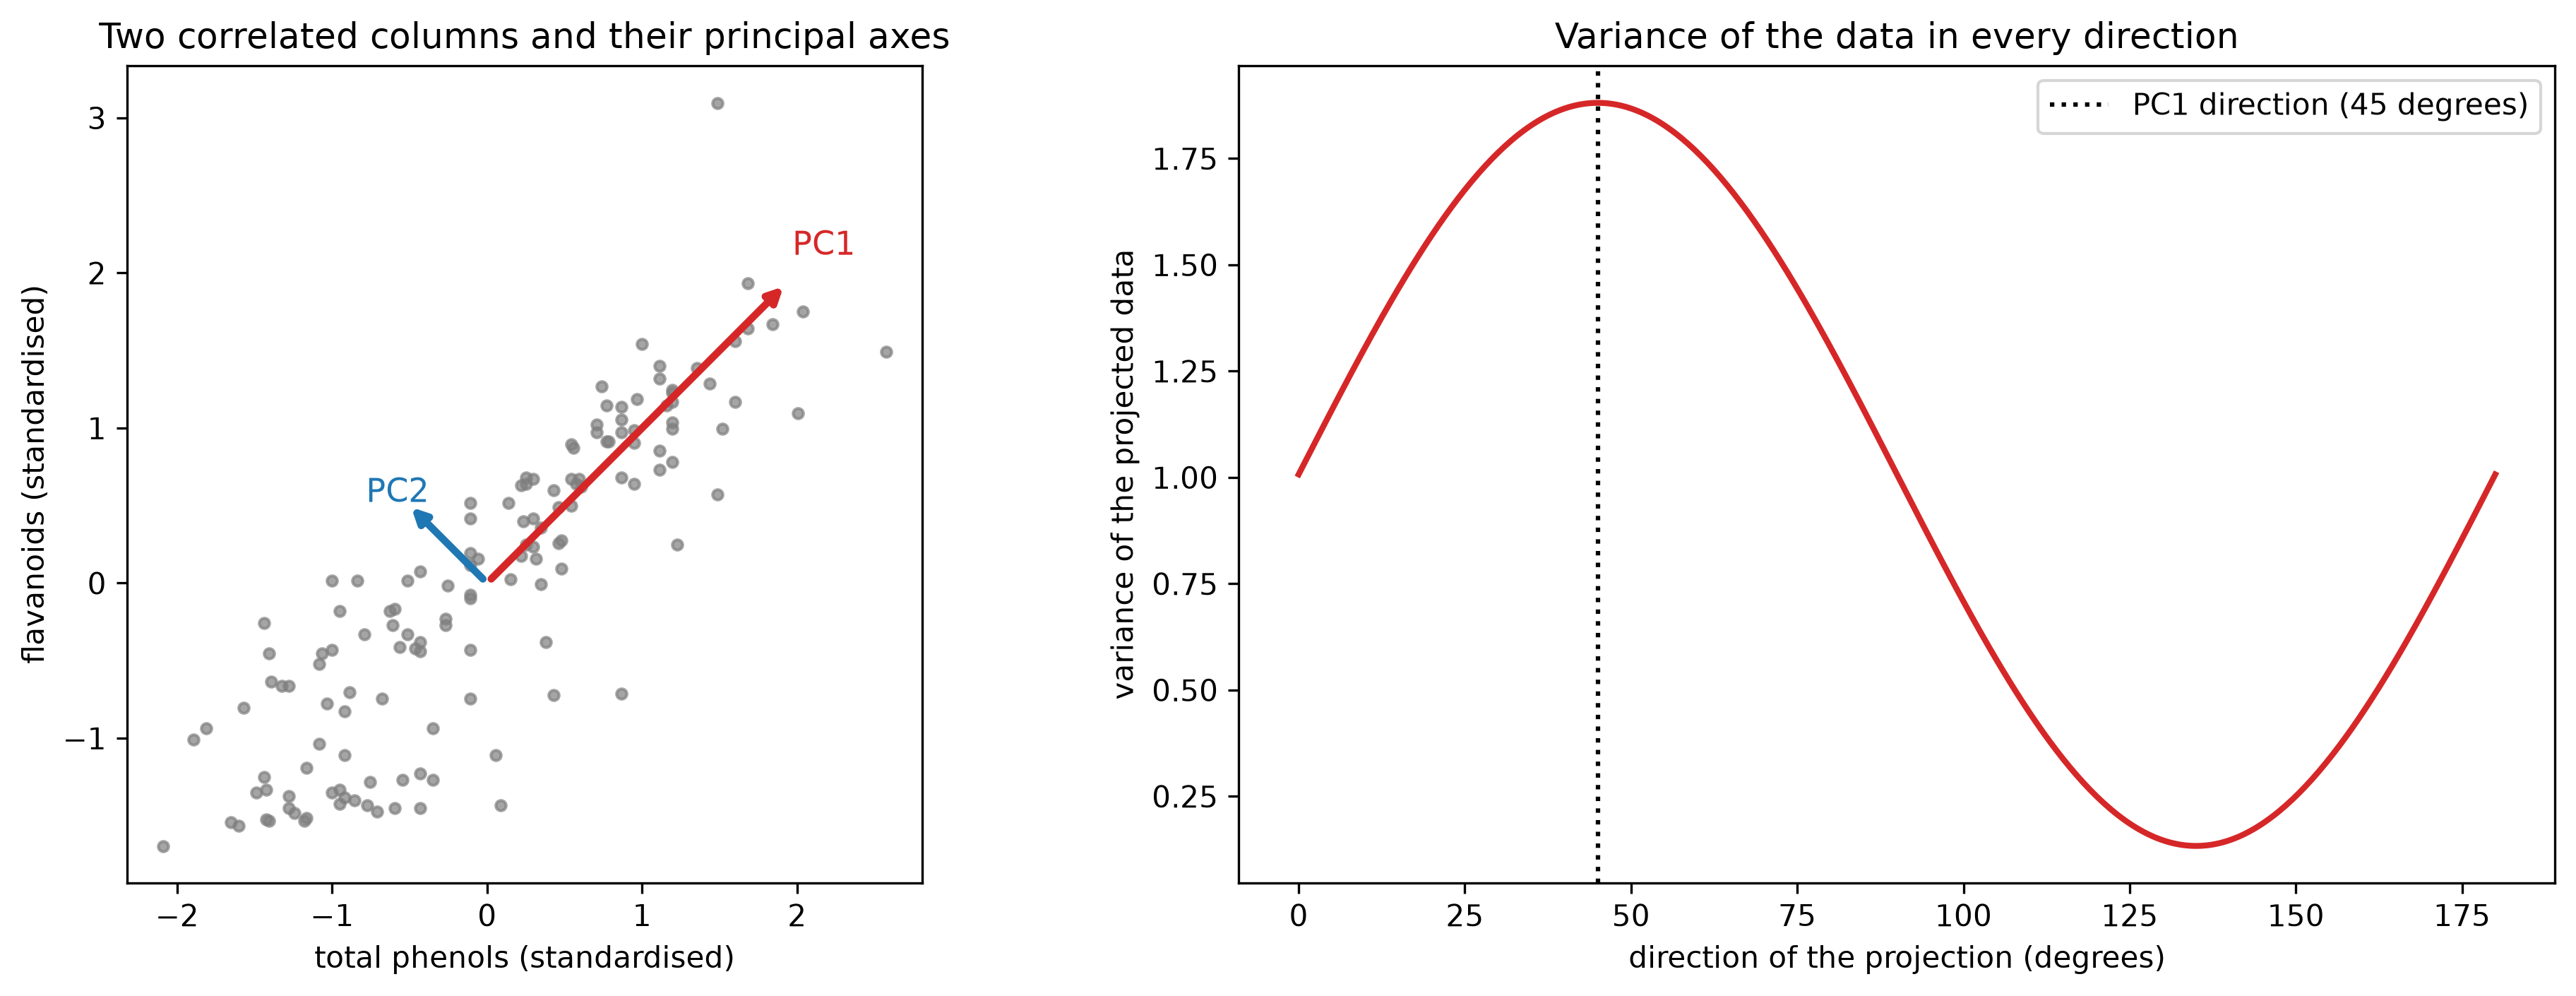

In [41]:
two = [5, 6]                                         # column numbers of total phenols and flavanoids
Z2 = Zw_dev[:, two]                                  # (142, 2): just these two standardised columns
C2 = np.cov(Z2, rowvar=False)                        # their 2 x 2 covariance matrix

angles = np.linspace(0, 180, 361)                    # every direction, in steps of half a degree
directions = np.column_stack([np.cos(np.radians(angles)), np.sin(np.radians(angles))])   # unit vectors
variance_along = np.array([u @ C2 @ u for u in directions])    # variance of the data projected on each one

values2, vectors2 = np.linalg.eigh(C2)               # eigenvalues (smallest first) and eigenvectors of C2
best_angle = angles[np.argmax(variance_along)]       # the direction with the largest variance
pc1_angle = np.degrees(np.arctan2(vectors2[1, 1], vectors2[0, 1])) % 180   # angle of the top eigenvector
print(f"largest variance {variance_along.max():.4f} at {best_angle:.1f} degrees;"
      f"  largest eigenvalue {values2[1]:.4f}, eigenvector at {pc1_angle:.1f} degrees")
print(f"smallest variance {variance_along.min():.4f};  smallest eigenvalue {values2[0]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))    # two panels side by side
axes[0].scatter(Z2[:, 0], Z2[:, 1], s=12, color="tab:grey", alpha=0.7)  # the 142 wines
for value, vector, colour, name in zip(values2[::-1], vectors2.T[::-1], ["tab:red", "tab:blue"], ["PC1", "PC2"]):
    end = 2 * np.sqrt(value) * vector                # arrow length: two standard deviations along this axis
    axes[0].annotate("", xy=end, xytext=(0, 0), arrowprops=dict(color=colour, lw=2.5, arrowstyle="-|>"))
    axes[0].text(*(end * 1.12), name, color=colour, fontsize=11, ha="center", va="center")  # label
axes[0].set_xlabel("total phenols (standardised)")   # x-axis label
axes[0].set_ylabel("flavanoids (standardised)")      # y-axis label
axes[0].set_aspect("equal")                          # same scale on both axes
axes[0].set_title("Two correlated columns and their principal axes")  # title
axes[1].plot(angles, variance_along, color="tab:red", lw=2)  # variance against angle
axes[1].axvline(pc1_angle, color="black", ls="dotted", label=f"PC1 direction ({pc1_angle:.0f} degrees)")
axes[1].set_xlabel("direction of the projection (degrees)")  # x-axis label
axes[1].set_ylabel("variance of the projected data")  # y-axis label
axes[1].set_title("Variance of the data in every direction")  # title
axes[1].legend()                                     # legend
plt.tight_layout()                                   # keep labels from overlapping
plt.show()                                           # draw the figure

**Line by line**

- `Zw_dev[:, [5, 6]]` : all development rows, only columns 5 and 6 (total phenols and flavanoids).
- `np.cov(Z2, rowvar=False)` : their $2 \times 2$ covariance matrix.
- `np.linspace(0, 180, 361)` : angles from 0 to 180 degrees in steps of half a degree. Angles from 180 to 360 give
  the same lines pointing the other way, so they are not needed.
- `np.column_stack([np.cos(...), np.sin(...)])` : the unit vector $(\cos\theta, \sin\theta)$ for every angle, one per
  row. `np.radians` converts degrees to radians, which is what `cos` and `sin` expect.
- `u @ C2 @ u` : the formula $u^{\top}Cu$, the variance of the data projected onto $u$.
- `np.linalg.eigh(C2)` : eigenvalues and eigenvectors of a **symmetric** matrix (a covariance matrix always is). It
  returns the eigenvalues from smallest to largest, and the eigenvectors as the **columns** of the second result.
- `np.arctan2(vy, vx)` : the angle of the vector $(v_x, v_y)$; `% 180` brings it into the range 0 to 180.
- In the left panel each arrow starts at the centre and has length two standard deviations along its axis
  ($2\sqrt{\lambda}$). `annotate("", xy=end, xytext=(0, 0), arrowprops=...)` draws an arrow without text.
- `set_aspect("equal")` : one unit is the same length on both axes, so right angles look like right angles.

**Reading the output and the plots.**

- Trying all 361 directions, the largest variance is **1.8810, at 45 degrees**. The eigenvector with the largest
  eigenvalue points at exactly 45 degrees and its eigenvalue is exactly **1.8810**. The smallest variance (0.1332)
  is the other eigenvalue, at 135 degrees. The formula and the brute-force search agree.
- In the left panel, the long red arrow (PC1) follows the cloud along its length; the short blue arrow (PC2) is
  perpendicular to it. Almost all the spread is along PC1: knowing a wine's position along PC1 tells you almost
  everything about both columns. One number instead of two.
- A curious fact: for **two standardised** columns, the principal directions are **always** the two diagonals, 45 and
  135 degrees, whatever the data. Only the eigenvalues depend on the data: they are $1 + r$ and $1 - r$, where $r$ is
  the correlation. Here $r = 0.868$, so $1 + r = 1.868$ and $1 - r = 0.132$ (both multiplied by $142/141$, which section
  2b explains). With more than two columns the directions are no longer this simple, which is why we need the general
  method.

## 2b. The covariance matrix

For a centred data matrix $Z$ with $n$ rows, the covariance matrix is

$$C = \frac{1}{n-1}\, Z^{\top} Z, \qquad C_{jk} = \frac{1}{n-1}\sum_{i=1}^{n} z_{ij}\, z_{ik}.$$

Entry $(j, k)$ is the covariance of column $j$ with column $k$, and the diagonal entries are the variances of the
columns. The matrix product $Z^{\top}Z$ computes all $p^2$ of these sums at once (Practical 1).

In [42]:
def covariance_matrix(Z):
    '''Covariance matrix of the columns of Z, with the (n - 1) of the sample variance.'''
    Zc = Z - Z.mean(axis=0)                          # centre every column (already ~0 for standardised data)
    return Zc.T @ Zc / (len(Z) - 1)                  # (p, p): entry (j, k) = covariance of columns j and k


C_wine = covariance_matrix(Zw_dev)                   # 13 x 13
print("shape of the covariance matrix:", C_wine.shape)
print("same as np.cov                :", np.allclose(C_wine, np.cov(Zw_dev, rowvar=False)))
print("symmetric                     :", np.allclose(C_wine, C_wine.T))
print(f"every diagonal entry          : {C_wine[0, 0]:.4f}   (= n / (n - 1) = {len(Zw_dev)} / {len(Zw_dev) - 1})")

shape of the covariance matrix: (13, 13)
same as np.cov                : True
symmetric                     : True
every diagonal entry          : 1.0071   (= n / (n - 1) = 142 / 141)


**Line by line**

- `Zc = Z - Z.mean(axis=0)` : centre every column. For the standardised data the means are already 0, but the
  function should also work for data that are not centred, such as the Digits pixels in Part 5.
- `Zc.T @ Zc / (len(Z) - 1)` : the formula above. We divide by $n - 1$, as NumPy's `np.cov` and scikit-learn's `PCA`
  do, so that our numbers can be compared with theirs exactly.
- `np.allclose(C_wine, C_wine.T)` : a covariance matrix is always **symmetric**, $C_{jk} = C_{kj}$.

**Reading the output.** The matrix is $13 \times 13$, equal to `np.cov`, and symmetric. Every diagonal entry is
**1.0071**, not 1. The reason is a small difference in conventions: `standardise` (like `StandardScaler`) divides by $n$
when it computes the standard deviation, so each column has $\frac{1}{n}\sum z^2 = 1$, while the covariance divides by
$n - 1$. The ratio is $n/(n-1) = 142/141 = 1.0071$. This tiny factor appears in a few numbers below; it changes
nothing important.

## 2c. PCA by eigen-decomposition, checked against `PCA`

The recipe is now short: compute the eigenvalues and eigenvectors of $C$, and sort them from the largest eigenvalue to
the smallest. One detail needs care. If $v$ is an eigenvector, so is $-v$: a direction and its opposite describe the
same line. Different programs may return either sign, so before we can compare our answer with the library we fix a
**sign convention**: every eigenvector is flipped, if necessary, so that its largest entry (in absolute value) is
positive. This is exactly the rule scikit-learn uses.

In [43]:
def sign_convention(V):
    '''Flip the sign of every column of V so that its largest entry (in absolute value) is positive.'''
    biggest = np.argmax(np.abs(V), axis=0)           # row of the largest |entry| in every column
    signs = np.sign(V[biggest, np.arange(V.shape[1])])   # the sign of that entry, column by column
    return V * signs                                 # broadcasting: column j is multiplied by signs[j]


def pca_eigen(Z):
    '''PCA by eigen-decomposition of the covariance matrix.

    returns : (mean, V, eigenvalues), with the columns of V the principal directions, largest variance first
    '''
    mean = Z.mean(axis=0)                            # the centre of the data
    C = covariance_matrix(Z)                         # (p, p) covariance matrix
    eigenvalues, V = np.linalg.eigh(C)               # eigh: for symmetric matrices, eigenvalues smallest first
    order = np.argsort(eigenvalues)[::-1]            # positions from the largest eigenvalue to the smallest
    return mean, sign_convention(V[:, order]), eigenvalues[order]


mean_w, V_eig, lam_eig = pca_eigen(Zw_dev)           # PCA of the standardised development wines
scores_eig = (Zw_dev - mean_w) @ V_eig               # the coordinates of every wine on the new axes

# the library check
lib_pca = PCA().fit(Zw_dev)                          # all 13 components
print("same directions as PCA (components_)       :", np.allclose(V_eig.T, lib_pca.components_))
print("same variances (explained_variance_)       :", np.allclose(lam_eig, lib_pca.explained_variance_))
print("same ratios (explained_variance_ratio_)    :",
      np.allclose(lam_eig / lam_eig.sum(), lib_pca.explained_variance_ratio_))
print("same scores (transform)                    :", np.allclose(scores_eig, lib_pca.transform(Zw_dev)))
print("\neigenvalues:", lam_eig)

same directions as PCA (components_)       : True
same variances (explained_variance_)       : True
same ratios (explained_variance_ratio_)    : True
same scores (transform)                    : True

eigenvalues: [4.7436 2.6193 1.3747 0.9214 0.8051 0.6529 0.5729 0.3491 0.2947 0.2706
 0.2074 0.178  0.1024]


**Line by line**

- `sign_convention(V)` :
  - `np.argmax(np.abs(V), axis=0)` : for every column, the row where the absolute value is largest.
  - `V[biggest, np.arange(V.shape[1])]` : fancy indexing with two arrays picks one entry per column: the entry in row
    `biggest[j]` of column `j`. `np.sign` of it is $+1$ or $-1$.
  - `V * signs` : broadcasting multiplies column `j` by `signs[j]`, so every column ends up with its largest entry
    positive.
- `pca_eigen(Z)` :
  - `np.linalg.eigh(C)` : eigenvalues (smallest first) and eigenvectors (as columns) of the symmetric matrix $C$.
  - `np.argsort(eigenvalues)[::-1]` : the positions that sort the eigenvalues from largest to smallest.
  - `V[:, order]` : the columns of `V` rearranged in that order, so column 0 is the first principal direction.
  - The function returns the mean (to centre new rows later), the directions and the eigenvalues.
- `(Zw_dev - mean_w) @ V_eig` : the **scores**. Row $i$, column $j$ is $v_j^{\top}(z_i - \text{mean})$, the coordinate of
  wine $i$ along principal direction $j$.
- `PCA().fit(Zw_dev)` : the library's PCA, keeping all 13 components. It stores the directions as the **rows** of
  `components_` (we keep them as columns, hence `V_eig.T`), the eigenvalues in `explained_variance_`, the eigenvalues
  divided by their sum in `explained_variance_ratio_`, and `transform` computes the scores.

**Reading the output.** All four checks print `True`: our ten lines of NumPy are exactly scikit-learn's `PCA`, sign
included. The eigenvalues fall from **4.74** for the first component to **0.10** for the last. Each original column
has variance about 1, so the first principal component alone carries as much variance as almost five original
columns.

## 2d. Three properties of the principal components

PCA is a **rotation** of the data to new axes. Three facts follow from the eigen-decomposition, and we check each one:

1. The directions are **orthonormal**: each has length 1 and every two are perpendicular, so $V^{\top}V = I$.
2. The scores are **uncorrelated**: their covariance matrix is diagonal, and the variance of score $j$ is $\lambda_j$.
   The new columns carry no overlapping information, unlike the original ones.
3. Nothing is lost by the rotation: the **total variance** (the sum of the variances of all columns, the trace of $C$)
   equals the sum of the eigenvalues.

In [44]:
print("V^T V is the identity (orthonormal directions):", np.allclose(V_eig.T @ V_eig, np.eye(p)))

C_scores = covariance_matrix(scores_eig)             # covariance matrix of the 13 scores
print("covariance of the scores is diagonal         :", np.allclose(C_scores - np.diag(np.diag(C_scores)), 0))
print("variance of each score = its eigenvalue      :", np.allclose(np.diag(C_scores), lam_eig))
print(f"sum of the eigenvalues  = {lam_eig.sum():.4f}")
print(f"total variance (trace C) = {np.trace(C_wine):.4f}   = 13 x {len(Zw_dev)} / {len(Zw_dev) - 1}")

pd.DataFrame(C_scores[:4, :4], index=[f"PC{j}" for j in range(1, 5)],  # a 4 x 4 corner
             columns=[f"PC{j}" for j in range(1, 5)]).round(4)   # the top-left corner of the covariance

V^T V is the identity (orthonormal directions): True
covariance of the scores is diagonal         : True
variance of each score = its eigenvalue      : True
sum of the eigenvalues  = 13.0922
total variance (trace C) = 13.0922   = 13 x 142 / 141


,PC1,PC2,PC3,PC4
PC1,4.7436,-0.0000,-0.0000,0.0000
PC2,-0.0000,2.6193,-0.0000,-0.0000
PC3,-0.0000,-0.0000,1.3747,0.0000
PC4,0.0000,-0.0000,0.0000,0.9214


**Line by line**

- `V_eig.T @ V_eig` : entry $(j, k)$ is the dot product of directions $j$ and $k$: 1 when $j = k$ (length 1), 0
  otherwise (perpendicular). `np.eye(p)` is the $13 \times 13$ identity matrix.
- `covariance_matrix(scores_eig)` : the covariance matrix of the 13 score columns.
- `C_scores - np.diag(np.diag(C_scores))` : `np.diag` of a matrix gives its diagonal as a vector, and `np.diag` of a
  vector builds a diagonal matrix. Subtracting leaves only the off-diagonal entries, which must all be 0.
- `np.trace(C_wine)` : the sum of the diagonal of $C$, i.e. the sum of the variances of the 13 columns.
- The last table shows the top-left $4 \times 4$ corner of the score covariance matrix.

**Reading the output.** All three properties hold. The covariance matrix of the scores has the eigenvalues 4.74, 2.62,
1.37, 0.92, ... on its diagonal and zeros everywhere else. The sum of the eigenvalues is **13.0922**, exactly the total
variance of the 13 columns ($13 \times 142/141$, the factor of 2b). PCA has not created or destroyed any variance; it
has **redistributed** it, putting as much as possible into the first component, as much of the rest as possible into
the second, and so on.

## 2e. What do the first two components mean?

Each principal direction is a list of 13 **weights**, one per original column. The score of a wine is the weighted
sum of its standardised measurements. Large weights (positive or negative) show which measurements a component is
really about.

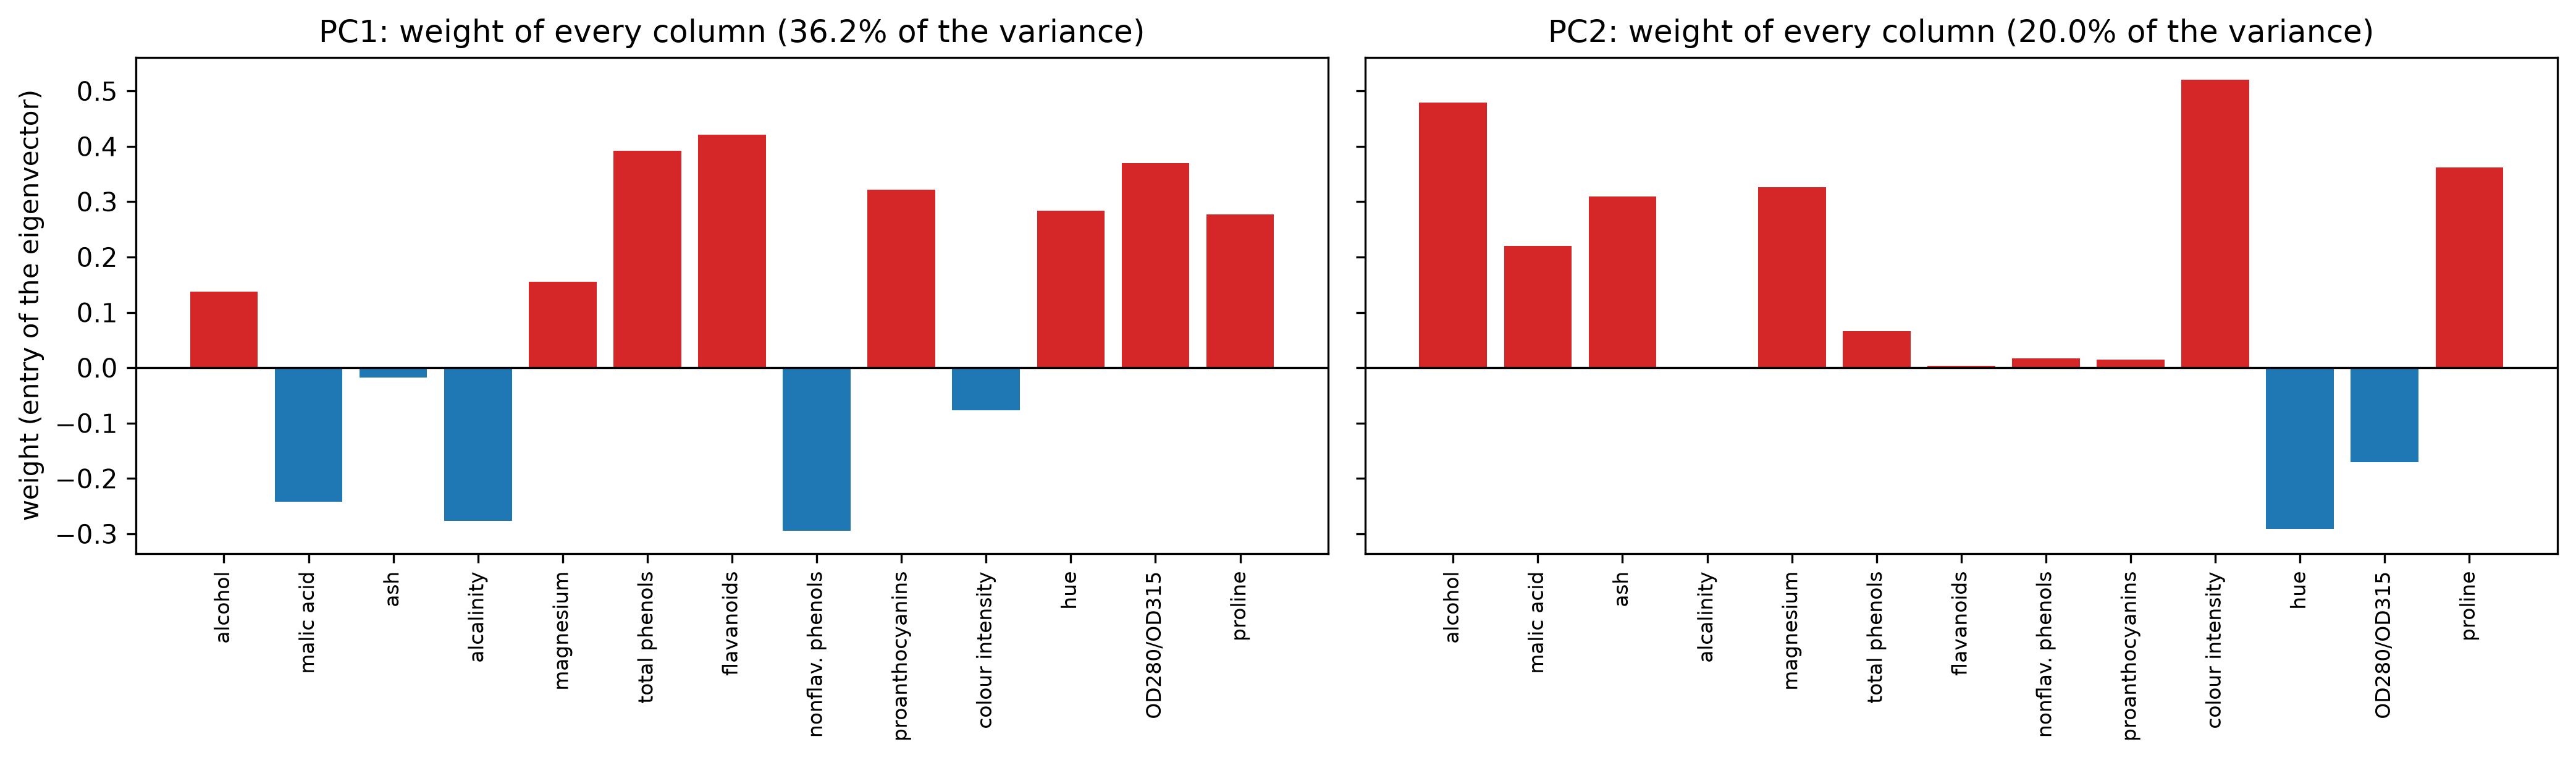

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)  # two panels, same vertical scale
for ax, j in zip(axes, [0, 1]):                      # PC1 on the left, PC2 on the right
    colours = ["tab:red" if v > 0 else "tab:blue" for v in V_eig[:, j]]   # red = positive weight
    ax.bar(range(p), V_eig[:, j], color=colours)     # one bar per column
    ax.axhline(0, color="black", lw=0.8)             # the zero line
    ax.set_xticks(range(p))                          # one tick per column
    ax.set_xticklabels(short_names, rotation=90, fontsize=8)  # names, written vertically
    ax.set_title(f"PC{j + 1}: weight of every column ({lam_eig[j] / lam_eig.sum():.1%} of the variance)")
axes[0].set_ylabel("weight (entry of the eigenvector)")  # y-axis label
plt.tight_layout()                                   # keep labels from overlapping
plt.show()                                           # draw the figure

**Line by line**

- `for ax, j in zip(axes, [0, 1])` : one panel for PC1 and one for PC2.
- `colours = [...]` : red for positive weights, blue for negative ones.
- `ax.bar(range(p), V_eig[:, j], ...)` : one bar per original column, with height equal to its weight in
  component `j`.
- `f"{lam_eig[j] / lam_eig.sum():.1%}"` : the share of the total variance explained by the component, as a
  percentage.

**Reading the plots.**

- **PC1 (36.2% of the variance)** gives large positive weights to flavanoids (0.42), total phenols (0.39),
  OD280/OD315 (0.37) and proanthocyanins (0.32), and negative weights to nonflavanoid phenols, alcalinity and malic
  acid. It is essentially the **phenol group** of 1c. A wine with a high PC1 score is rich in phenols and
  flavanoids.
- **PC2 (20.0%)** is about something else: colour intensity (0.52), alcohol (0.48), proline (0.36), magnesium and
  ash, against hue. The phenols hardly appear in it: PC2 describes what PC1 does not.
- This is typical of PCA. Each component is a mixture of **all** the columns, so it does not always have a neat
  meaning, but the largest weights usually point to a group of correlated measurements. The correlated group of 1c
  has been compressed into a single number.

# Part 3: PCA by the singular value decomposition

## 3a. The same directions without the covariance matrix

Every matrix, of any shape, can be written as a product of three special matrices. For the centred $n \times p$ data
matrix this **singular value decomposition (SVD)** is

$$Z = U\, S\, V^{\top},$$

where

- $U$ is $n \times p$ with orthonormal columns,
- $S$ is a $p \times p$ diagonal matrix of **singular values** $s_1 \ge s_2 \ge \dots \ge s_p \ge 0$,
- $V$ is $p \times p$ with orthonormal columns.

Why does this give PCA? Substitute it into the covariance matrix. Because $U^{\top}U = I$,

$$Z^{\top}Z = V S U^{\top} U S V^{\top} = V S^2 V^{\top}
\qquad\Longrightarrow\qquad
C = \frac{1}{n-1} Z^{\top}Z = V \left(\frac{S^2}{n-1}\right) V^{\top}.$$

That is an eigen-decomposition of $C$. So the columns of $V$ are the **principal directions**, and the eigenvalues
are $\lambda_j = s_j^2/(n-1)$. The scores come for free as well: $ZV = U S V^{\top} V = U S$.

In short: **the SVD of the data gives PCA directly, without ever forming $Z^{\top}Z$.** Section 3b shows why that
matters.

In [46]:
def pca_svd(Z):
    '''PCA by the singular value decomposition of the centred data.

    returns : (mean, V, eigenvalues), exactly like pca_eigen
    '''
    mean = Z.mean(axis=0)                            # the centre of the data
    U, s, Vt = np.linalg.svd(Z - mean, full_matrices=False)   # Z - mean = U diag(s) V^T, s sorted largest first
    eigenvalues = s ** 2 / (len(Z) - 1)              # the variance along each direction
    return mean, sign_convention(Vt.T), eigenvalues  # the rows of V^T are the principal directions


mean_s, V_svd, lam_svd = pca_svd(Zw_dev)             # PCA by SVD
print("same directions as the eigen route :", np.allclose(V_svd, V_eig))
print("same eigenvalues as the eigen route:", np.allclose(lam_svd, lam_eig))

# a closer look at the three matrices of the SVD
U, s, Vt = np.linalg.svd(Zw_dev - mean_s, full_matrices=False)  # the three SVD matrices
print("\nshapes: U", U.shape, "  s", s.shape, "  V^T", Vt.shape)
print("U S V^T rebuilds the centred data   :", np.allclose(U @ np.diag(s) @ Vt, Zw_dev - mean_s))
flips = np.sign(np.sum(Vt.T * V_svd, axis=0))      # +1 where our sign convention kept a column, -1 where it flipped it
print("U S equals the scores of Part 2    :", np.allclose(U * s * flips, scores_eig))
print("singular values = PCA.singular_values_:", np.allclose(s, lib_pca.singular_values_))
print("\nsingular values:", s)

same directions as the eigen route : True
same eigenvalues as the eigen route: True

shapes: U (142, 13)   s (13,)   V^T (13, 13)
U S V^T rebuilds the centred data   : True
U S equals the scores of Part 2    : True
singular values = PCA.singular_values_: True

singular values: [25.8621 19.2177 13.9225 11.3982 10.6547  9.5948  8.9873  7.0164  6.4458
  6.1773  5.4081  5.0095  3.8003]


**Line by line**

- `np.linalg.svd(Z - mean, full_matrices=False)` : the SVD of the centred data. It returns `U`, the singular values
  `s` as a vector (largest first), and $V^{\top}$ (not $V$). `full_matrices=False` asks for the "thin" version, where
  `U` is $142 \times 13$ instead of $142 \times 142$; the extra columns would only multiply zeros.
- `s ** 2 / (len(Z) - 1)` : the eigenvalues, from the formula above.
- `sign_convention(Vt.T)` : the rows of $V^{\top}$ are the directions, so we transpose to have them as columns and
  apply the same sign convention as in Part 2.
- `U @ np.diag(s) @ Vt` : multiplies the three pieces back together. It must give the centred data again.
- `flips = np.sign(np.sum(Vt.T * V_svd, axis=0))` : for every direction, $+1$ if `sign_convention` left the SVD's
  direction as it was and $-1$ if it flipped it. (`np.sum(a * b, axis=0)` is the dot product of matching columns; for
  two unit vectors that are equal or opposite it is $+1$ or $-1$.)
- `U * s * flips` : multiplies column $j$ of `U` by $s_j$ and by the same sign, giving $US$ with our sign convention.
- `lib_pca.singular_values_` : scikit-learn stores the singular values too.

**Reading the output.** Every check prints `True`. The SVD gives the same 13 directions and the same 13 eigenvalues as
the eigen-decomposition, and its three matrices rebuild the data exactly. The largest singular value is 25.86, and
indeed $25.86^2/141 = 4.74$, the first eigenvalue of Part 2.

## 3b. Why libraries prefer the SVD

If both roads give the same answer, why does every library use the SVD? Because of **rounding**. A computer stores
about 16 significant digits. Forming $Z^{\top}Z$ **squares** every number, so a small singular value such as $10^{-9}$
becomes an eigenvalue of $10^{-18}$, and $1 + 10^{-18}$ cannot be told apart from 1 with 16 digits: the information is
lost before the eigen-decomposition even starts. The SVD works on $Z$ itself and never squares anything.

A classic small example makes this visible. Its two columns are almost identical, the extreme case of correlated
columns (Practical 5).

In [47]:
eps = 1e-9                                           # a tiny number
X_tiny = np.array([[1.0, 1.0],                       # row 1
                   [eps, 0.0],
                   [0.0, eps]])                      # two columns that are almost identical

eig_route = np.linalg.eigvalsh(X_tiny.T @ X_tiny)    # eigenvalues of X^T X (smallest first)
svd_route = np.linalg.svd(X_tiny, compute_uv=False)  # singular values of X (largest first)

print("X^T X as the computer stores it:\n", X_tiny.T @ X_tiny)
print(f"\nsmallest eigenvalue of X^T X          : {eig_route[0]:.3e}")
print(f"smallest singular value of X, squared : {svd_route[-1] ** 2:.3e}")
print(f"the true value, eps^2                 : {eps ** 2:.3e}")

X^T X as the computer stores it:
 [[1. 1.]
 [1. 1.]]

smallest eigenvalue of X^T X          : 0.000e+00
smallest singular value of X, squared : 1.000e-18
the true value, eps^2                 : 1.000e-18


**Line by line**

- `X_tiny` : a $3 \times 2$ matrix whose two columns differ only by $\varepsilon = 10^{-9}$ in the last two rows.
- `X_tiny.T @ X_tiny` : in exact arithmetic this is $\begin{pmatrix} 1 + \varepsilon^2 & 1 \\ 1 & 1 + \varepsilon^2
  \end{pmatrix}$, whose smallest eigenvalue is exactly $\varepsilon^2 = 10^{-18}$.
- `np.linalg.eigvalsh(...)` : only the eigenvalues of a symmetric matrix (no eigenvectors), smallest first.
- `np.linalg.svd(X_tiny, compute_uv=False)` : only the singular values, without `U` and `V`.
- `f"{value:.3e}"` : prints a number in scientific notation with three decimals.

**Reading the output.** The printed $X^{\top}X$ is $\begin{pmatrix} 1 & 1 \\ 1 & 1 \end{pmatrix}$: the
$\varepsilon^2 = 10^{-18}$ on the diagonal has vanished, because $1 + 10^{-18}$ is stored as exactly 1. That matrix is
singular, so the eigen route reports a smallest eigenvalue of **0**: the small direction has disappeared completely.
The SVD route reports a smallest singular value of $10^{-9}$, whose square is **$10^{-18}$, the correct answer**.

On the Wine data both roads agreed to every digit, because no direction there is anywhere near this small. But with
many strongly correlated columns (the 55 product features of Practical 5, or images with thousands of pixels) the
difference becomes real. That is why scikit-learn's `PCA` uses the SVD, and why our `pca_svd` is the version we use
from now on.

# Part 4: The scree curve and the number of components

## 4a. How much variance does each component explain?

The whole point of PCA is to keep only the first $k$ components. The question is: **how many?** The eigenvalues
answer it, because $\lambda_j$ is the variance carried by component $j$:

$$\text{explained fraction of component } j = \frac{\lambda_j}{\sum_{l=1}^{p}\lambda_l},
\qquad
\text{cumulative fraction of the first } k = \frac{\sum_{j \le k}\lambda_j}{\sum_{l=1}^{p}\lambda_l}.$$

The plot of the eigenvalues against the component number is called a **scree plot**: "scree" is the pile of loose
stones at the foot of a cliff, and the plot usually looks like a steep cliff followed by a flat pile of small
components. Three common rules choose $k$ from it:

- **Variance threshold**: the smallest $k$ whose cumulative fraction reaches a chosen level, usually 90% or 95%.
- **Kaiser rule**: keep the components with $\lambda_j > 1$. On standardised data every original column has variance
  about 1, so this keeps the components that are "worth more than one original column".
- **Elbow**: keep the components before the point where the scree plot bends and flattens out.

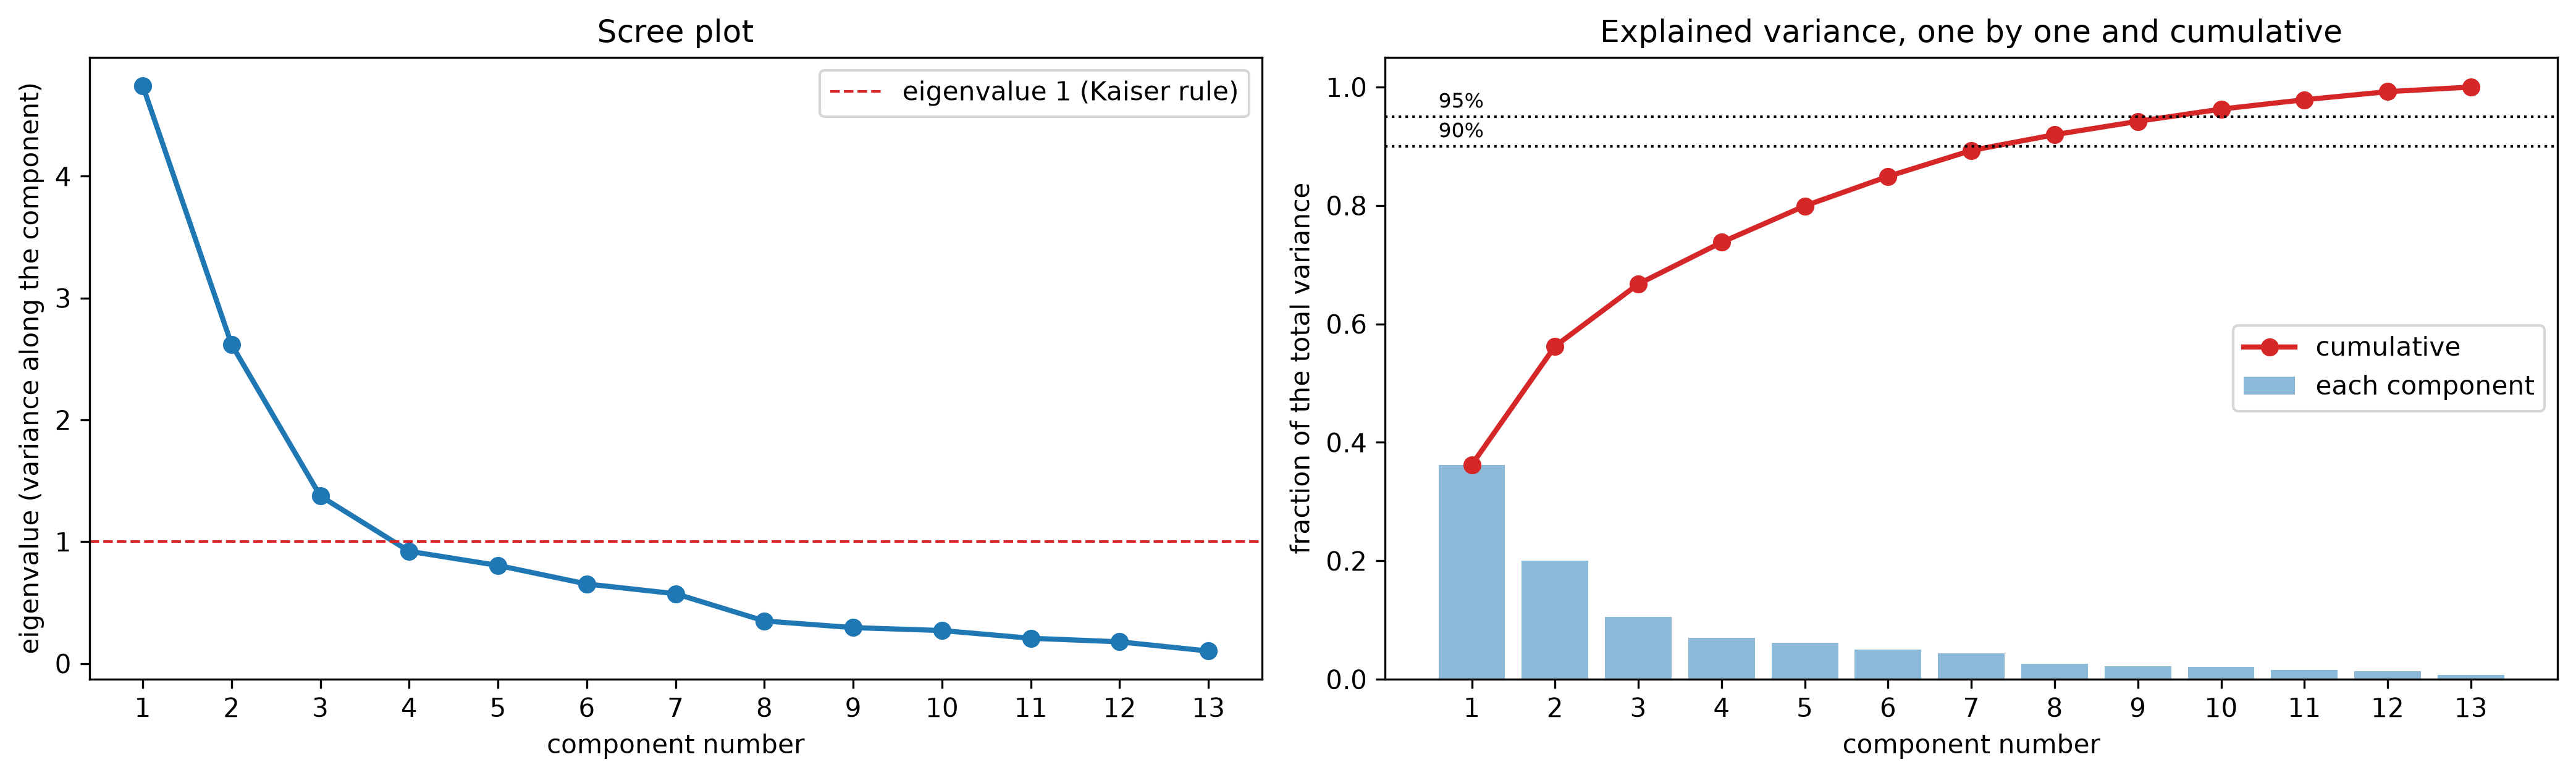

components needed for 90% of the variance: 8
components needed for 95% of the variance: 10
components with eigenvalue above 1       : 3


component,1,2,3,4,5,6,7,8,9,10,11,12,13
eigenvalue,4.7436,2.6193,1.3747,0.9214,0.8051,0.6529,0.5729,0.3491,0.2947,0.2706,0.2074,0.1780,0.1024
explained,0.3623,0.2001,0.1050,0.0704,0.0615,0.0499,0.0438,0.0267,0.0225,0.0207,0.0158,0.0136,0.0078
cumulative,0.3623,0.5624,0.6674,0.7378,0.7993,0.8491,0.8929,0.9196,0.9421,0.9627,0.9786,0.9922,1.0000


In [48]:
ratio = lam_eig / lam_eig.sum()                      # fraction of the total variance explained by each component
cumulative = np.cumsum(ratio)                        # fraction explained by the first k components together
components = np.arange(1, p + 1)                     # component numbers 1, 2, ..., 13

k90 = int(np.argmax(cumulative >= 0.90)) + 1         # smallest k reaching 90%
k95 = int(np.argmax(cumulative >= 0.95)) + 1         # smallest k reaching 95%
k_kaiser = int(np.sum(lam_eig > 1))                  # Kaiser rule: eigenvalues above 1

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))    # two panels side by side
axes[0].plot(components, lam_eig, "o-", color="tab:blue", lw=2)  # the scree plot
axes[0].axhline(1, color="tab:red", ls="dashed", lw=1, label="eigenvalue 1 (Kaiser rule)")  # Kaiser line
axes[0].set_xlabel("component number")               # x-axis label
axes[0].set_ylabel("eigenvalue (variance along the component)")  # y-axis label
axes[0].set_title("Scree plot")                      # title
axes[0].legend()                                     # legend
axes[1].bar(components, ratio, color="tab:blue", alpha=0.5, label="each component")  # one bar each
axes[1].plot(components, cumulative, "o-", color="tab:red", lw=2, label="cumulative")  # running total
for level in [0.90, 0.95]:                           # the two thresholds
    axes[1].axhline(level, color="black", ls="dotted", lw=1)  # a dotted line at 90% and 95%
    axes[1].text(0.6, level + 0.015, f"{level:.0%}", fontsize=8)   # label the line on the left
axes[1].set_xlabel("component number")               # x-axis label
axes[1].set_ylabel("fraction of the total variance")  # y-axis label
axes[1].set_title("Explained variance, one by one and cumulative")  # title
axes[1].legend(loc="center right")                   # legend
for ax in axes:                                      # both panels
    ax.set_xticks(components)                        # a tick at every component
plt.tight_layout()                                   # keep labels from overlapping
plt.show()                                           # draw the figure

print(f"components needed for 90% of the variance: {k90}")
print(f"components needed for 95% of the variance: {k95}")
print(f"components with eigenvalue above 1       : {k_kaiser}")
pd.DataFrame({"eigenvalue": lam_eig, "explained": ratio, "cumulative": cumulative},  # summary table
             index=pd.Index(components, name="component")).T

**Line by line**

- `ratio = lam_eig / lam_eig.sum()` : the fraction of the total variance explained by each component.
- `np.cumsum(ratio)` : the running total, so entry $k - 1$ is the fraction explained by the first $k$ components.
- `int(np.argmax(cumulative >= 0.90)) + 1` : `cumulative >= 0.90` is a boolean array; `np.argmax` of a boolean array
  gives the position of the **first** `True`. Positions start at 0, so we add 1 to get a number of components.
- `int(np.sum(lam_eig > 1))` : counts the eigenvalues above 1. Because they are sorted, these are the first ones.
- Left panel: the scree plot, with a dashed red line at eigenvalue 1. Right panel: one bar per component and the
  cumulative curve, with dotted lines at 90% and 95%.

**Reading the plots and the table.**

- The first component explains **36.2%** of the variance, the first two together **56.2%**, the first three 66.7%.
- **Variance threshold:** 90% needs **8 components** (91.96%; seven give only 89.3%), and 95% needs **10**.
- **Kaiser rule:** three eigenvalues are above 1 (4.74, 2.62, 1.37), so it keeps **3 components**.
- **Elbow:** the scree plot drops steeply from component 1 to 3 and then flattens into a slow decline, so the elbow
  is also at about **3**.

So the rules disagree: 3 against 8 or 10. That is normal, because they answer different questions. The variance
threshold asks "how many numbers do I need to **rebuild** the data almost perfectly?"; the Kaiser rule and the elbow
ask "how many components are clearly **more than noise**?". In Part 8 we will meet a third answer, "how many
components give the best **classifier**?", chosen by cross-validation exactly like $k$ in k-NN (Practical 4). There is
no single right number of components: it depends on what the reduced data will be used for.

## 4b. The wines on the first two principal components

Two components hold 56% of the variance, and two numbers per wine can be drawn on paper. PCA **did not use the
labels**, but we can colour the points by cultivar afterwards to see whether the directions of largest variance
happen to separate them.

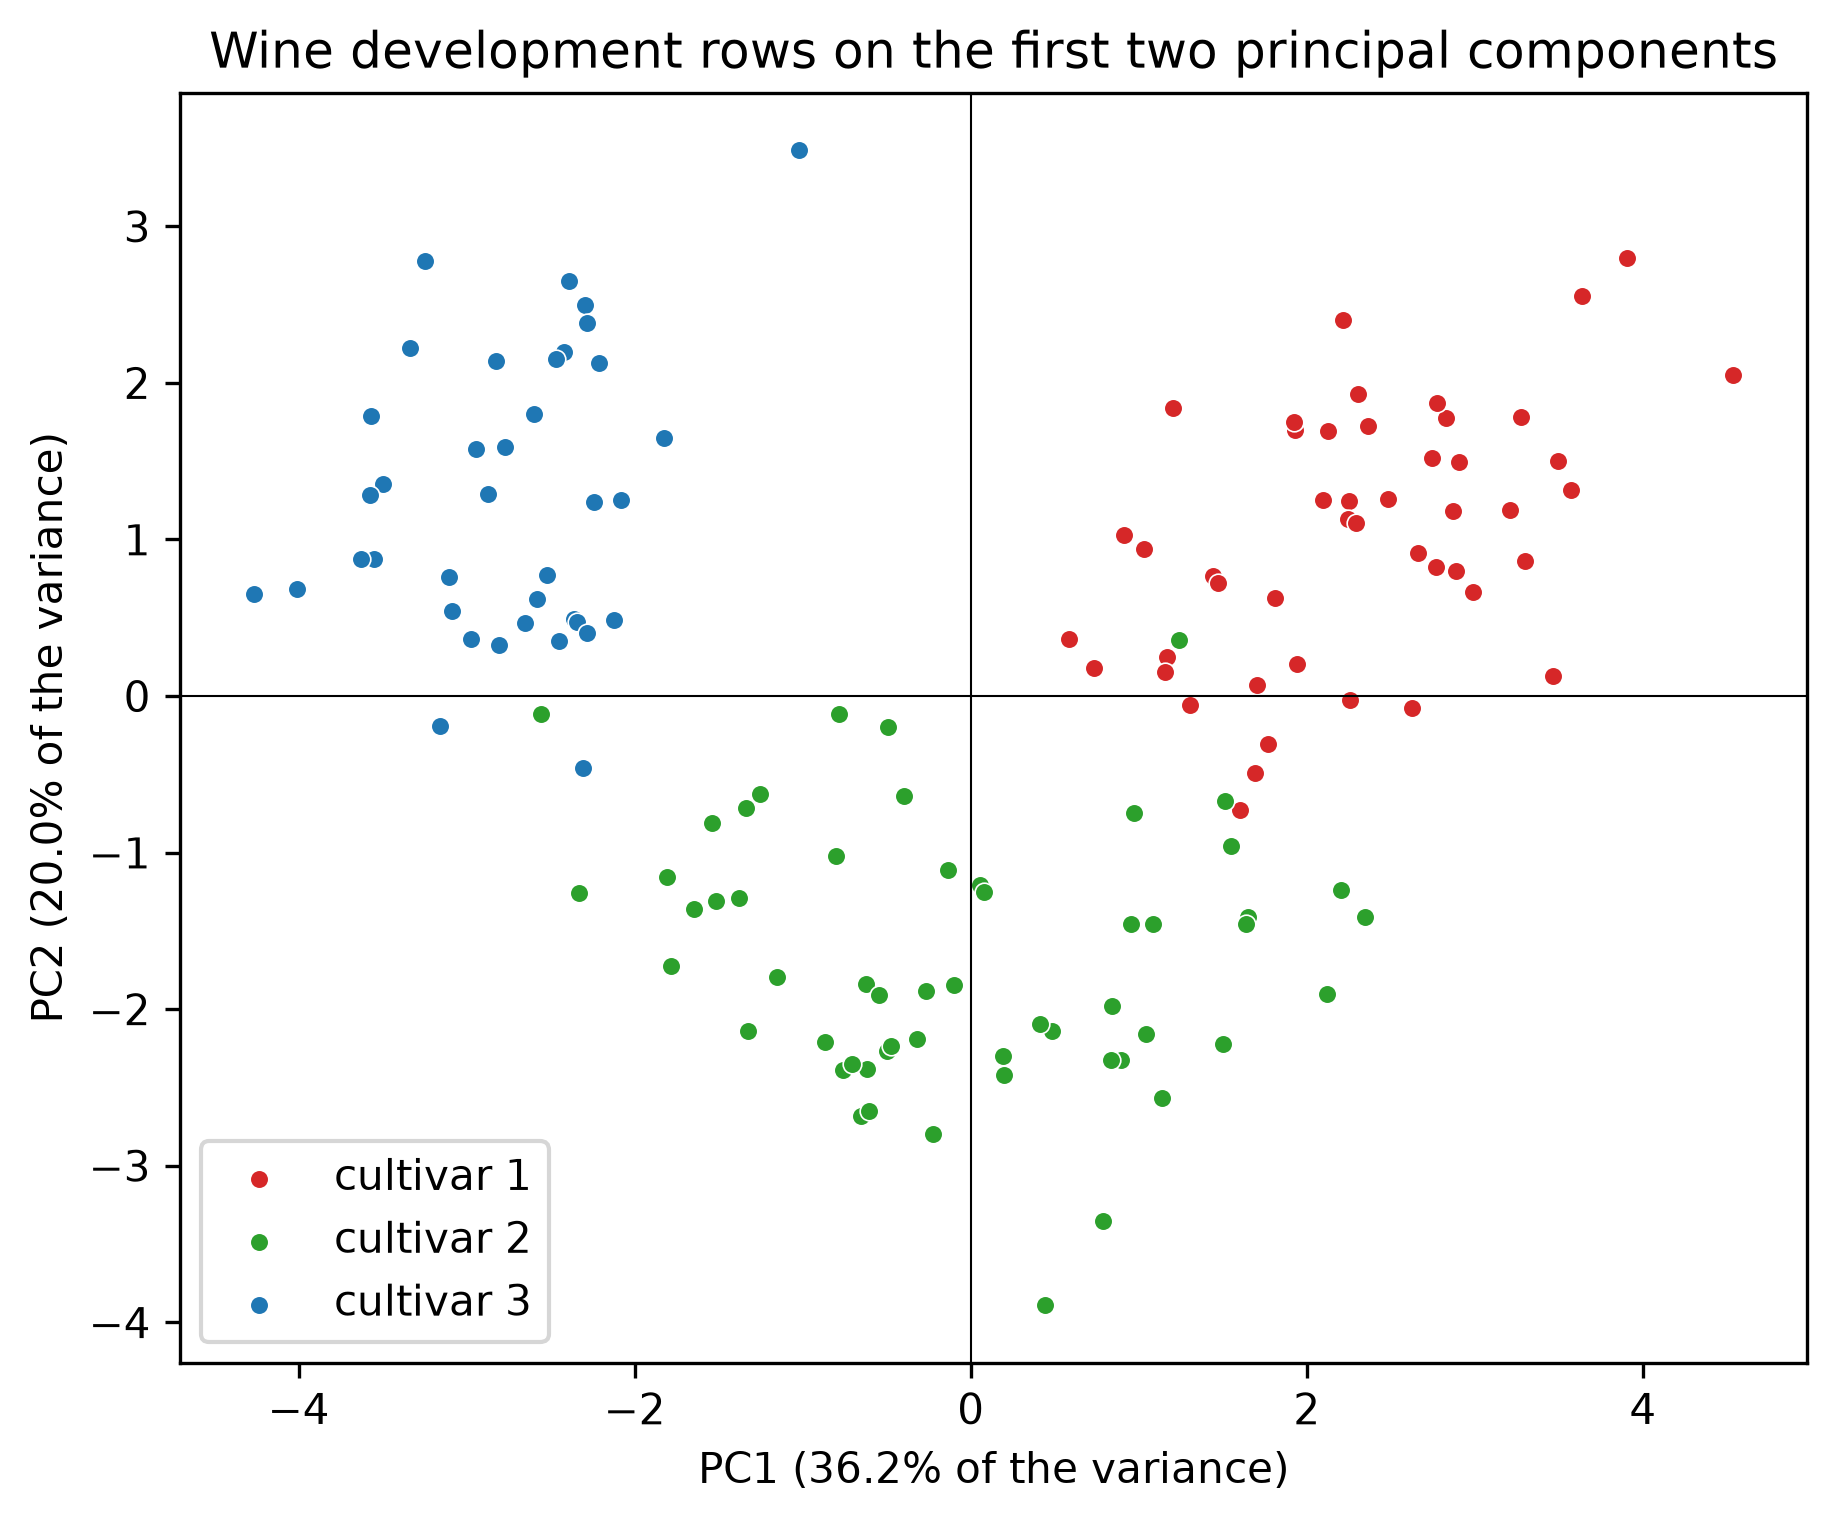

In [49]:
colours_wine = ["tab:red", "tab:green", "tab:blue"]  # one colour per cultivar, used in every plot below

fig, ax = plt.subplots(figsize=(7, 5.5))             # one panel
for c, colour in enumerate(colours_wine):            # one colour per cultivar
    rows = yw_dev == c                               # the development wines of cultivar c
    ax.scatter(scores_eig[rows, 0], scores_eig[rows, 1], s=20, color=colour, label=class_names_wine[c],
               edgecolor="white", linewidth=0.4)
ax.axhline(0, color="black", lw=0.5)                 # horizontal axis line
ax.axvline(0, color="black", lw=0.5)                 # vertical axis line
ax.set_xlabel(f"PC1 ({ratio[0]:.1%} of the variance)")  # x-axis label
ax.set_ylabel(f"PC2 ({ratio[1]:.1%} of the variance)")  # y-axis label
ax.set_title("Wine development rows on the first two principal components")  # title
ax.legend()                                          # legend
plt.show()                                           # draw the figure

**Line by line**

- `colours_wine` : one fixed colour per cultivar, reused in every later plot so the colours always mean the same.
- `rows = yw_dev == c` : a boolean mask selecting the development wines of cultivar `c`.
- `scores_eig[rows, 0]`, `scores_eig[rows, 1]` : their scores on PC1 and PC2 (from Part 2).
- `edgecolor="white", linewidth=0.4` : a thin white rim around each dot, so overlapping dots stay visible.
- `ax.axhline(0, ...)`, `ax.axvline(0, ...)` : thin lines through the centre of the data.

**Reading the plot.** Even though PCA never saw the labels, the three cultivars form three fairly clear groups:
cultivar 1 on the right (high PC1, the phenol-rich wines), cultivar 3 on the left (low PC1), and cultivar 2 at the
bottom (low PC2). This happens because the differences **between** the cultivars are a large part of the variation in
the data, so the directions of largest variance partly line up with them. But there is overlap: some cultivar 2 wines
sit among cultivar 1 and cultivar 3. PCA was not trying to separate the classes; whatever separation we see is a happy
accident. Part 8 will put this plot next to LDA's, which **does** try.

# Part 5: Projection, reconstruction and reconstruction error

## 5a. Keeping $k$ components, and rebuilding the data from them

Keeping only the first $k$ components is a form of **compression**. Every row is described by $k$ numbers instead of
$p$:

$$\text{project:}\quad t_i = V_k^{\top}(z_i - \bar z) \qquad (k \text{ numbers per row}).$$

To see what the compression threw away, map the $k$ numbers back into the original space:

$$\text{reconstruct:}\quad \hat z_i = V_k\, t_i + \bar z \qquad (p \text{ numbers per row again}).$$

The reconstruction $\hat z_i$ is the point on the $k$-dimensional flat surface spanned by the first $k$ directions
that is closest to $z_i$. The **reconstruction error** is the average squared distance between each row and its
reconstruction:

$$\text{error}(k) = \frac{1}{n}\sum_{i=1}^{n} \lVert z_i - \hat z_i \rVert^2 .$$

On the rows PCA was fitted on, this error has an exact value: it is the **variance that was left out**,

$$\text{error}(k) = \frac{n-1}{n}\sum_{j > k} \lambda_j ,$$

because every component we drop removes exactly its own variance. (The factor $\frac{n-1}{n}$ appears because the
error averages over $n$ rows while the eigenvalues divide by $n - 1$.) On **new** rows, such as the test set, there
is no such formula: we have to measure.

development error = left-out variance x (n-1)/n: True
same reconstruction as PCA(3).inverse_transform : True


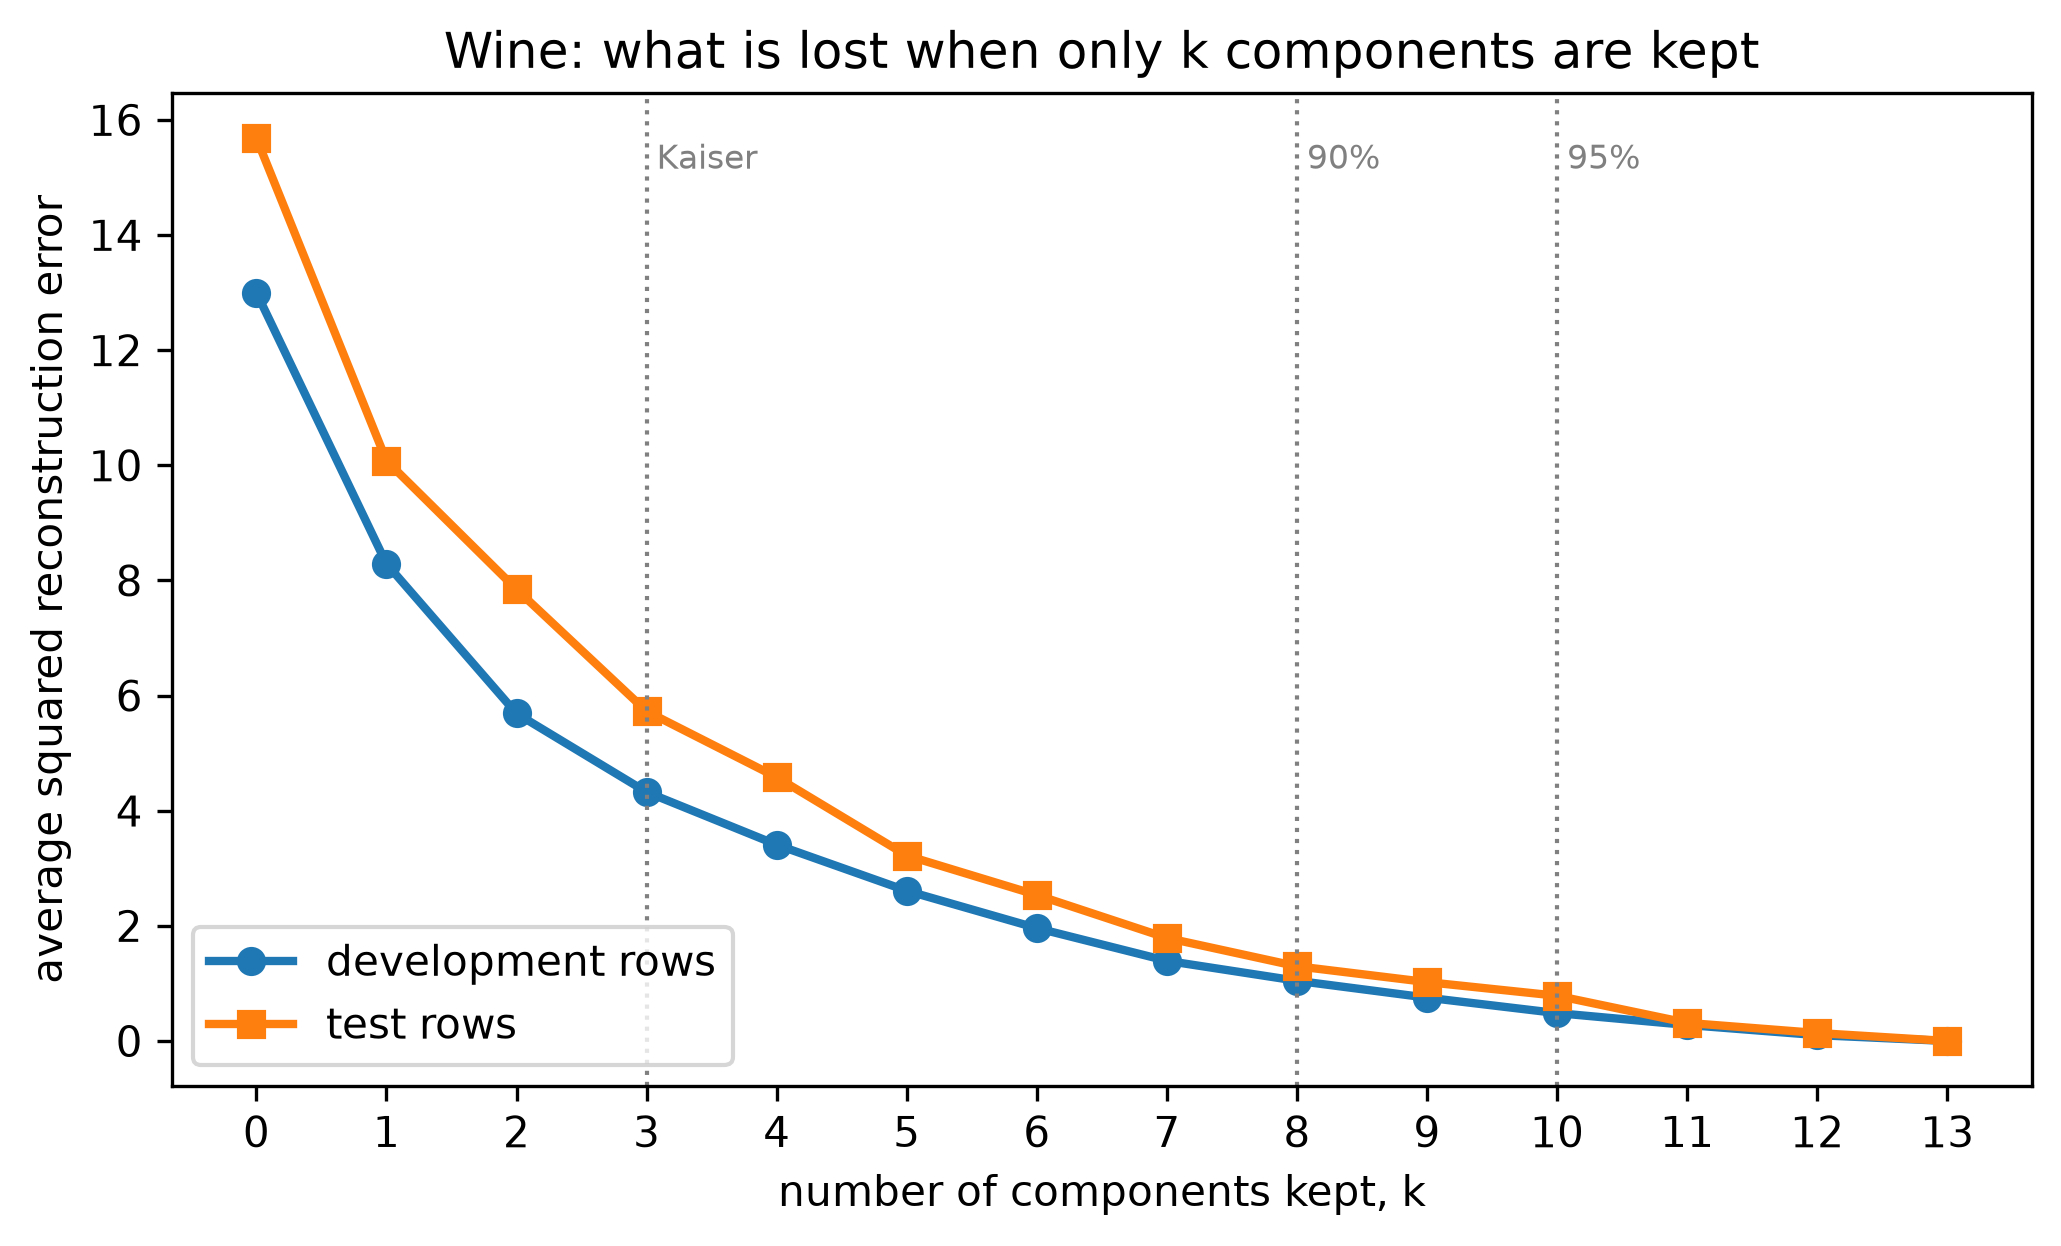

k,0,1,2,3,4,5,6,7,8,9,10,11,12,13
"error, development",13.0000,8.2898,5.6890,4.3239,3.4090,2.6095,1.9612,1.3924,1.0457,0.7531,0.4844,0.2784,0.1017,0.0
"error, test",15.6851,10.0795,7.8456,5.7272,4.5818,3.2217,2.5357,1.7901,1.2983,1.0231,0.7860,0.3145,0.1392,0.0
left-out variance x (n-1)/n,13.0000,8.2898,5.6890,4.3239,3.4090,2.6095,1.9612,1.3924,1.0457,0.7531,0.4844,0.2784,0.1017,0.0


In [50]:
def pca_project(Z, mean, V, k):
    '''Scores of the rows of Z on the first k principal directions.'''
    return (Z - mean) @ V[:, :k]                     # (rows, k): centre with the FITTED mean, then project


def pca_reconstruct(T, mean, V):
    '''Map k scores per row back to the original columns.'''
    k = T.shape[1]                                   # how many components the scores use
    return T @ V[:, :k].T + mean                     # (rows, p): a point in the original space


def reconstruction_error(Z, Z_hat):
    '''Average over the rows of the squared distance between each row and its reconstruction.'''
    return np.mean(np.sum((Z - Z_hat) ** 2, axis=1))


n_w = len(Zw_dev)                                    # 142 development wines
rows = []                                            # one dictionary per row of the table
for k in range(0, p + 1):                            # k = 0 keeps nothing: every row becomes the mean
    T_dev = pca_project(Zw_dev, mean_w, V_eig, k)    # development scores, k per row
    T_test = pca_project(Zw_test, mean_w, V_eig, k)  # the TEST rows, with the development mean and directions
    rows.append({"k": k,                             # one row per k
                 "error, development": reconstruction_error(Zw_dev, pca_reconstruct(T_dev, mean_w, V_eig)),
                 "error, test": reconstruction_error(Zw_test, pca_reconstruct(T_test, mean_w, V_eig)),
                 "left-out variance x (n-1)/n": (n_w - 1) / n_w * lam_eig[k:].sum()})
recon_wine = pd.DataFrame(rows).set_index("k")       # table indexed by k

print("development error = left-out variance x (n-1)/n:",
      np.allclose(recon_wine["error, development"], recon_wine["left-out variance x (n-1)/n"]))
lib3 = PCA(n_components=3).fit(Zw_dev)               # the library, keeping 3 components
ours3 = pca_reconstruct(pca_project(Zw_test, mean_w, V_eig, 3), mean_w, V_eig)  # our test reconstruction
print("same reconstruction as PCA(3).inverse_transform :",
      np.allclose(ours3, lib3.inverse_transform(lib3.transform(Zw_test))))

fig, ax = plt.subplots(figsize=(8, 4.3))             # one panel
ax.plot(recon_wine.index, recon_wine["error, development"], "o-", color="tab:blue", lw=2, label="development rows")
ax.plot(recon_wine.index, recon_wine["error, test"], "s-", color="tab:orange", lw=2, label="test rows")
for k_mark, name in [(k_kaiser, "Kaiser"), (k90, "90%"), (k95, "95%")]:  # the three rules
    ax.axvline(k_mark, color="grey", ls="dotted", lw=1)  # mark the k of a rule
    ax.text(k_mark, ax.get_ylim()[1] * 0.92, f" {name}", fontsize=8, color="grey")  # and name it
ax.set_xticks(range(0, p + 1))                       # a tick at every k
ax.set_xlabel("number of components kept, k")        # x-axis label
ax.set_ylabel("average squared reconstruction error")  # y-axis label
ax.set_title("Wine: what is lost when only k components are kept")  # title
ax.legend()                                          # legend
plt.show()                                           # draw the figure

recon_wine.T.round(4)                                # tiny rounding dust shows as 0

**Line by line**

- `pca_project(Z, mean, V, k)` : centres with the **fitted** mean (the development mean, also for test rows), then
  multiplies by the first `k` directions. `V[:, :k]` keeps the first `k` columns.
- `pca_reconstruct(T, mean, V)` : multiplies the scores by $V_k^{\top}$ and adds the mean back. `T.shape[1]` tells the
  function how many components the scores use.
- `reconstruction_error(Z, Z_hat)` : `np.sum(..., axis=1)` adds the squared differences across the columns of each row
  (the squared distance), and `np.mean` averages over the rows.
- `for k in range(0, p + 1)` : from $k = 0$ (every row is replaced by the mean) to $k = 13$ (nothing is thrown away).
- `(n_w - 1) / n_w * lam_eig[k:].sum()` : the formula above. `lam_eig[k:]` are the eigenvalues of the dropped
  components; for $k = 0$ that is all of them.
- `PCA(n_components=3)` : the library's PCA keeping 3 components. `transform` projects and `inverse_transform`
  reconstructs; we compare with our own two functions on the test rows.
- `ax.text(k_mark, ax.get_ylim()[1] * 0.92, ...)` : writes a small label near the top of each dotted line.
- `recon_wine.T.round(4)` : the table with `k` across the page; rounding to 4 decimals shows the tiny rounding dust at
  $k = 13$ as 0.

**Reading the output and the plot.**

- Both checks print `True`. On the development rows the error **equals the left-out variance** for every $k$, and our
  reconstruction is identical to `PCA(3).inverse_transform`.
- At $k = 0$ the development error is 13.0: replacing every wine by the average wine loses all 13 units of variance.
  Each component removes its own eigenvalue: 8.29 left after one component, 5.69 after two, **4.32 after three** (the
  Kaiser choice keeps two thirds of the variance), **1.05 after eight** (the 90% choice), and 0 after all thirteen.
- The **test** error is a little higher at every $k$ (for example 5.73 against 4.32 at $k = 3$), but it follows the
  same curve. Part of the gap is that the test rows are simply more spread out around the development mean (15.7
  against 13.0 at $k = 0$); the rest is that the directions were fitted to the development rows. Measured as a fraction
  of each set's own spread, three components lose 33% of the development variance and about 37% of the test variance. The
  principal directions found on 142 wines describe new wines almost as well: PCA **generalises**.
- Notice that the curve has no U shape. Reconstruction error always falls as $k$ grows, on new data too, because
  adding components can only bring the reconstruction closer. It cannot choose $k$ by itself, just as the training
  RSS could not choose the number of predictors in Practical 5.

## 5b. Seeing reconstruction: PCA on the Digits images

With 13 chemical measurements we can only *compute* what reconstruction loses. With images we can **look**. Each digit
is a row of 64 pixels, and PCA finds 64 "directions" that are themselves $8 \times 8$ pictures.

Here we do **not** standardise. All pixels are measured in the same units (ink from 0 to 16), so their variances are
directly comparable, and pixels with more variation (the middle of the image, where the strokes are) should count
for more. Standardising would also be impossible: three pixels are 0 in every development image, so their standard
deviation is 0. PCA only centres the data, by subtracting the **mean image**.

pixels that are 0 in every development image: [ 0 32 39]
components for 90% of the variance: 21;  for 95%: 28  (out of 64)
the first five components explain [0.151 0.135 0.116 0.083 0.058]
same directions as PCA on the raw pixels: True


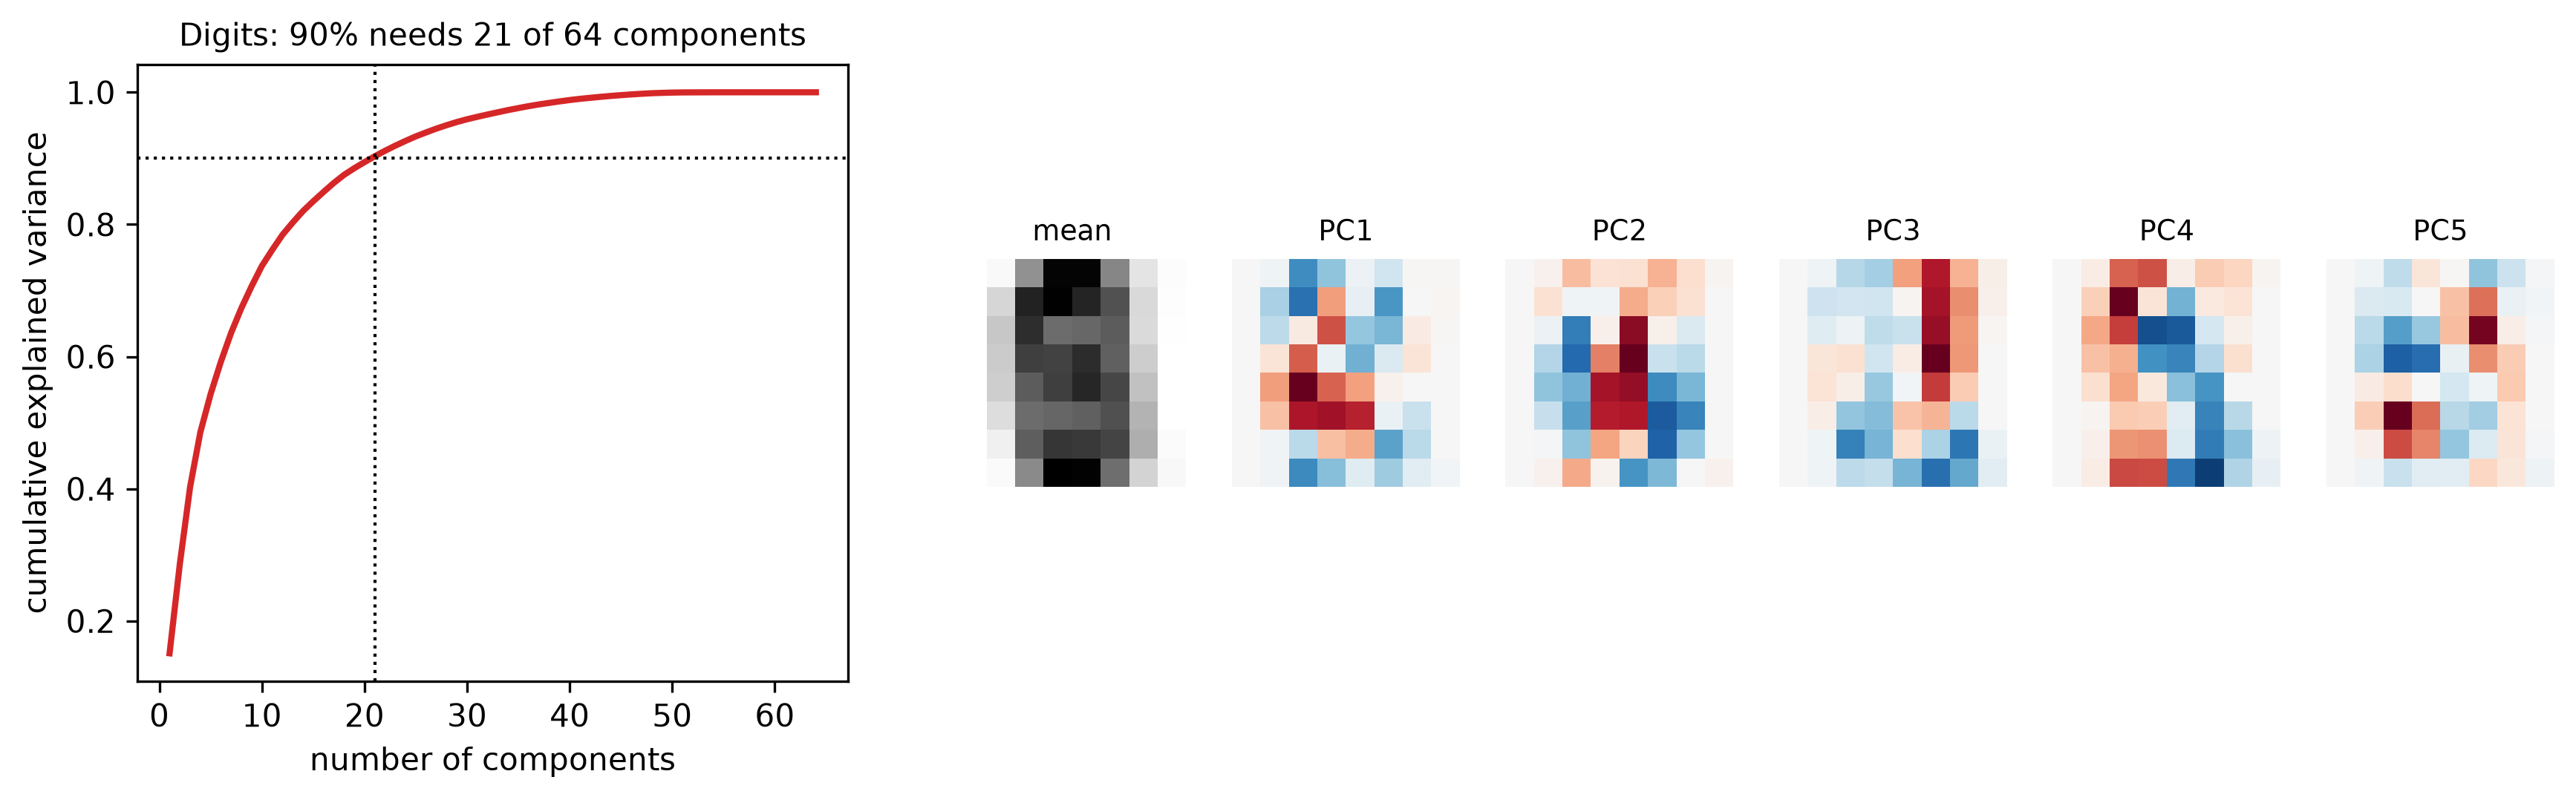

In [51]:
mean_d, V_d, lam_d = pca_svd(Xd_dev)                 # PCA of the RAW pixels (no standardising)
ratio_d = lam_d / lam_d.sum()                        # fraction explained by each component
cum_d = np.cumsum(ratio_d)                           # cumulative fraction
k90_d = int(np.argmax(cum_d >= 0.90)) + 1            # smallest k reaching 90%
k95_d = int(np.argmax(cum_d >= 0.95)) + 1            # smallest k reaching 95%
print("pixels that are 0 in every development image:", np.flatnonzero(Xd_dev.std(axis=0) == 0))
print(f"components for 90% of the variance: {k90_d};  for 95%: {k95_d}  (out of 64)")
print(f"the first five components explain {ratio_d[:5].round(3)}")
print("same directions as PCA on the raw pixels:", np.allclose(V_d.T[:20], PCA(20).fit(Xd_dev).components_))

fig = plt.figure(figsize=(14, 3.6))                  # an empty figure; panels are added below
ax = fig.add_subplot(1, 3, 1)                        # the left third: the cumulative curve
ax.plot(range(1, 65), cum_d, color="tab:red", lw=2)  # cumulative explained variance
ax.axhline(0.9, color="black", ls="dotted", lw=1)    # the 90% level
ax.axvline(k90_d, color="black", ls="dotted", lw=1)  # and the k that reaches it
ax.set_xlabel("number of components")                # x-axis label
ax.set_ylabel("cumulative explained variance")       # y-axis label
ax.set_title(f"Digits: 90% needs {k90_d} of 64 components", fontsize=10)  # title
ax = fig.add_subplot(1, 9, 4)                        # a small panel for the mean image
ax.imshow(mean_d.reshape(8, 8), cmap="gray_r")       # the mean image
ax.set_title("mean", fontsize=9)                     # its title
ax.axis("off")                                       # no axes around a picture
for j in range(5):                                   # the first five principal directions as pictures
    ax = fig.add_subplot(1, 9, 5 + j)                # the next small panel
    limit = np.abs(V_d[:, j]).max()                  # symmetric colour limits
    ax.imshow(V_d[:, j].reshape(8, 8), cmap="RdBu_r", vmin=-limit, vmax=limit)   # red +, blue -
    ax.set_title(f"PC{j + 1}", fontsize=9)           # its title
    ax.axis("off")                                   # no axes around a picture
plt.show()                                           # draw the figure

**Line by line**

- `pca_svd(Xd_dev)` : our SVD-based PCA from Part 3, on the 1437 raw development images. The mean it returns is the
  mean image.
- `np.flatnonzero(Xd_dev.std(axis=0) == 0)` : the positions of the pixels that never change.
- `PCA(20).fit(Xd_dev).components_` : the library's first 20 directions, to check ours.
- `fig.add_subplot(1, 3, 1)` : divides the figure into 1 row and 3 columns and draws in the first; `add_subplot(1, 9, 4)`
  then divides it into 9 narrow columns, so the six small pictures fit into the remaining space.
- `V_d[:, j].reshape(8, 8)` : a principal direction is a vector of 64 weights, one per pixel, so it can be drawn as a
  picture. `cmap="RdBu_r"` with symmetric limits shows positive weights in red, negative in blue and 0 in white.

**Reading the output and the plots.**

- Pixels 0, 32 and 39 are blank in every development image (the left and right edges). Because of them, the
  development images really live in at most $64 - 3 = 61$ dimensions.
- The first component explains 15.1% of the variance, the second 13.5%, the third 11.6%. **21 components** of 64 keep
  90% of the variance and **28** keep 95%. The cumulative curve rises steeply and then flattens: most of the
  variation between handwritten digits lives in about 20 directions.
- The **mean image** is a blurry blob, the average of all ten digits. The principal directions are patterns of red
  (more ink than the mean image) and blue (less ink). They are not digits themselves: they are the patterns in which
  handwritten digits differ most from the average one. Every digit is the mean image plus a weighted sum of such
  patterns, and its scores are the weights.

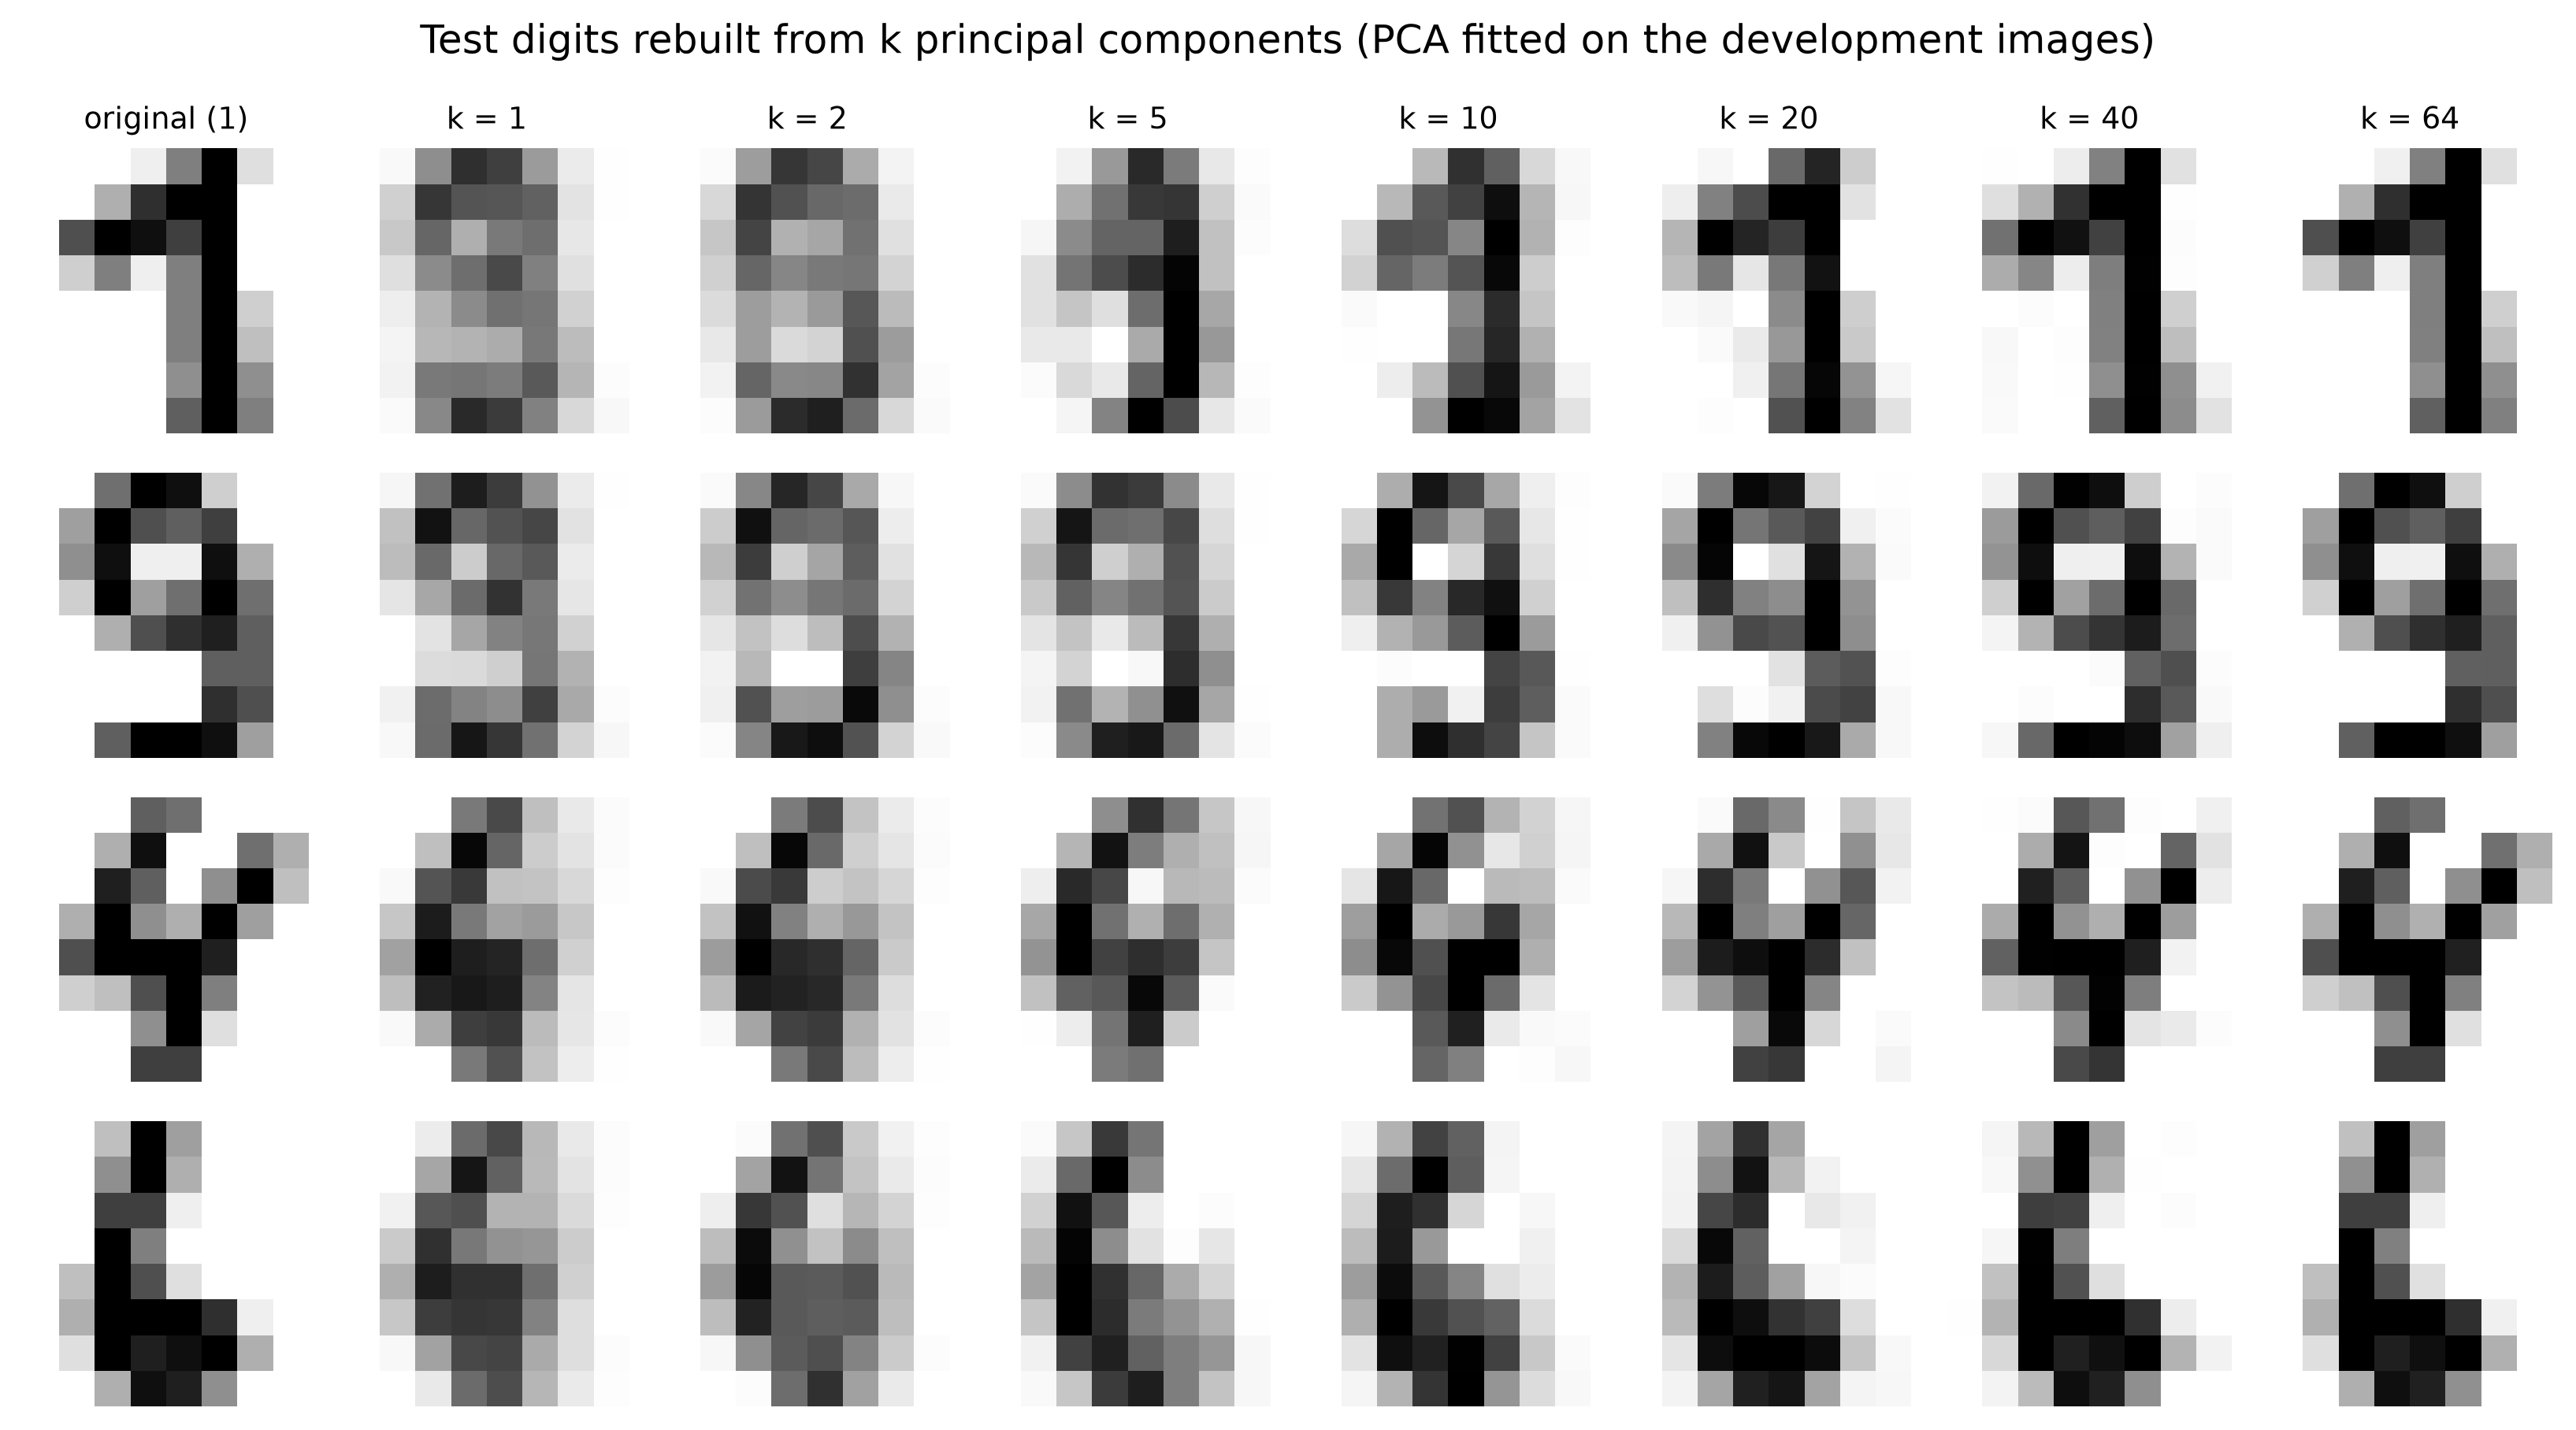

mean squared error per pixel (pixel values run from 0 to 16):


k,1,2,5,10,20,40,64
development,15.9414,13.4026,8.5764,4.9334,1.9849,0.2206,0.0
test,16.1817,13.5368,8.4596,4.8789,2.0232,0.2371,0.0


In [52]:
ks = [1, 2, 5, 10, 20, 40, 64]                       # numbers of components to try
examples = [0, 1, 2, 3]                              # four test images

fig, axes = plt.subplots(len(examples), len(ks) + 1, figsize=(11, 6.2))  # a grid of small panels
for row, i in enumerate(examples):                   # one row of pictures per test digit
    axes[row, 0].imshow(Xd_test[i].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)  # the original
    axes[row, 0].set_title(f"original ({yd_test[i]})" if row == 0 else "", fontsize=9)
    for col, k in enumerate(ks, start=1):            # one column per k
        T = pca_project(Xd_test[i:i + 1], mean_d, V_d, k)          # k numbers instead of 64
        image = pca_reconstruct(T, mean_d, V_d)                    # back to 64 pixels
        axes[row, col].imshow(image.reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)  # the reconstruction
        if row == 0:                                 # titles only on the top row
            axes[row, col].set_title(f"k = {k}", fontsize=9)  # column title
for ax in axes.ravel():                              # every small panel
    ax.axis("off")                                   # no axes around a picture
plt.suptitle("Test digits rebuilt from k principal components (PCA fitted on the development images)")
plt.tight_layout()                                   # keep labels from overlapping
plt.show()                                           # draw the figure

def pixel_error(X, k):
    '''Mean squared error per pixel when every image of X is rebuilt from k components.'''
    X_hat = pca_reconstruct(pca_project(X, mean_d, V_d, k), mean_d, V_d)   # rebuild every image
    return np.mean((X - X_hat) ** 2)                 # average over all images and all 64 pixels

errors_d = pd.DataFrame({"development": [pixel_error(Xd_dev, k) for k in ks],   # one value per k
                         "test": [pixel_error(Xd_test, k) for k in ks]},
                        index=pd.Index(ks, name="k"))
print("mean squared error per pixel (pixel values run from 0 to 16):")
errors_d.T.round(4)                                  # k across the page

**Line by line**

- `ks` : the numbers of components to try, from 1 to all 64.
- `Xd_test[i:i + 1]` : the slice keeps a two-dimensional shape, `(1, 64)`, so the image can go through `pca_project`
  like a matrix with one row.
- `pca_project(...)` gives $k$ numbers; `pca_reconstruct(...)` turns them back into 64 pixels, which `reshape(8, 8)`
  draws. `vmin=0, vmax=16` uses the same grey scale for every picture, so they can be compared.
- `pixel_error(X, k)` : rebuilds every image of `X` from `k` components and returns the mean squared error **per
  pixel**. `np.mean((X - X_hat) ** 2)` averages over all images and all 64 pixels.
- The table: `pixel_error` for every $k$, on the development and on the test images.

**Reading the pictures and the table.**

- With **1 or 2 components** every reconstruction looks much the same: a smudge close to the mean image, with a hint
  of the digit. Two numbers are not enough to tell a 1 from a 9.
- With **5 components** the shapes start to appear, and with **10** the digits can be read (the 9, 4 and 6 are clear).
- With **20 components** the reconstructions are good, and with **40** they are almost indistinguishable from the
  originals. With all **64** they are exact.
- The table measures the same thing. The error per pixel falls from 16.2 (one component) to 4.9 (ten), 2.0 (twenty) and
  0.24 (forty). Remember that pixel values run from 0 to 16, so an average squared error of 2 means a typical pixel is
  off by about $\sqrt{2} \approx 1.4$ shades out of 16.
- The development and test errors are almost equal: the 20 directions learned from 1437 images describe new
  handwriting just as well. A digit stored as 20 numbers instead of 64 keeps nearly everything we need to recognise it,
  which is what makes PCA useful for compression.

# Part 6: Fisher's Linear Discriminant Analysis for two classes

## 6a. Fisher's criterion

PCA chose the direction in which the data are most **spread out**. For classification that is the wrong question: we
want the direction in which the **classes** are most **separated**. In 1936 Ronald Fisher turned this into a precise
criterion.

Project every row onto a direction $w$. For class $c$ (0 or 1), let

- $m_c = w^{\top}\mu_c$ be the projected class mean ($\mu_c$ is the mean of the class in the original space), and
- $s_c^2 = \sum_{i \in c} (w^{\top}x_i - m_c)^2$ be the projected **within-class scatter**: how spread out the class is
  along $w$.

A good direction puts the two projected means far apart **and** keeps each class narrow, so Fisher's criterion divides
one by the other:

$$J(w) = \frac{(m_1 - m_0)^2}{s_0^2 + s_1^2}.$$

Two matrices make this easy to compute and to maximise. The numerator is
$\big(w^{\top}(\mu_1 - \mu_0)\big)^2 = w^{\top} S_B\, w$ and the denominator is $w^{\top} S_W\, w$, where

$$S_B = (\mu_1 - \mu_0)(\mu_1 - \mu_0)^{\top}, \qquad
S_W = \sum_{c} \sum_{i \in c} (x_i - \mu_c)(x_i - \mu_c)^{\top}.$$

$S_W$, the **within-class scatter matrix**, describes the shape of the classes around their own means; $S_B$, the
**between-class scatter matrix**, describes how far apart the two means are. Setting the derivative of
$J(w) = \frac{w^{\top}S_B w}{w^{\top}S_W w}$ to zero gives $S_B w \propto S_W w$. But $S_B w = (\mu_1 - \mu_0)\,
\big((\mu_1 - \mu_0)^{\top}w\big)$ always points along $\mu_1 - \mu_0$, so $S_W w$ must too, and therefore

$$\boxed{\,w \;\propto\; S_W^{-1}(\mu_1 - \mu_0)\,}.$$

That is Fisher's linear discriminant: one line of linear algebra. Read it as "start from the direction joining the two
means, then **correct it for the shape of the classes**": multiplying by $S_W^{-1}$ turns the direction away from
directions in which the classes are widely spread. If the classes were round, $S_W$ would be a multiple of $I$ and
Fisher's direction would simply be $\mu_1 - \mu_0$. (Only the direction matters: $J(2w) = J(w)$, so we scale $w$ to
length 1.)

To see the difference between the three ideas (largest variance, joining the means, Fisher), we simulate two classes
in two dimensions: two long, thin, parallel clouds, side by side.

In [53]:
def fisher_J(w, X0, X1):
    '''Fisher's criterion of direction w: (difference of projected means)^2 / (sum of within-class scatters).'''
    a, b = X0 @ w, X1 @ w                            # the two classes projected onto w
    between = (b.mean() - a.mean()) ** 2             # how far apart the projected class means are
    within = np.sum((a - a.mean()) ** 2) + np.sum((b - b.mean()) ** 2)   # spread inside the classes
    return between / within


def fisher_direction(X0, X1):
    '''Fisher's LDA direction for two classes: S_W^{-1} (mu_1 - mu_0), scaled to length 1.'''
    mu0, mu1 = X0.mean(axis=0), X1.mean(axis=0)      # the two class means
    S_W = (X0 - mu0).T @ (X0 - mu0) + (X1 - mu1).T @ (X1 - mu1)   # within-class scatter matrix
    w = np.linalg.solve(S_W, mu1 - mu0)              # solve S_W w = mu_1 - mu_0 (no explicit inverse)
    return w / np.linalg.norm(w)                     # only the direction matters


# a simulated two-class dataset: two long, parallel clouds
angle = np.radians(45)                               # the long axis of both clouds points at 45 degrees
R = np.array([[np.cos(angle), -np.sin(angle)],       # rotation matrix, row 1
              [np.sin(angle), np.cos(angle)]])       # rotation by 45 degrees
S_cloud = R @ np.diag([4.0, 0.15]) @ R.T             # covariance: variance 4 along the long axis, 0.15 across
A = rng.multivariate_normal([0.0, 0.0], S_cloud, size=150)     # class 0: 150 points around (0, 0)
B = rng.multivariate_normal([1.6, 0.0], S_cloud, size=150)     # class 1: 150 points around (1.6, 0)
toy = np.vstack([A, B])                              # all 300 points, for PCA

w_pca = pca_eigen(toy)[1][:, 0]                      # first principal direction of all the points (no labels)
w_mean = (B.mean(axis=0) - A.mean(axis=0))           # the vector joining the class means
w_mean = w_mean / np.linalg.norm(w_mean)             # the direction joining the two class means
w_fisher = fisher_direction(A, B)                    # Fisher's direction

rows = []                                            # one dictionary per row of the table
for name, w in [("first principal direction", w_pca), ("difference of the means", w_mean), ("Fisher", w_fisher)]:
    a, b = A @ w, B @ w                              # projections of the two classes
    threshold = (a.mean() + b.mean()) / 2            # a simple rule: cut halfway between the projected means
    side = np.sign(b.mean() - a.mean())              # which side of the cut class 1 lies on
    accuracy = np.mean(np.r_[side * (a - threshold) < 0, side * (b - threshold) > 0])  # fraction right
    rows.append({"direction": name, "angle (degrees)": np.degrees(np.arctan2(w[1], w[0])) % 180,  # one row each
                 "J (Fisher)": fisher_J(w, A, B), "accuracy of the halfway cut": accuracy})
toy_table = pd.DataFrame(rows).set_index("direction")  # one row per direction
toy_table                                            # display the table

,angle (degrees),J (Fisher),accuracy of the halfway cut
direction,,,
first principal direction,38.7904,0.0013,0.62
difference of the means,1.0100,0.0038,0.68
Fisher,135.4769,0.0302,0.94


**Line by line**

- `fisher_J(w, X0, X1)` : the criterion exactly as defined above. `X0 @ w` projects every row of class 0 onto `w`.
- `fisher_direction(X0, X1)` :
  - `(X0 - mu0).T @ (X0 - mu0) + (X1 - mu1).T @ (X1 - mu1)` : the within-class scatter matrix $S_W$, one matrix
    product per class.
  - `np.linalg.solve(S_W, mu1 - mu0)` : solves $S_W\,w = \mu_1 - \mu_0$, which gives $w = S_W^{-1}(\mu_1 - \mu_0)$
    without computing the inverse (Practical 5, 2a).
  - `w / np.linalg.norm(w)` : scales the direction to length 1.
- The simulated data:
  - `R` : the matrix that rotates by 45 degrees.
  - `R @ np.diag([4.0, 0.15]) @ R.T` : a covariance matrix with variance 4 along the 45-degree line and only 0.15
    across it, so each cloud is long and thin and tilted by 45 degrees.
  - `rng.multivariate_normal(mean, cov, size=150)` : 150 random points from a two-dimensional normal distribution with
    that mean and covariance. Class 0 is centred at $(0, 0)$, class 1 at $(1.6, 0)$: the same shape, moved sideways.
- `pca_eigen(toy)[1][:, 0]` : the first principal direction of all 300 points together (PCA ignores the labels).
- `np.r_[a, b]` : glues two arrays end to end. The "halfway cut" classifies a point as class 1 when its projection is
  on class 1's side of the midpoint between the two projected means; the accuracy is the fraction classified correctly.
- `np.degrees(np.arctan2(w[1], w[0])) % 180` : the angle of each direction.

**Reading the table.**

| direction | angle | $J$ | accuracy of the halfway cut |
|-|-|-|-|
| first principal direction | 38.8 degrees | 0.0013 | 62% |
| difference of the means | 1.0 degrees | 0.0038 | 68% |
| Fisher | 135.5 degrees | **0.0302** | **94%** |

Fisher's direction has a criterion about **23 times** larger than the principal direction's and 8 times larger than the
mean difference's, and the simple halfway cut along it classifies 94% of the points correctly, against 62% and 68%.
(The values of $J$ are small numbers only because the denominator adds up squared deviations over all 300 points;
what matters is the comparison between directions.) The figures below show why.

## 6b. The three directions in pictures

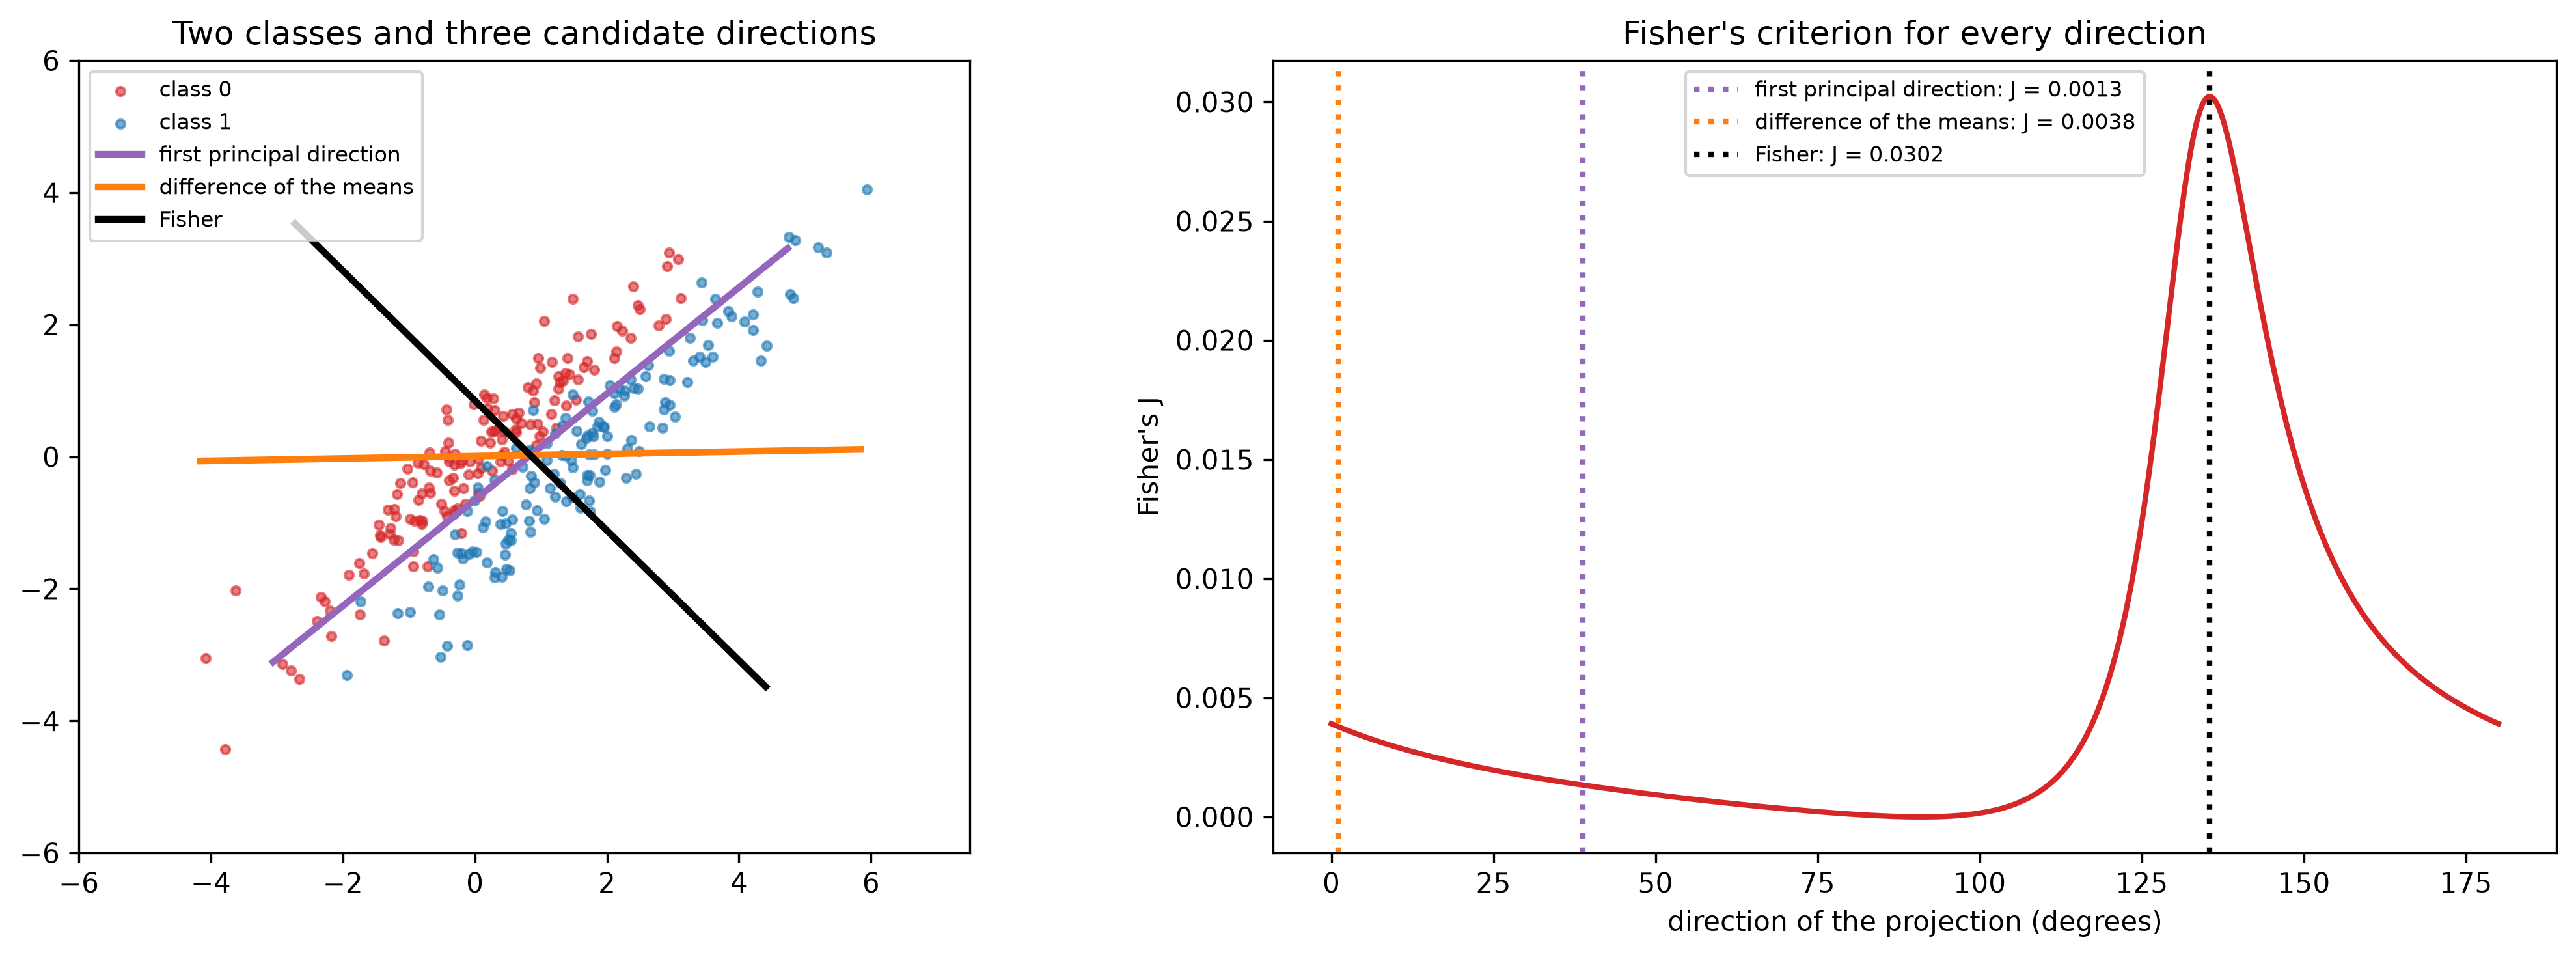

largest J over all 721 angles: 0.0302 at 135.50 degrees


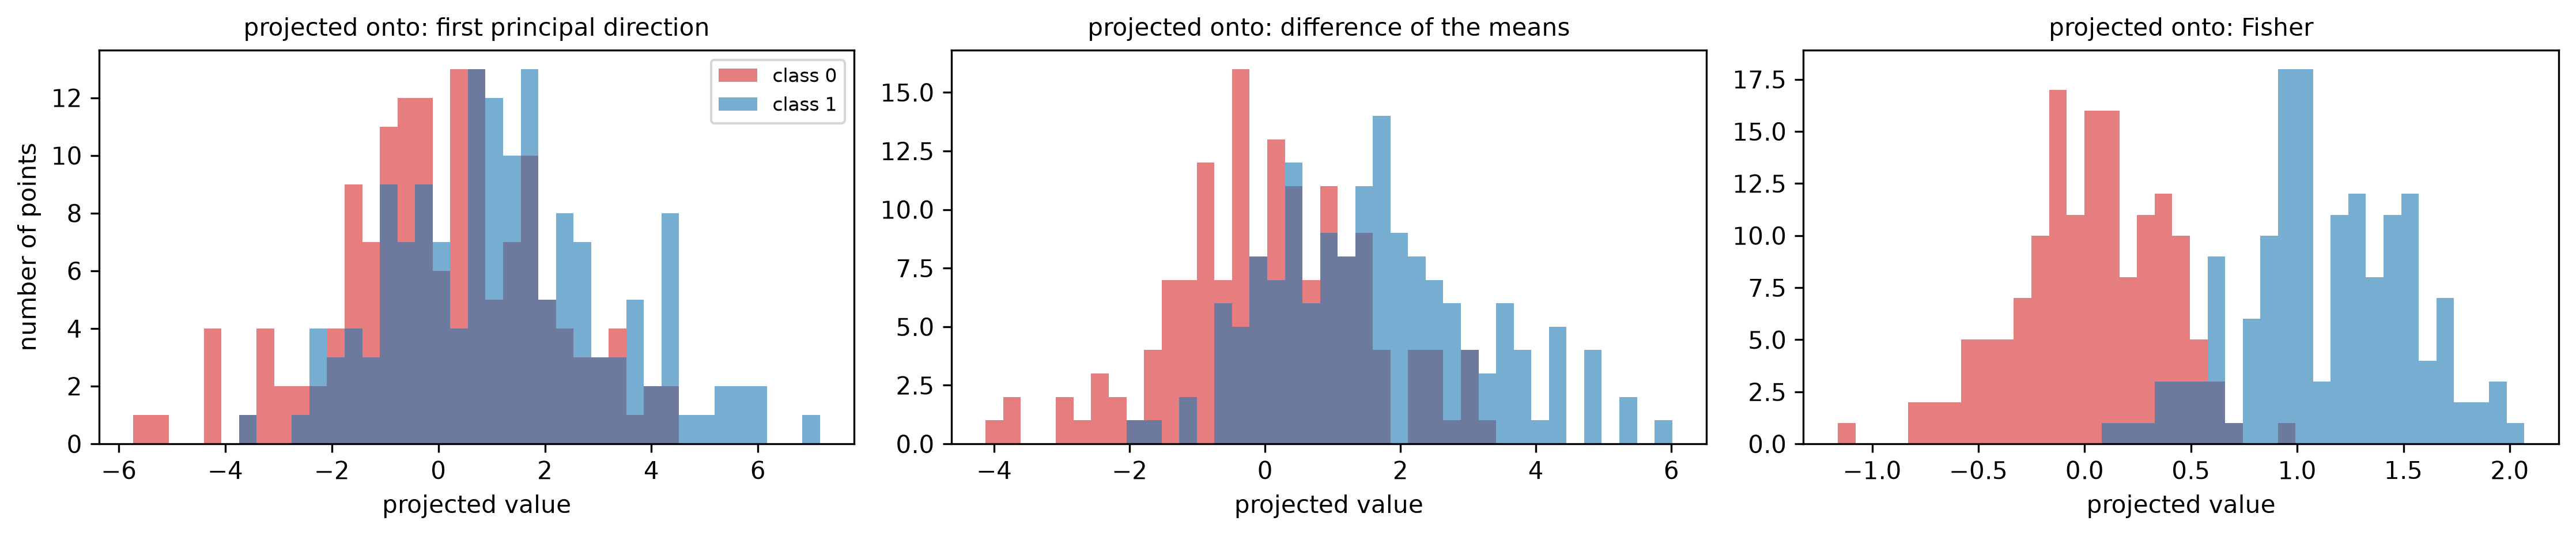

In [54]:
colours_dir = {"first principal direction": "tab:purple", "difference of the means": "tab:orange", "Fisher": "black"}
vectors = {"first principal direction": w_pca, "difference of the means": w_mean, "Fisher": w_fisher}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))      # two panels
ax = axes[0]                                         # left panel: the data
ax.scatter(A[:, 0], A[:, 1], s=10, color="tab:red", alpha=0.6, label="class 0")  # class 0
ax.scatter(B[:, 0], B[:, 1], s=10, color="tab:blue", alpha=0.6, label="class 1")  # class 1
centre = toy.mean(axis=0)                            # lines are drawn through the centre
for name, w in vectors.items():                      # draw each direction
    ax.plot(*np.column_stack([centre - 5 * w, centre + 5 * w]), color=colours_dir[name], lw=2.5, label=name)
ax.set_aspect("equal")                               # same scale on both axes
ax.set_xlim(-6, 7.5)                                 # horizontal range
ax.set_ylim(-6, 6)                                   # vertical range
ax.set_title("Two classes and three candidate directions")  # title
ax.legend(fontsize=8, loc="upper left")              # legend

ax = axes[1]                                         # right panel: J for every angle
angles = np.linspace(0, 180, 721)                    # every direction, in steps of a quarter degree
J_curve = [fisher_J(np.array([np.cos(np.radians(t)), np.sin(np.radians(t))]), A, B)   # J of the unit vector
           for t in angles]                          # at angle t, for every angle
ax.plot(angles, J_curve, color="tab:red", lw=2)      # the J curve
for name in vectors:                                 # one dotted line per direction
    t = toy_table.loc[name, "angle (degrees)"]       # the angle of this direction
    J_value = toy_table.loc[name, "J (Fisher)"]      # its criterion, from the table
    ax.axvline(t, color=colours_dir[name], ls="dotted", lw=2, label=f"{name}: J = {J_value:.4f}")
ax.set_xlabel("direction of the projection (degrees)")  # x-axis label
ax.set_ylabel("Fisher's J")                          # y-axis label
ax.set_title("Fisher's criterion for every direction")  # title
ax.legend(fontsize=8)                                # legend
plt.tight_layout()                                   # keep labels from overlapping
plt.show()                                           # draw the figure

print(f"largest J over all {len(angles)} angles: {max(J_curve):.4f} at {angles[int(np.argmax(J_curve))]:.2f} degrees")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))    # three panels, one per direction
for ax, (name, w) in zip(axes, vectors.items()):     # one panel per direction
    a, b = A @ w, B @ w                              # the two classes projected
    bins = np.linspace(min(a.min(), b.min()), max(a.max(), b.max()), 40)  # shared bins
    ax.hist(a, bins=bins, color="tab:red", alpha=0.6, label="class 0")  # class 0
    ax.hist(b, bins=bins, color="tab:blue", alpha=0.6, label="class 1")  # class 1
    ax.set_title(f"projected onto: {name}", fontsize=10)  # title
    ax.set_xlabel("projected value")                 # x-axis label
axes[0].legend(fontsize=8)                           # legend on the first panel
axes[0].set_ylabel("number of points")               # y-axis label
plt.tight_layout()                                   # keep labels from overlapping
plt.show()                                           # draw the figure

**Line by line**

- Left panel: the two classes, and each direction drawn as a line through the centre of the data
  (`centre - 5 * w` to `centre + 5 * w`).
- Right panel: Fisher's $J$ for 721 directions from 0 to 180 degrees, with a dotted line at each of our three
  directions. `np.array([np.cos(...), np.sin(...)])` is the unit vector at angle $t$.
- Bottom row: for each direction, histograms of the projected values of the two classes, with shared bins so the
  two colours can be compared.

**Reading the plots.**

- **First principal direction (purple)**: it runs along the length of the clouds, because that is where all 300
  points spread out the most. But along that line the two classes lie right on top of each other: the histograms
  overlap almost completely. **The direction of largest variance is the worst direction for classification here.**
- **Difference of the means (orange)**: horizontal, from one class centre to the other. Better, but each cloud is
  tilted, so along this line each class is still long, and the histograms overlap a lot.
- **Fisher (black)**: at 135.5 degrees, almost perpendicular to the long axis of the clouds. Along this direction each
  class is thin, so even the small distance between the means is enough: the two histograms are almost completely
  separate.
- The $J$ curve has a single sharp peak, and the largest of all 721 values (0.0302 at 135.5 degrees) is exactly
  Fisher's direction: the formula $S_W^{-1}(\mu_1 - \mu_0)$ really finds the maximum.

This little example is the central lesson of the practical. **PCA keeps the directions of large spread, whether or
not they separate the classes. LDA keeps the directions that separate the classes, whether or not they are large.**

## 6c. Fisher's direction for the Breast Cancer data

Now a real two-class problem in 30 dimensions. We can no longer try every direction, but we can compare Fisher's
direction with the first principal direction, with the mean difference, and with 20 000 random directions, and check it
against scikit-learn's `LinearDiscriminantAnalysis`.

Fisher's J, first principal direction : 0.01568
Fisher's J, difference of the means   : 0.01838
Fisher's J, Fisher's direction        : 0.03285
largest J among 20 000 random directions: 0.02125

cosine of the angle between our direction and the library's: -1.0000000000


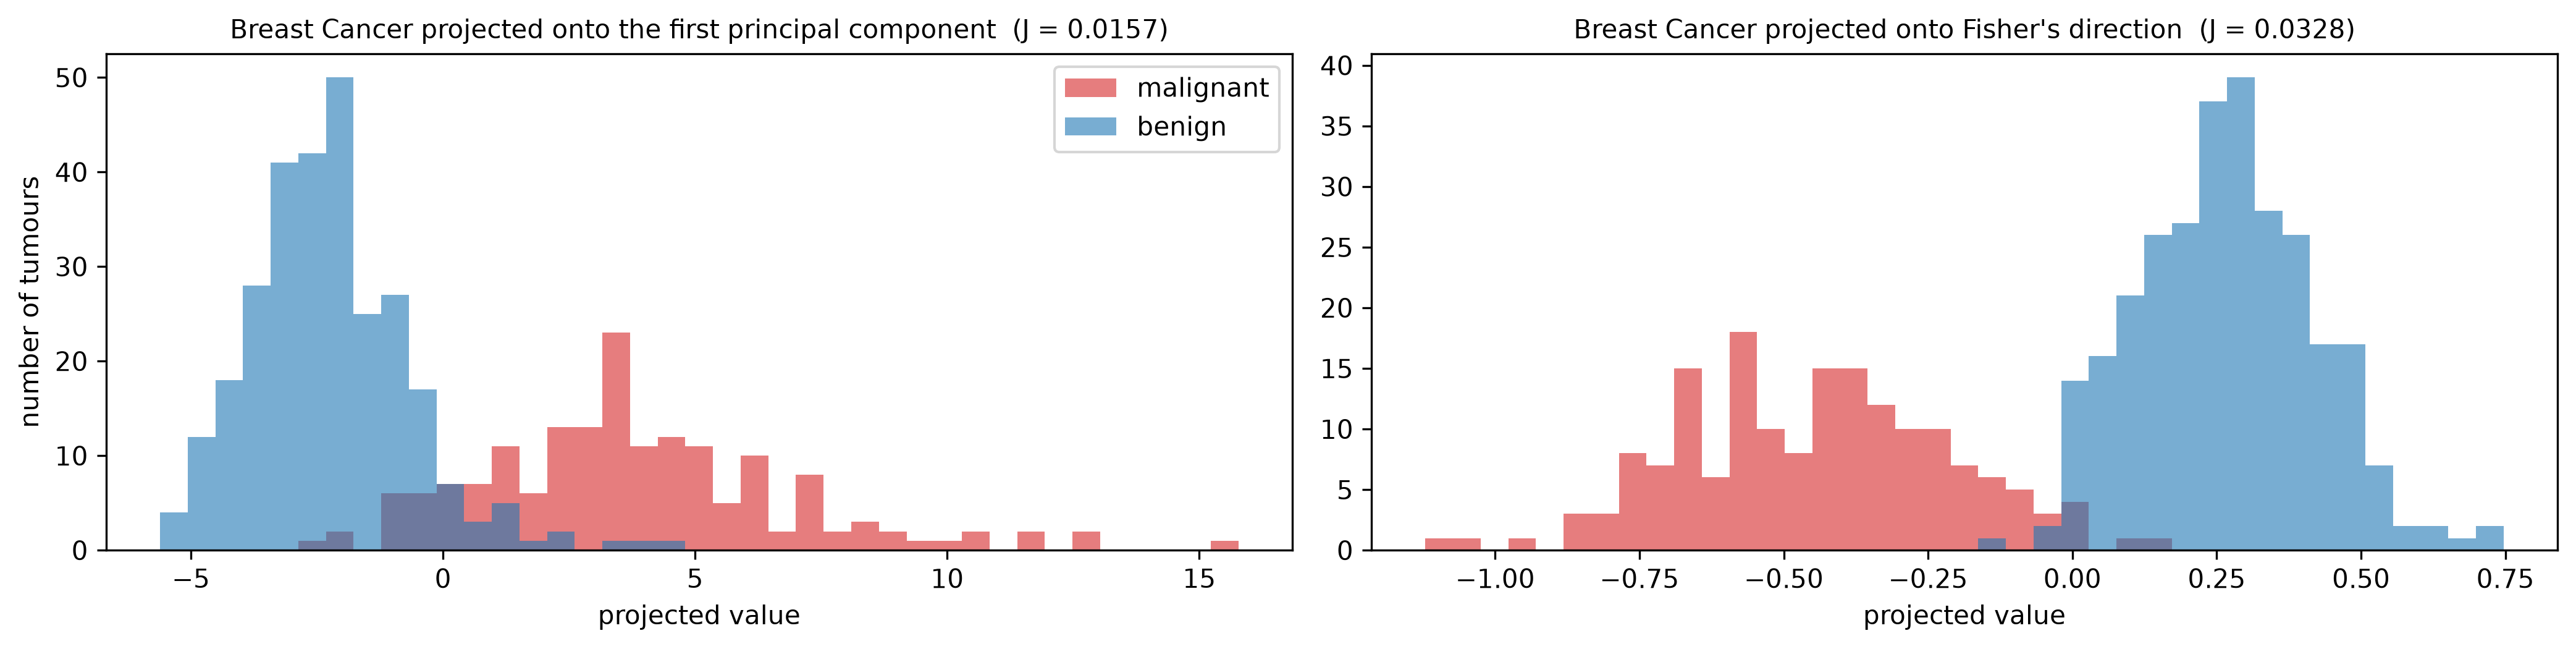

In [55]:
X0_bc = Zbc_dev[ybc_dev == 0]                        # malignant development tumours (standardised)
X1_bc = Zbc_dev[ybc_dev == 1]                        # benign development tumours
w_bc = fisher_direction(X0_bc, X1_bc)                # Fisher's direction in the 30-dimensional space
pc1_bc = pca_svd(Zbc_dev)[1][:, 0]                   # the first principal direction (no labels)
mean_diff_bc = (X1_bc.mean(axis=0) - X0_bc.mean(axis=0))  # the vector joining the class means
mean_diff_bc = mean_diff_bc / np.linalg.norm(mean_diff_bc)  # scaled to length 1

random_dirs = rng.normal(size=(20000, 30))           # 20 000 random directions ...
random_dirs /= np.linalg.norm(random_dirs, axis=1, keepdims=True)   # ... each scaled to length 1
J_random = np.array([fisher_J(u, X0_bc, X1_bc) for u in random_dirs])  # J of every random direction

print(f"Fisher's J, first principal direction : {fisher_J(pc1_bc, X0_bc, X1_bc):.5f}")
print(f"Fisher's J, difference of the means   : {fisher_J(mean_diff_bc, X0_bc, X1_bc):.5f}")
print(f"Fisher's J, Fisher's direction        : {fisher_J(w_bc, X0_bc, X1_bc):.5f}")
print(f"largest J among 20 000 random directions: {J_random.max():.5f}")

# the library check: the direction of LinearDiscriminantAnalysis
lib_lda_bc = LinearDiscriminantAnalysis(solver="eigen").fit(Zbc_dev, ybc_dev)  # the library LDA
w_lib = lib_lda_bc.scalings_[:, 0]                   # its first (and only useful) direction
cosine = w_bc @ w_lib / (np.linalg.norm(w_bc) * np.linalg.norm(w_lib))  # cosine of the angle
print(f"\ncosine of the angle between our direction and the library's: {cosine:.10f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))    # two panels
for ax, w, title in [(axes[0], pc1_bc, "the first principal component"), (axes[1], w_bc, "Fisher's direction")]:
    a, b = X0_bc @ w, X1_bc @ w                      # the two classes projected
    bins = np.linspace(min(a.min(), b.min()), max(a.max(), b.max()), 40)  # shared bins
    ax.hist(a, bins=bins, color="tab:red", alpha=0.6, label="malignant")  # malignant tumours
    ax.hist(b, bins=bins, color="tab:blue", alpha=0.6, label="benign")  # benign tumours
    ax.set_title(f"Breast Cancer projected onto {title}  (J = {fisher_J(w, X0_bc, X1_bc):.4f})", fontsize=10)
    ax.set_xlabel("projected value")                 # x-axis label
axes[0].set_ylabel("number of tumours")              # y-axis label
axes[0].legend()                                     # legend
plt.tight_layout()                                   # keep labels from overlapping
plt.show()                                           # draw the figure

**Line by line**

- `Zbc_dev[ybc_dev == 0]` : the standardised development rows of class 0 (malignant); likewise class 1 (benign).
- `fisher_direction(X0_bc, X1_bc)` : the function of 6a, unchanged, now in 30 dimensions.
- `pca_svd(Zbc_dev)[1][:, 0]` : the first principal direction (`[1]` picks the directions from the returned triple).
- `rng.normal(size=(20000, 30))` : 20 000 random vectors in 30 dimensions. Dividing each by its length
  (`keepdims=True` keeps the lengths as a column so the division broadcasts row by row) makes them random
  **directions**.
- `LinearDiscriminantAnalysis(solver="eigen")` : the library's LDA. Its directions are stored in the columns of
  `scalings_`; with two classes only the first is useful (Part 7 explains why).
- `cosine` : the cosine of the angle between our direction and the library's. Two vectors on the same line have a
  cosine of $+1$ (same way) or $-1$ (opposite ways).
- The histograms are drawn as in 6b, for the first principal component and for Fisher's direction.

**Reading the output and the plots.**

- Fisher's criterion: **0.0157** on the first principal direction, 0.0184 on the mean difference, and **0.0328** on
  Fisher's direction, more than twice as much. The best of 20 000 random directions reaches only 0.0213: no random
  search comes close to the formula.
- The cosine with the library's direction is **$-1.0000000000$**: the same line, pointing the other way. The sign of a
  discriminant direction is arbitrary, just like the sign of an eigenvector, so our function is exactly scikit-learn's.
- In the histograms, the first principal component already separates the classes fairly well (the big variation in
  these data is tumour size, and malignant tumours tend to be larger), but there is a clear overlap. On Fisher's
  direction the overlap shrinks to a handful of tumours. Part 8 measures what this does to a classifier.

# Part 7: LDA for more than two classes

## 7a. Between-class and within-class scatter

With $C$ classes there is no longer a single "difference of the means". Instead we measure how spread out the
**class means** are around the overall mean $\mu$, each weighted by the size $n_c$ of its class:

$$S_B = \sum_{c=1}^{C} n_c\, (\mu_c - \mu)(\mu_c - \mu)^{\top}, \qquad
S_W = \sum_{c=1}^{C} \sum_{i \in c} (x_i - \mu_c)(x_i - \mu_c)^{\top}.$$

$S_W$ is the same within-class scatter matrix as in Part 6. The two add up to the **total scatter**,

$$S_T = \sum_{i=1}^{n} (x_i - \mu)(x_i - \mu)^{\top} = S_W + S_B,$$

which says: *the total spread of the data = the spread inside the classes + the spread between the classes.* This is
the same decomposition as in the analysis of variance.

Fisher's criterion keeps the same form, $J(w) = \dfrac{w^{\top}S_B\,w}{w^{\top}S_W\,w}$: between-class spread along $w$
divided by within-class spread along $w$.

One more fact matters. $S_B$ is built from $C$ points (the class means), and $C$ points around their weighted average
span at most $C - 1$ dimensions: two points lie on a line, three points lie in a plane. So **$S_B$ has rank at most
$C - 1$**, and LDA can find at most **$C - 1$ useful directions**: one for two classes, two for the three cultivars.

In [56]:
def scatter_matrices(X, y):
    '''Within-class, between-class and total scatter matrices of the rows of X with labels y.'''
    mu = X.mean(axis=0)                              # the overall mean
    p = X.shape[1]                                   # number of columns
    S_W = np.zeros((p, p))                           # start both sums at zero
    S_B = np.zeros((p, p))                           # p x p zeros
    for c in np.unique(y):                           # one class at a time
        Xc = X[y == c]                               # the rows of class c
        mu_c = Xc.mean(axis=0)                       # its mean
        S_W += (Xc - mu_c).T @ (Xc - mu_c)           # spread of class c around its own mean
        S_B += len(Xc) * np.outer(mu_c - mu, mu_c - mu)   # n_c times the spread of its mean around mu
    S_T = (X - mu).T @ (X - mu)                      # total spread around the overall mean
    return S_W, S_B, S_T


S_W, S_B, S_T = scatter_matrices(Zw_dev, yw_dev)     # the three scatter matrices of the wines
n_classes = len(np.unique(yw_dev))                   # C = 3 cultivars
print("S_W + S_B equals S_T               :", np.allclose(S_W + S_B, S_T))
print("rank of S_W (of 13)                :", np.linalg.matrix_rank(S_W))
print("rank of S_B (at most C - 1 = 2)    :", np.linalg.matrix_rank(S_B))
print("eigenvalues of S_B                 :", np.linalg.eigvalsh(S_B)[::-1].round(4))

S_W + S_B equals S_T               : True
rank of S_W (of 13)                : 13
rank of S_B (at most C - 1 = 2)    : 2
eigenvalues of S_B                 : [547.8546 276.5301   0.       0.       0.       0.       0.       0.
  -0.      -0.      -0.      -0.      -0.    ]


**Line by line**

- `scatter_matrices(X, y)` :
  - `np.zeros((p, p))` : start both sums at a $p \times p$ matrix of zeros.
  - `for c in np.unique(y)` : one pass per class; `X[y == c]` selects its rows.
  - `S_W += (Xc - mu_c).T @ (Xc - mu_c)` : adds class $c$'s scatter around its own mean.
  - `np.outer(a, b)` : the outer product $ab^{\top}$, a $p \times p$ matrix. `len(Xc) * np.outer(mu_c - mu, mu_c - mu)`
    is $n_c(\mu_c - \mu)(\mu_c - \mu)^{\top}$.
  - `S_T` : the scatter of all rows around the overall mean.
- `np.linalg.matrix_rank` : the number of independent rows (or columns) of a matrix.
- `np.linalg.eigvalsh(S_B)[::-1]` : the eigenvalues of $S_B$, largest first.

**Reading the output.**

- $S_W + S_B = S_T$: the decomposition holds exactly.
- $S_W$ has full rank, 13. That matters: LDA has to "divide by" $S_W$ (Part 6 solved $S_W w = \mu_1 - \mu_0$), which is
  only possible when $S_W$ is invertible. (Exercise 4 shows what happens when it is not.)
- $S_B$ has rank **2**: two non-zero eigenvalues (547.9 and 276.5) and eleven zeros. With three cultivars there are
  only two directions in which the class means differ.

## 7b. Solving LDA by whitening

Maximising $J(w)$ leads to the **generalised eigenvalue problem**

$$S_B\, w = \lambda\, S_W\, w ,$$

and at a solution the value of the criterion is $J(w) = \lambda$. It is called "generalised" because of the $S_W$ on
the right; with $S_W = I$ it would be the ordinary eigenvalue problem of PCA. There is a neat way to turn it into an
ordinary one, called **whitening**:

1. **Make the classes round.** $S_W$ describes the shape of the classes. Its eigen-decomposition
   $S_W = Q D Q^{\top}$ gives $S_W^{-1/2} = Q D^{-1/2} Q^{\top}$, a matrix that stretches and squeezes the space until
   the within-class scatter becomes the identity: every class becomes round, with the same spread in every direction.
2. **Do PCA of the class means.** In this whitened space the within-class spread is the same in every direction, so
   the best direction is simply the one along which the **class means** are most spread out. That is an ordinary,
   symmetric eigenvalue problem for the whitened between-class scatter $M = S_W^{-1/2} S_B S_W^{-1/2}$.
3. **Map back.** An eigenvector $v$ of $M$ corresponds to the direction $w = S_W^{-1/2} v$ in the original space.

(To see that this solves the problem, write $w = S_W^{-1/2}v$. Then $w^{\top}S_W w = v^{\top}v$ and
$w^{\top}S_B w = v^{\top}Mv$, so $J$ becomes $\frac{v^{\top}Mv}{v^{\top}v}$, which is maximised by the top eigenvectors
of $M$, exactly as in Part 2.)

So **LDA is PCA in disguise**: PCA of the class means, after the space has been reshaped so that every class is round.

Finally, the length of each direction is free, so we choose a useful one: we scale $w$ so that the projected data have
a **pooled within-class variance of 1** ($w^{\top}S_W w = n$). Distances in the LDA space are then measured in
"within-class standard deviations". This is also the scaling scikit-learn uses.

In [57]:
def lda_fit(X, y):
    '''Multi-class LDA by whitening the within-class scatter.

    returns : (mean, W, eigenvalues). The columns of W are the C - 1 discriminant directions, best first,
              scaled so that the projected data have pooled within-class variance 1.
    '''
    n = len(X)                                       # number of rows
    S_W, S_B, _ = scatter_matrices(X, y)             # within and between scatter
    d, Q = np.linalg.eigh(S_W)                       # S_W = Q diag(d) Q^T
    S_W_inv_half = Q @ np.diag(d ** -0.5) @ Q.T      # S_W^{-1/2}: undoes the within-class spread
    M = S_W_inv_half @ S_B @ S_W_inv_half            # the between-class scatter, in the whitened space
    eigenvalues, v = np.linalg.eigh(M)               # an ordinary symmetric eigenproblem
    order = np.argsort(eigenvalues)[::-1]            # largest first
    n_keep = len(np.unique(y)) - 1                   # only C - 1 eigenvalues can be non-zero
    W = np.sqrt(n) * S_W_inv_half @ v[:, order[:n_keep]]   # back to the original space, within variance 1
    return X.mean(axis=0), sign_convention(W), eigenvalues[order[:n_keep]]


mean_lda, W_lda, lam_lda = lda_fit(Zw_dev, yw_dev)   # LDA of the development wines
print("discriminant directions W:", W_lda.shape, "   eigenvalues:", lam_lda)

# check 1: the generalised eigenproblem S_B w = lambda S_W w, solved by SciPy
general = scipy.linalg.eigh(S_B, S_W, eigvals_only=True)[::-1]   # largest first
print("same eigenvalues as scipy.linalg.eigh(S_B, S_W):", np.allclose(lam_lda, general[:2]))
print("the other 11 eigenvalues are zero             :", np.allclose(general[2:], 0))

# check 2: scikit-learn's LDA with the "eigen" solver
lib_lda = LinearDiscriminantAnalysis(solver="eigen").fit(Zw_dev, yw_dev)  # the library LDA
print("same directions as LDA scalings_               :", np.allclose(W_lda, sign_convention(lib_lda.scalings_[:, :2])))
print("same explained_variance_ratio_                 :",
      np.allclose(lam_lda / lam_lda.sum(), lib_lda.explained_variance_ratio_))

# what the scaling means
T_lda = (Zw_dev - mean_lda) @ W_lda                  # the development wines in LDA coordinates
S_W_T, S_B_T, _ = scatter_matrices(T_lda, yw_dev)    # scatter matrices of the 2-D projected data
print("\nwithin-class covariance of the projections (S_W / n):\n", S_W_T / len(T_lda))
print("between-class covariance of the projections (S_B / n):\n", S_B_T / len(T_lda))

discriminant directions W: (13, 2)    eigenvalues: [9.8567 3.8555]
same eigenvalues as scipy.linalg.eigh(S_B, S_W): True
the other 11 eigenvalues are zero             : True
same directions as LDA scalings_               : True
same explained_variance_ratio_                 : True

within-class covariance of the projections (S_W / n):
 [[1. 0.]
 [0. 1.]]
between-class covariance of the projections (S_B / n):
 [[ 9.8567 -0.    ]
 [-0.      3.8555]]


**Line by line**

- `np.linalg.eigh(S_W)` : $S_W = Q\,\text{diag}(d)\,Q^{\top}$. All the $d$ are positive because $S_W$ has full rank.
- `Q @ np.diag(d ** -0.5) @ Q.T` : $S_W^{-1/2}$. `d ** -0.5` is $1/\sqrt{d}$ for every eigenvalue.
- `M = S_W_inv_half @ S_B @ S_W_inv_half` : the between-class scatter in the whitened space. It is symmetric, so
  `eigh` can be used again.
- `order[:n_keep]` with `n_keep = C - 1` : only the first $C - 1$ eigenvalues can be non-zero (7a), so we keep only
  those directions.
- `np.sqrt(n) * S_W_inv_half @ v[...]` : maps back to the original space and scales so that $w^{\top}S_W w = n$.
- `sign_convention(W)` : the same sign rule as for PCA, so we can compare with the library.
- `scipy.linalg.eigh(S_B, S_W, eigvals_only=True)` : SciPy solves the generalised problem $S_B w = \lambda S_W w$
  directly. `[::-1]` puts the eigenvalues largest first.
- `LinearDiscriminantAnalysis(solver="eigen")` : scikit-learn's LDA with the eigenvalue solver. `scalings_` holds its
  directions as columns and `explained_variance_ratio_` the eigenvalues divided by their sum.
- The last block projects the development wines onto the two directions and computes the within-class and
  between-class scatter of these two new columns, divided by $n$ to turn scatter into variance.

**Reading the output.**

- LDA finds **two** directions, with eigenvalues **9.86** and **3.86**. SciPy finds the same two, and the other eleven
  generalised eigenvalues are zero, as 7a predicted.
- Our directions are identical to scikit-learn's `scalings_`, and the explained ratios are the same: the first
  direction carries 71.9% of the separation, the second 28.1%.
- The last two matrices show what LDA has built. In the new coordinates the **within-class covariance is the identity**:
  every cultivar is round, with spread 1 in both directions, and the two coordinates are uncorrelated inside the
  classes. The **between-class covariance is diagonal with the eigenvalues on its diagonal**: along LD1 the class means
  spread with variance 9.86, along LD2 with 3.86. So each eigenvalue is exactly the between-class to within-class
  variance ratio along its direction, Fisher's $J$ in its multi-class form.

## 7c. The two-class case again

The multi-class function should contain Part 6 as a special case. With two classes it must return a single direction,
the same line as $S_W^{-1}(\mu_1 - \mu_0)$.

In [58]:
_, W_two, lam_two = lda_fit(Zbc_dev, ybc_dev)        # our multi-class function, on the two-class data
w_two = W_two[:, 0] / np.linalg.norm(W_two[:, 0])    # its single direction, scaled to length 1
print("number of directions for 2 classes      :", W_two.shape[1])
print(f"cosine with Fisher's direction of Part 6: {abs(w_two @ w_bc):.10f}")
factor = len(X0_bc) * len(X1_bc) / len(Zbc_dev)     # n0 n1 / n: links the two definitions of S_B
print(f"eigenvalue {lam_two[0]:.4f} = (n0 n1 / n) x Fisher's J = {factor * fisher_J(w_bc, X0_bc, X1_bc):.4f}")

number of directions for 2 classes      : 1
cosine with Fisher's direction of Part 6: 1.0000000000
eigenvalue 3.4979 = (n0 n1 / n) x Fisher's J = 3.4979


**Line by line**

- `lda_fit(Zbc_dev, ybc_dev)` : the multi-class function on the two-class Breast Cancer data.
- `W_two[:, 0] / np.linalg.norm(W_two[:, 0])` : its direction scaled to length 1, so it can be compared with `w_bc`
  from 6c.
- `factor = n0 n1 / n` : with two classes the multi-class $S_B$ equals $\frac{n_0 n_1}{n}(\mu_1 - \mu_0)(\mu_1 -
  \mu_0)^{\top}$, so its criterion is the two-class $J$ of Part 6 multiplied by this factor.

**Reading the output.** With $C = 2$ the function returns exactly **one** direction, and its cosine with Fisher's
direction of Part 6 is **1.0000000000**: the same line. Its eigenvalue, 3.4979, is Fisher's $J$ of 6c (0.0328)
multiplied by $n_0 n_1 / n = 170 \times 285 / 455 \approx 106.5$: the two definitions of $S_B$ differ only by that
constant, which does not change the best direction. The multi-class LDA is a true extension of Fisher's two-class
method.

# Part 8: PCA and LDA compared on the same data

## 8a. The two projections side by side

Both methods turn each wine into two numbers. PCA chooses the two numbers that keep the most **variance**; LDA chooses
the two that keep the cultivars most **separate**. Here are both pictures of the same development wines. The test
wines are added as open diamonds, projected with the **development** fit, to show where new wines land.

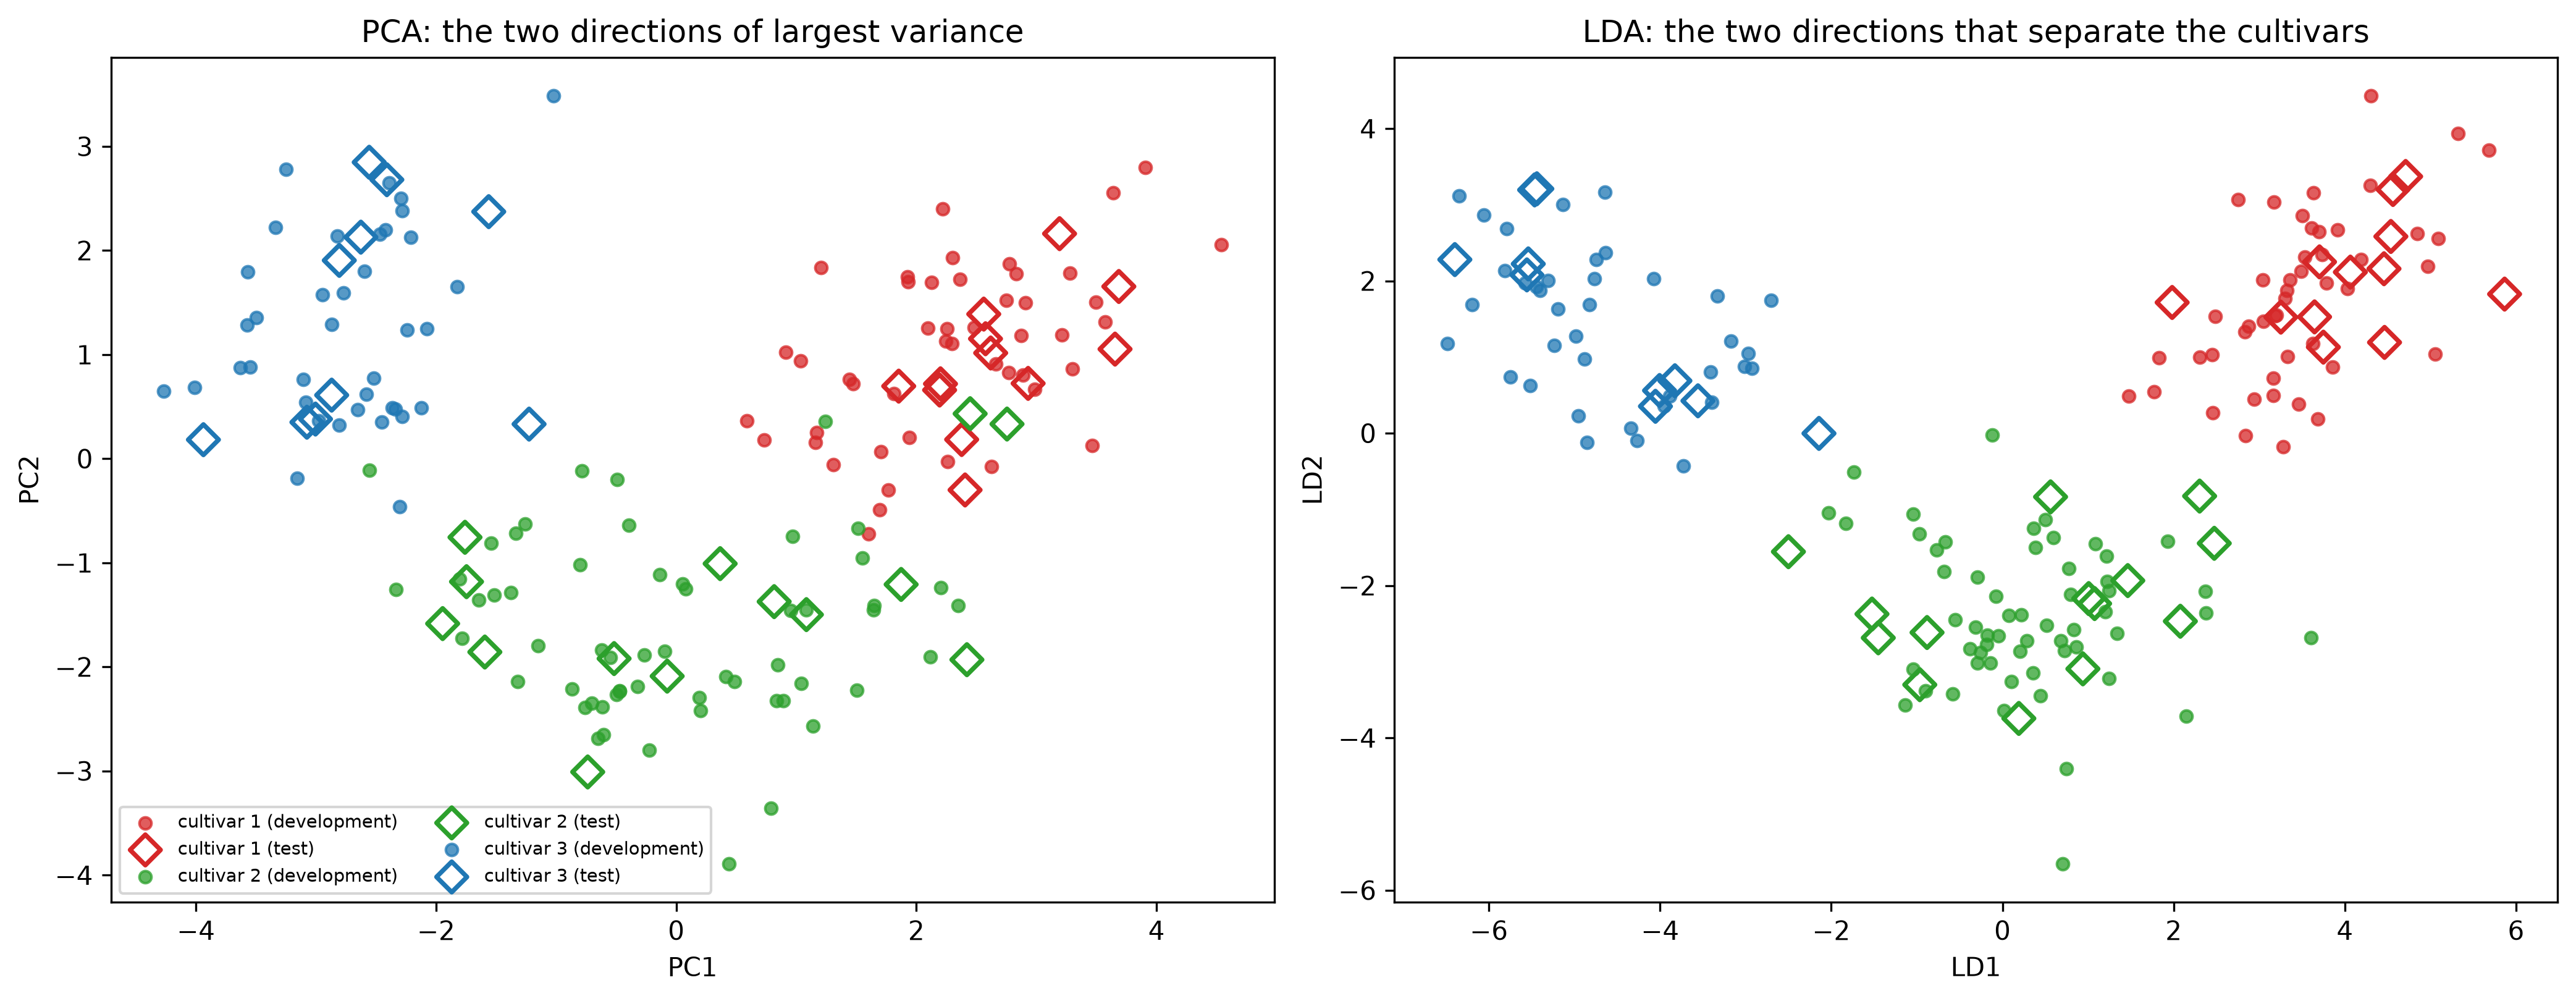

between / within scatter on the 2 PCA axes: 3.542
between / within scatter on the 2 LDA axes: 6.856


In [59]:
T_pca_dev = pca_project(Zw_dev, mean_w, V_eig, 2)    # development wines on PC1, PC2
T_pca_test = pca_project(Zw_test, mean_w, V_eig, 2) # test wines, with the development fit
T_lda_dev = (Zw_dev - mean_lda) @ W_lda              # development wines on LD1, LD2
T_lda_test = (Zw_test - mean_lda) @ W_lda            # test wines, with the development fit

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))    # two panels side by side
for ax, T_dev, T_test, title, labels in [
        (axes[0], T_pca_dev, T_pca_test, "PCA: the two directions of largest variance", ("PC1", "PC2")),
        (axes[1], T_lda_dev, T_lda_test, "LDA: the two directions that separate the cultivars", ("LD1", "LD2"))]:
    for c, colour in enumerate(colours_wine):        # one colour per cultivar
        ax.scatter(T_dev[yw_dev == c, 0], T_dev[yw_dev == c, 1], s=22, color=colour, alpha=0.75,
                   label=f"{class_names_wine[c]} (development)")
        ax.scatter(T_test[yw_test == c, 0], T_test[yw_test == c, 1], s=70, facecolor="none",
                   edgecolor=colour, linewidth=1.8, marker="D", label=f"{class_names_wine[c]} (test)")
    ax.set_xlabel(labels[0])                         # x-axis label
    ax.set_ylabel(labels[1])                         # y-axis label
    ax.set_title(title)                              # panel title
axes[0].legend(fontsize=7, ncol=2, loc="lower left")  # legend in two columns
plt.tight_layout()                                   # keep labels from overlapping
plt.show()                                           # draw the figure

def separation(T, y):
    '''Between-class scatter divided by within-class scatter, summed over the columns of T.'''
    S_W_T, S_B_T, _ = scatter_matrices(T, y)         # scatter of the projected points
    return np.trace(S_B_T) / np.trace(S_W_T)

print(f"between / within scatter on the 2 PCA axes: {separation(T_pca_dev, yw_dev):.3f}")
print(f"between / within scatter on the 2 LDA axes: {separation(T_lda_dev, yw_dev):.3f}")

**Line by line**

- `pca_project(Zw_test, mean_w, V_eig, 2)` : the test wines on the first two principal directions found from the
  development wines.
- `(Zw_test - mean_lda) @ W_lda` : the test wines on the two LDA directions found from the development wines.
- The outer `for` loop draws the two panels with the same code; the list of tuples gives each panel its own data,
  title and axis labels.
- `facecolor="none", edgecolor=colour, marker="D"` : open diamonds for the test wines, so they stand out.
- `separation(T, y)` : one number summarising a projection. `np.trace` adds up the diagonal of a scatter matrix, i.e.
  the scatter along every axis, so this is the total between-class scatter divided by the total within-class scatter
  of the projected points.

**Reading the plots.**

- **Left, PCA** (the plot of 4b): three groups, but cultivar 2 (green) touches both other groups, and a few green
  wines sit inside the red and blue clouds.
- **Right, LDA**: three **compact, clearly separated** groups. LD1 places cultivar 3 on the left and cultivar 1 on the
  right, with cultivar 2 in between; LD2 lifts cultivar 2 away from both. Each cultivar is roughly round, as 7b
  promised (within-class variance 1 in every direction).
- The **test diamonds** land inside their own groups in the LDA picture. That matters, because LDA was fitted to
  separate exactly the development wines, so the development picture is a little flattering. The test wines show that
  the separation is real.
- The separation number agrees with the eye: between-class scatter is **3.5 times** the within-class scatter on the
  PCA axes, and **6.9 times** on the LDA axes. LDA chose its axes to make exactly this ratio large.

## 8b. The same comparison for Breast Cancer

With two classes, LDA gives only $C - 1 = 1$ direction, so we compare it with the first principal component.

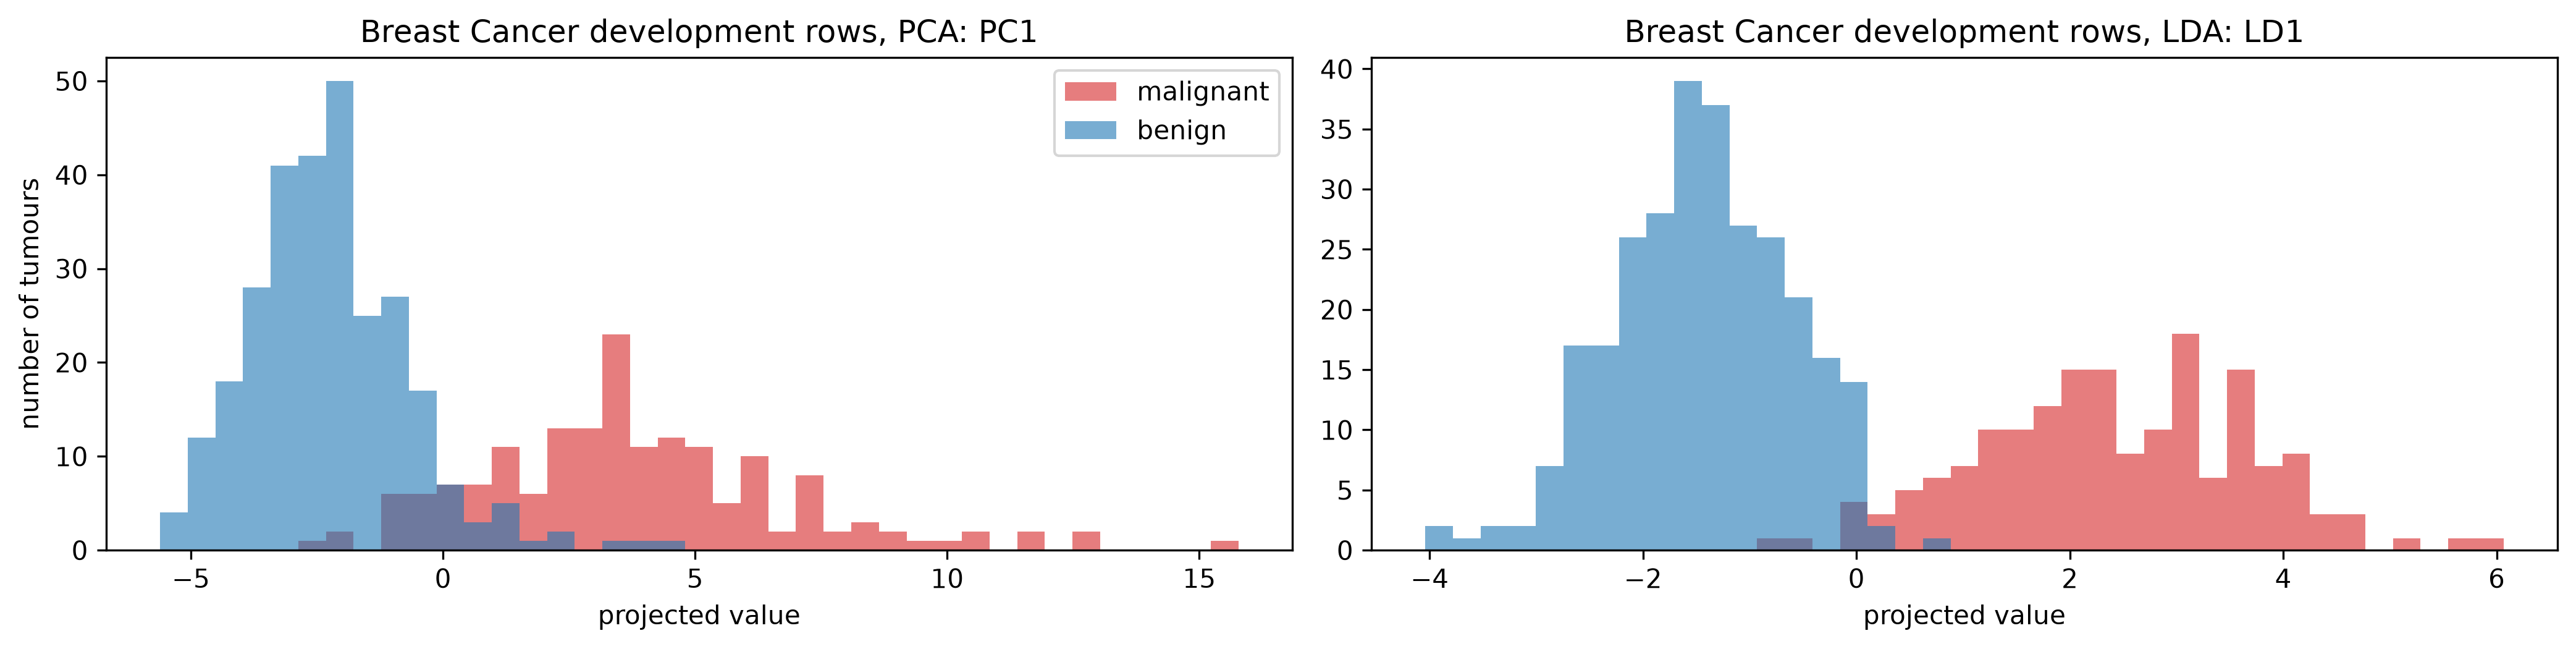

In [60]:
mean_pca_bc, V_pca_bc, lam_pca_bc = pca_svd(Zbc_dev)  # PCA of the Breast Cancer development rows
T_bc_pca = pca_project(Zbc_dev, mean_pca_bc, V_pca_bc, 1)[:, 0]   # their scores on PC1
mean_lda_bc, W_lda_bc, _ = lda_fit(Zbc_dev, ybc_dev)  # LDA of the development tumours
T_bc_lda = (Zbc_dev - mean_lda_bc) @ W_lda_bc[:, 0]  # the single LDA direction

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))    # two panels
for ax, t, title in [(axes[0], T_bc_pca, "PCA: PC1"), (axes[1], T_bc_lda, "LDA: LD1")]:  # two panels
    bins = np.linspace(t.min(), t.max(), 40)         # shared bins
    for c, colour in [(0, "tab:red"), (1, "tab:blue")]:  # one colour per class
        ax.hist(t[ybc_dev == c], bins=bins, color=colour, alpha=0.6, label=class_names_bc[c])
    ax.set_title(f"Breast Cancer development rows, {title}")  # title
    ax.set_xlabel("projected value")                 # x-axis label
axes[0].set_ylabel("number of tumours")              # y-axis label
axes[0].legend()                                     # legend
plt.tight_layout()                                   # keep labels from overlapping
plt.show()                                           # draw the figure

**Line by line**

- `pca_svd(Zbc_dev)` and `pca_project(..., 1)[:, 0]` : the development tumours' scores on PC1, as a plain vector.
- `lda_fit(Zbc_dev, ybc_dev)` and `@ W_lda_bc[:, 0]` : their positions on the single LDA direction, which is Fisher's
  direction of Part 6, scaled to within-class variance 1.

**Reading the plots.** This is 6c again, now with LDA's scaling. On PC1 the two classes overlap over a wide range; on
LD1 they form two separate humps that touch only in a narrow band around 0. Because LD1 has within-class variance 1,
its axis is in units of within-class standard deviations: the two class means are about 4 of them apart.

## 8c. Classification accuracy after each reduction

Pictures are convincing, but the aim asks for a number: **how accurately can a classifier recognise the class after
each reduction?** We use the 5-nearest-neighbour classifier of Practical 4 on the reduced data, and estimate its
accuracy by **stratified 5-fold cross-validation on the development rows**.

The protocol of Practical 4 applies in full. Standardisation, PCA and LDA all **learn from data**, so inside every
fold they are fitted on the training part only and then applied to the validation part. For LDA this is essential:
LDA uses the labels, and fitting it on all development rows would let the labels of the validation rows shape the
very axes on which those rows are then classified, a leak of exactly the kind in Practical 4, Exercise 4 (Exercise 5
below measures it).

We do this for every number of dimensions: $k = 1, \dots, p$ components for PCA, $k = 1, \dots, C - 1$ directions for
LDA, and, for reference, no reduction at all.

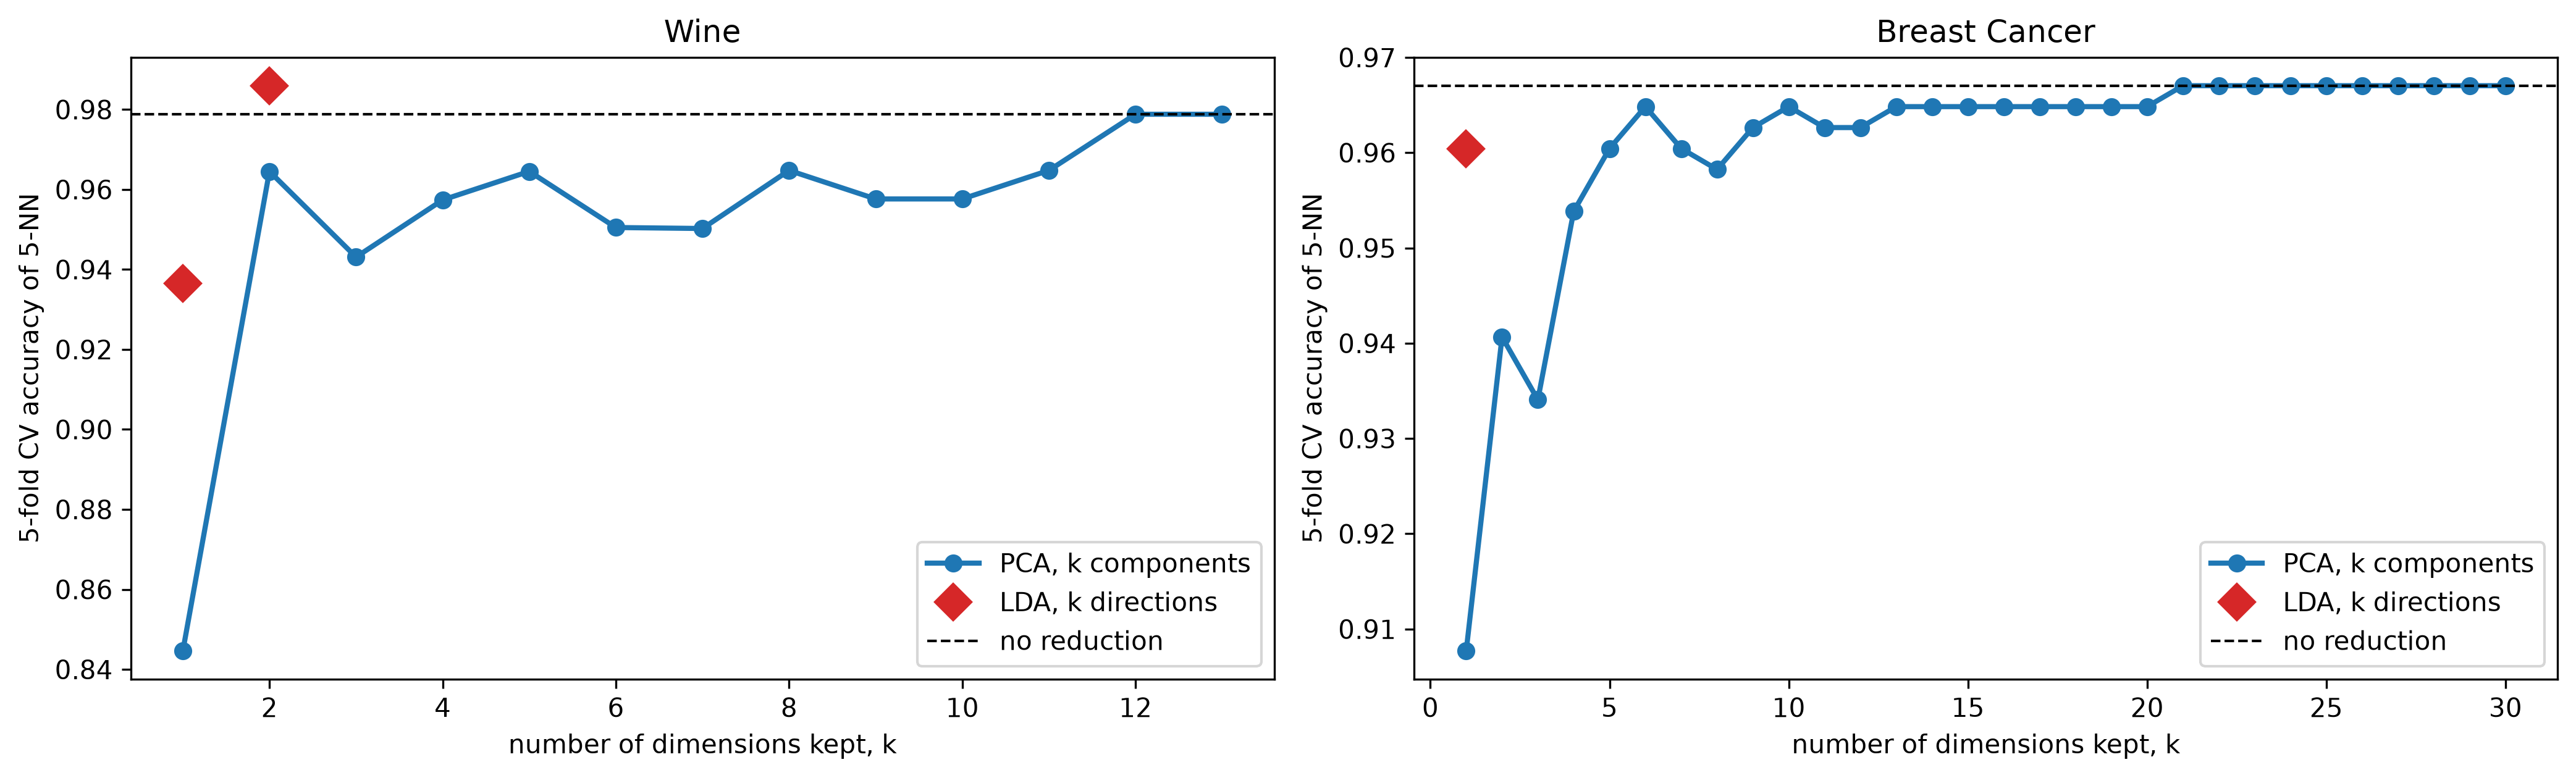

CV accuracy  std over folds
dataset       method k                             
Wine          PCA    1       0.8446          0.0738
                     2       0.9645          0.0319
                     3       0.9431          0.0581
              LDA    1       0.9365          0.0269
                     2       0.9860          0.0172
Breast Cancer PCA    1       0.9077          0.0330
                     2       0.9407          0.0237
                     3       0.9341          0.0155
              LDA    1       0.9604          0.0088

In [61]:
def reduce_fit(Z, y, method):
    '''Fit a reduction on the rows Z (labels y). returns (mean, directions) with the best direction first.'''
    if method == "PCA":                              # unsupervised: ignores y
        mean, V, _ = pca_svd(Z)                      # unsupervised: y is ignored
        return mean, V                               # all p directions
    if method == "LDA":                              # supervised: uses y
        mean, W, _ = lda_fit(Z, y)                   # supervised: uses the labels
        return mean, W                               # all C - 1 directions
    return np.zeros(Z.shape[1]), np.eye(Z.shape[1]) # "none": the identity keeps every column


def cv_accuracy(X_raw, y, folds, method, k, n_neighbours=5):
    '''Accuracy of k-NN after a reduction, by cross-validation. Everything is refitted inside every fold.'''
    accuracies = []                                  # one accuracy per fold
    for tr, va in folds:                             # training and validation rows of each fold
        Z_tr = standardise(X_raw[tr], X_raw[tr])     # 1. standardise with the training part only
        Z_va = standardise(X_raw[tr], X_raw[va])     # validation part, training statistics
        mean, W = reduce_fit(Z_tr, y[tr], method)    # 2. fit PCA or LDA on the training part only
        T_tr = (Z_tr - mean) @ W[:, :k]              # 3. project both parts with that fit
        T_va = (Z_va - mean) @ W[:, :k]              # validation part projected
        knn = KNeighborsClassifier(n_neighbors=n_neighbours).fit(T_tr, y[tr])   # 4. classify
        accuracies.append(np.mean(knn.predict(T_va) == y[va]))  # 5. score the fold
    return np.array(accuracies)


datasets = {"Wine": (Xw_dev, yw_dev), "Breast Cancer": (Xbc_dev, ybc_dev)}  # the development sets
cv_rows = []                                         # one dictionary per setting
for name, (X_raw, y) in datasets.items():            # each dataset in turn
    folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=0).split(X_raw, y))  # one set of folds
    n_features, n_cls = X_raw.shape[1], len(np.unique(y))  # p and C
    for method, k_range in [("PCA", range(1, n_features + 1)), ("LDA", range(1, n_cls)), ("none", [n_features])]:
        for k in k_range:                            # each number of dimensions
            acc = cv_accuracy(X_raw, y, folds, method, k)  # five fold accuracies
            cv_rows.append({"dataset": name, "method": method, "k": k, "CV accuracy": acc.mean(),  # record
                            "std over folds": acc.std()})
cv_table = pd.DataFrame(cv_rows)                     # every setting in one table

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))    # two panels side by side
for ax, name in zip(axes, datasets):                 # one panel per dataset
    part = cv_table[cv_table["dataset"] == name]     # the CV results of this dataset
    pca_part = part[part["method"] == "PCA"]         # its PCA rows
    lda_part = part[part["method"] == "LDA"]         # its LDA rows
    ax.plot(pca_part["k"], pca_part["CV accuracy"], "o-", color="tab:blue", lw=2, label="PCA, k components")  # PCA
    ax.plot(lda_part["k"], lda_part["CV accuracy"], "D", color="tab:red", markersize=10, label="LDA, k directions")
    ax.axhline(part[part["method"] == "none"]["CV accuracy"].iloc[0], color="black", ls="dashed", lw=1,
               label="no reduction")
    ax.set_xlabel("number of dimensions kept, k")    # x-axis label
    ax.set_ylabel("5-fold CV accuracy of 5-NN")      # y-axis label
    ax.set_title(name)                               # panel title
    ax.legend(loc="lower right")                     # legend
plt.tight_layout()                                   # keep labels from overlapping
plt.show()                                           # draw the figure

cv_table[cv_table["k"] <= 3].set_index(["dataset", "method", "k"])  # the rows with k up to 3

**Line by line**

- `reduce_fit(Z, y, method)` : one function for the three choices, returning a mean and a matrix of directions with the
  best first.
  - `"PCA"` uses `pca_svd` and ignores `y`.
  - `"LDA"` uses `lda_fit` and the labels.
  - `"none"` returns a zero mean and the identity matrix `np.eye(p)`, so "projecting" keeps every standardised column
    unchanged. This lets one loop handle all three cases.
- `cv_accuracy(X_raw, y, folds, method, k)` : the cross-validation loop of Practical 4, with the four steps of every
  fold written out: standardise with the training part, fit the reduction on the training part, project both parts
  onto the first `k` directions, then fit 5-NN on the projected training part and score it on the projected
  validation part.
- `StratifiedKFold(n_splits=5, shuffle=True, random_state=0)` : one fixed set of stratified folds per dataset, shared by
  every method and every $k$, so differences come from the methods and not from the folds (Practical 4, Part 5).
- `range(1, n_cls)` : $k = 1, \dots, C - 1$ for LDA, i.e. 1 and 2 for Wine and just 1 for Breast Cancer.
- The figure draws the PCA accuracy for every $k$ as a line, LDA's as large red diamonds, and no reduction as a dashed
  line. The table shows the rows with $k \le 3$.

**Reading the plots and the table.**

- **Wine.** With **one** dimension, LDA reaches **93.7%** and PCA only **84.5%**. With **two**, LDA reaches **98.6%**,
  the best accuracy of all, higher even than 5-NN on all 13 standardised columns (97.9%); PCA with two components
  reaches 96.5%. PCA needs **12** components to match the full data, and its curve wobbles on the way (94.3% with three
  components, 95.0% with six or seven), because the extra components add variance that is not about the cultivars.
- **Breast Cancer.** With one dimension, LDA reaches **96.0%** and PCA **90.8%**. PCA needs about 5 or 6 components to
  catch up with LDA's single direction, and 21 to reach the 96.7% of the full data.
- How big are these differences? The "std over folds" column is about 0.01 to 0.07, and with about 28 wines per
  validation fold one mistake changes a fold's accuracy by 3.5%. Differences of a percent or two are within the noise;
  the gaps at $k = 1$ (more than 5 points on both datasets) are not.

The pattern is clear: **when only a few dimensions may be kept, LDA keeps far more of what matters for classification
than PCA.** With many dimensions, PCA eventually keeps enough of everything, including what LDA found.

## 8d. Checking the loop against scikit-learn

The library builds the same procedure from a pipeline: `make_pipeline(StandardScaler(), PCA(k), KNeighborsClassifier(5))`
standardises, reduces and classifies, and `cross_val_score` refits the whole pipeline inside every fold. Given the same
folds, it must produce exactly the same fold accuracies as our loop.

In [62]:
all_same = []                                        # one True or False per setting
for name, (X_raw, y) in datasets.items():            # each dataset in turn
    folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=0).split(X_raw, y))  # one set of folds
    for method, k in [("PCA", 1), ("PCA", 2), ("PCA", 5), ("LDA", 1)] + ([("LDA", 2)] if name == "Wine" else []):
        reducer = PCA(n_components=k) if method == "PCA" else LinearDiscriminantAnalysis(n_components=k, solver="eigen")
        lib = cross_val_score(make_pipeline(StandardScaler(), reducer, KNeighborsClassifier(n_neighbors=5)),
                              X_raw, y, cv=folds)    # the library pipeline, on the same folds
        ours = cv_accuracy(X_raw, y, folds, method, k)  # our loop, same folds
        same = np.allclose(ours, lib)                # identical fold by fold?
        all_same.append(same)                        # remember the answer
        print(f"{name:<14} {method} k = {k}:  ours {ours.mean():.4f}   library {lib.mean():.4f}   identical: {same}")
print("\nevery fold identical in every case:", all(all_same))

Wine           PCA k = 1:  ours 0.8446   library 0.8446   identical: True
Wine           PCA k = 2:  ours 0.9645   library 0.9645   identical: True
Wine           PCA k = 5:  ours 0.9645   library 0.9645   identical: True
Wine           LDA k = 1:  ours 0.9365   library 0.9365   identical: True
Wine           LDA k = 2:  ours 0.9860   library 0.9860   identical: True
Breast Cancer  PCA k = 1:  ours 0.9077   library 0.9077   identical: True
Breast Cancer  PCA k = 2:  ours 0.9407   library 0.9407   identical: True
Breast Cancer  PCA k = 5:  ours 0.9604   library 0.9604   identical: True
Breast Cancer  LDA k = 1:  ours 0.9604   library 0.9604   identical: True

every fold identical in every case: True


**Line by line**

- The loop runs a few settings for each dataset: PCA with 1, 2 and 5 components, and LDA with every possible number of
  directions.
- `PCA(n_components=k)` or `LinearDiscriminantAnalysis(n_components=k, solver="eigen")` : the library reducer.
- `make_pipeline(StandardScaler(), reducer, KNeighborsClassifier(n_neighbors=5))` : standardise, reduce, classify, as
  one model.
- `cross_val_score(..., cv=folds)` : the library's cross-validation loop, given **our** folds. It returns the accuracy
  of every fold.
- `np.allclose(ours, lib)` : `True` only if all five fold accuracies are identical.

**Reading the output.** Every one of the nine settings prints `True`, fold for fold. That also confirms two details that
could have caused small differences: the sign of a direction does not change any distance, so k-NN does not care about
our sign convention; and scikit-learn's LDA does not subtract the mean before projecting, which shifts every point by
the same amount and again leaves every distance unchanged.

## 8e. The final models and the test set

Now the last two steps of the protocol of Practical 4: for each method, choose the number of dimensions with the
**highest CV accuracy** (if several are tied, the smallest), retrain on **all** development rows, and evaluate **once**
on the locked test set.

In [63]:
final_rows = []                                      # one dictionary per final model
for name, (X_raw, y), (X_test_raw, y_test_set) in [("Wine", (Xw_dev, yw_dev), (Xw_test, yw_test)),
                                                   ("Breast Cancer", (Xbc_dev, ybc_dev), (Xbc_test, ybc_test))]:
    part = cv_table[cv_table["dataset"] == name]     # the CV results of this dataset
    for method in ["none", "PCA", "LDA"]:            # the three ways to prepare the data
        rows_m = part[part["method"] == method]      # the rows of this method
        best = rows_m.loc[rows_m["CV accuracy"].round(10).idxmax()]   # highest CV accuracy (first = smallest k)
        k = int(best["k"])                           # the chosen number of dimensions
        Z_dev_all = standardise(X_raw, X_raw)        # step 5 of the protocol: refit on ALL development rows
        Z_test_all = standardise(X_raw, X_test_raw)  # test rows, development statistics
        mean, W = reduce_fit(Z_dev_all, y, method)   # the reduction, on all development rows
        knn = KNeighborsClassifier(n_neighbors=5).fit((Z_dev_all - mean) @ W[:, :k], y)  # 5-NN on all of them
        test_pred = knn.predict((Z_test_all - mean) @ W[:, :k])   # step 6: the test set, used once
        final_rows.append({"dataset": name, "reduction": method, "dimensions kept": k,  # one row per model
                           "CV accuracy (development)": best["CV accuracy"],
                           "test accuracy": np.mean(test_pred == y_test_set),
                           "test mistakes": f"{int(np.sum(test_pred != y_test_set))} of {len(y_test_set)}"})
final_table = pd.DataFrame(final_rows).set_index(["dataset", "reduction"])  # grouped by dataset
final_table                                          # display the table

dimensions kept  CV accuracy (development)  test accuracy test mistakes
dataset       reduction                                                                         
Wine          none                    13                     0.9788         0.9444       2 of 36
              PCA                     12                     0.9788         0.9444       2 of 36
              LDA                      2                     0.9860         0.9444       2 of 36
Breast Cancer none                    30                     0.9670         0.9649      4 of 114
              PCA                     21                     0.9670         0.9649      4 of 114
              LDA                      1                     0.9604         0.9561      5 of 114

**Line by line**

- `rows_m["CV accuracy"].round(10).idxmax()` : the row with the highest CV accuracy. Rounding removes floating-point
  dust, and `idxmax` returns the **first** of tied rows, which is the smallest $k$ because the table lists $k$ in
  increasing order.
- `standardise(X_raw, X_raw)` and `standardise(X_raw, X_test_raw)` : step 5 of the protocol, refitting on all
  development rows: the standardisation, then the reduction, then 5-NN.
- `knn.predict((Z_test_all - mean) @ W[:, :k])` : the test rows, standardised and projected with the development fit:
  the one and only evaluation of each final model.

**Reading the output.**

| dataset | reduction | dimensions | CV accuracy | test accuracy |
|-|-|-|-|-|
| Wine | none | 13 | 97.9% | 94.4% (2 mistakes of 36) |
| Wine | PCA | 12 | 97.9% | 94.4% (2 of 36) |
| Wine | LDA | **2** | **98.6%** | 94.4% (2 of 36) |
| Breast Cancer | none | 30 | 96.7% | 96.5% (4 of 114) |
| Breast Cancer | PCA | 21 | 96.7% | 96.5% (4 of 114) |
| Breast Cancer | LDA | **1** | 96.0% | 95.6% (5 of 114) |

- On the test sets the three choices are **practically equal**: the same 2 mistakes out of 36 wines, and 4 or 5
  mistakes out of 114 tumours. With 36 test wines the standard error of a test accuracy is about 4 percentage points,
  and with 114 tumours about 2 (Practical 4, 7e), so none of these differences means anything.
- The real difference is in the **number of dimensions**. LDA matches the accuracy of the full data with **2 numbers
  per wine instead of 13** and **1 number per tumour instead of 30**. PCA, chosen for the best accuracy, keeps 12 and
  21. If you had to reduce to two numbers, for a plot, for storage, or to speed up a slow model, LDA would keep almost
  everything that matters for telling the classes apart and PCA would not (8c).

**So when would you use which?**

- Use **LDA** when the goal is classification and you have labels: it finds the few directions that separate the
  classes, at most $C - 1$ of them.
- Use **PCA** when there are no labels, when the goal is to describe, compress or denoise the data rather than to
  classify it, or when you need more than $C - 1$ dimensions. PCA is also a common first step **before** LDA when
  there are more columns than the within-class scatter can handle (Exercise 4).
- Whichever you use, fit it on the training rows only, inside every fold.

# Summary

| procedure | what it does | our code | checked against | result of the check |
|-|-|-|-|-|
| standardisation | mean 0, std 1, using the development rows only | `standardise` | `StandardScaler` | identical |
| covariance matrix | $C = \frac{1}{n-1}Z^{\top}Z$ | `covariance_matrix` | `np.cov` | identical |
| PCA by eigen-decomposition | eigenvectors of $C$, largest eigenvalue first, sign fixed | `pca_eigen` | `PCA`: components, variances, ratios, scores | identical |
| PCA by SVD | $Z = USV^{\top}$, directions $V$, eigenvalues $s^2/(n-1)$ | `pca_svd` | the eigen route; `PCA.singular_values_` | identical; more accurate on nearly dependent columns |
| number of components | scree plot, cumulative variance, Kaiser rule | `ratio`, `cumulative` | | 90%: 8, 95%: 10, Kaiser: 3, elbow: about 3 |
| projection and reconstruction | $t = V_k^{\top}(z - \bar z)$, $\hat z = V_k t + \bar z$ | `pca_project`, `pca_reconstruct` | `PCA(k).inverse_transform`; left-out variance formula | identical |
| Fisher's LDA, two classes | $w \propto S_W^{-1}(\mu_1 - \mu_0)$, maximises $J(w)$ | `fisher_direction`, `fisher_J` | `LinearDiscriminantAnalysis`; every angle; 20 000 random directions | cosine $\pm 1$; the maximum of $J$ |
| scatter matrices | $S_W$, $S_B$, $S_T = S_W + S_B$ | `scatter_matrices` | the decomposition; rank of $S_B$ | `True`; rank $C - 1$ |
| LDA, many classes | whiten $S_W$, PCA of the class means, map back | `lda_fit` | `scipy.linalg.eigh(S_B, S_W)`; `LinearDiscriminantAnalysis(solver="eigen")` | identical |
| accuracy after reduction | 5-NN on the reduced data, everything refitted inside each fold | `cv_accuracy` | `cross_val_score` with pipelines | identical, fold for fold |

**The one sentence version:** PCA rotates the data onto the directions of largest variance (the eigenvectors of the
covariance matrix, best computed by the SVD) and keeps the first few, losing exactly the variance it leaves out, while
LDA uses the labels to find the at most $C - 1$ directions along which the classes are most separated compared with
their spread; on our data LDA kept the classifier's accuracy with 1 or 2 dimensions where PCA needed many more, and
both were fitted on the training rows only.

**How this connects to the previous practicals.** Practical 1 introduced the feature matrix $X$ and products such as
$X^{\top}X$; PCA is the eigen-decomposition of exactly that matrix after centring. Practical 2 introduced correlation
and the class means; PCA compresses correlated columns, and LDA is built from class means and spreads. Practicals 3 and
4 gave us k-NN, stratified cross-validation and the rule that everything learned from data is learned inside the
folds; Part 8 used all three. Practical 5 showed that correlated predictors make $Z^{\top}Z$ nearly singular, with one
very small eigenvalue (2.65 for the Diabetes data); that small eigenvalue belongs to the **last principal component**,
the direction in which the data hardly vary at all (Exercise 2).

# Exercises

Five exercises, roughly in order of difficulty. Write your code in the empty cell below each one. Everything you need
is already defined or imported above, except where an exercise tells you to import or load one extra item.

**Before you start, two habits worth keeping.** Whenever you reduce data, ask: *was the reduction fitted on the rows
it is now being judged on?* And whenever you see a direction or a component, ask: *what does it keep, the spread of
the data or the separation of the classes?*

## Exercise 1: To standardise or not to standardise

Part 1 standardised the Wine columns before PCA. What happens if we do not?

1. Run `pca_svd` on the **raw** development wines `Xw_dev`. What fraction of the variance does the first component
   explain? Which column has by far the largest weight in it? Explain the result with the standard deviations printed
   in 0a.
2. Draw the raw development wines on their first two principal components, coloured by cultivar, next to the
   standardised picture of 4b. Which one separates the cultivars better?
3. Copy `cv_accuracy` into a version with an extra argument `standardise_first=True`, and compute the 5-fold CV
   accuracy of 5-NN after 2 PCA components with and without standardising (use the Wine folds of Part 8).
4. Do the same for LDA with 2 directions. Does standardising change LDA's accuracy? Explain why LDA does not care about
   the units of the columns while PCA does. (Hint: if every column is multiplied by its own number, how do $S_W$ and
   $S_B$ change, and what happens to the ratio $J(w)$ for the correspondingly rescaled direction?)

In [64]:
# Your code for Exercise 1

## Exercise 2: PCA and the correlated predictors of Practical 5

In Practical 5, the Diabetes predictors `s1` and `s2` had a correlation of 0.9, and the matrix $Z^{\top}Z$ had one very
small eigenvalue, 2.65.

1. Load the Diabetes data (`load_diabetes` from `sklearn.datasets`), split it exactly as in Practical 5
   (`train_test_split(X, y, test_size=0.2, random_state=2026)`), standardise the development rows and run `pca_svd`.
   Print the 10 eigenvalues. Which features carry the largest weights in the **last** principal component? Check that
   $(n - 1)$ times the smallest eigenvalue equals the 2.65 of Practical 5, 5a.
2. **Principal component regression (PCR)**: for $k = 1, \dots, 10$, fit least squares on the first $k$ scores instead
   of on the 10 original columns. Choose $k$ by 10-fold cross-validation with the folds of Practical 5
   (`KFold(n_splits=10, shuffle=True, random_state=0)`), standardising and fitting PCA inside every fold. Plot the CV
   error against $k$. How does the best PCR model compare with the CV errors of ridge (about 3084) and the lasso (about
   3074) in Practical 5?
3. Explain in two or three sentences why throwing away the last principal component is sensible when predictors are
   nearly collinear, and how this resembles what ridge regression does (ridge shrinks the coefficient along principal
   direction $j$ by the factor $d_j / (d_j + \lambda)$, where $d_j$ is the $j$-th eigenvalue of $Z^{\top}Z$).

In [65]:
# Your code for Exercise 2

## Exercise 3: Removing noise from images with PCA

The reconstruction error of Part 5 always fell as $k$ grew. Here is a situation where keeping fewer components is
**better**.

1. Make noisy copies of the test digits: `noisy = Xd_test + rng.normal(0, 4, size=Xd_test.shape)`. Show a few noisy
   images next to the clean ones.
2. Using the PCA fitted on the **clean development** images (`mean_d`, `V_d`), project and reconstruct the noisy test
   images for $k = 2, 5, 10, 15, 20, 25, 30, 40, 50, 64$. For every $k$ compute the mean squared error per pixel between
   the reconstruction and the **clean** test images, and plot it against $k$. Which $k$ removes the most noise? Show the
   cleaned images at that $k$.
3. Explain the shape of the curve: what goes wrong with too few components, and what with too many? Relate it to bias
   and variance (Practical 3). Why could this curve have a minimum when the curve of Part 5 could not?

In [66]:
# Your code for Exercise 3

## Exercise 4: LDA when the within-class scatter is singular

LDA divides by $S_W$ (7b). What if $S_W$ cannot be inverted?

1. Compute $S_W$ for the development digits with `scatter_matrices(Xd_dev, yd_dev)`. What is its rank, out of 64? Which
   pixels are responsible? Try `lda_fit(Xd_dev, yd_dev)` and describe what goes wrong.
2. **Fix A, PCA first.** Reduce the digits to 30 principal components (fitted on the development images), then run
   `lda_fit` on the 30 scores. How many LDA directions do you get, and why? Draw the development digits on the first
   two LDA directions, coloured by digit, next to the first two principal components.
3. **Fix B, shrinkage.** Add an argument `gamma` to a copy of `lda_fit` and use $S_W + \gamma I$ instead of $S_W$. Run
   it on the raw pixels with a small $\gamma$ and compare its first direction with Fix A.
4. With 5-fold cross-validation on the development images (everything refitted inside each fold, no standardising),
   compare the accuracy of 5-NN after: 2 PCA components; PCA to 30 then 2 LDA directions; 9 PCA components; PCA to 30
   then 9 LDA directions. When does LDA help the most, and when does it hardly matter?

In [67]:
# Your code for Exercise 4

## Exercise 5: A supervised reduction can leak

Part 8 refitted LDA inside every fold. This exercise shows what happens if you do not.

1. Create a world with no signal at all: `X_noise = rng.normal(size=(150, 100))` and
   `y_noise = rng.integers(0, 3, size=150)`. The labels are unrelated to the features, so no classifier can do better
   than about 33%.
2. **The wrong way.** Fit `lda_fit` on all 150 rows, project them onto the 2 directions, and then run 5-fold
   cross-validation of 5-NN on the projected data. Report the accuracy, and draw the projected points coloured by class.
3. **The right way.** Use `cv_accuracy` with `method="LDA"` and `k=2`, which refits LDA inside every fold. Report the
   accuracy.
4. Repeat both with PCA instead of LDA. Why is the leak large for LDA and small for PCA? Which rule of Practical 4
   does the wrong way break? (Compare with the feature selection of Practical 4, Exercise 4.)
5. Look again at the picture from step 2. What would you have concluded about these data if you had not known that
   they were pure noise?

In [68]:
# Your code for Exercise 5